In this section of the Code, the Geometrical model will be conducted: 

FOR THE MODELLING, I CAN CHANGE THE BRIGHTNESS DURING THE OUTBURST BY A FACTOR OF 100 WHICH IS COMMON FOR 29P. THEN I CAN CHANGE THE SHAPE AND SEE HOW THIS MATCHES TO THE ACTUAL DATA PLOTTED DURING PHOTOMETRY. I COULD PERHAPS USE AI TO TRY AND MAKE THE SHAPE OF THE COMET'S NUCLEUS TO GIVE A CLOSE VALUE TO THE ACTUAL BRIGHTNESS!

In [4]:
pip install pillow


Note: you may need to restart the kernel to use updated packages.


DEPRECATION: Loading egg at c:\users\stels\appdata\roaming\python\python312\site-packages\auriga_python_analysis_scripts-1.0-py3.12.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import random
import matplotlib.animation as animation
import re
import os
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation
from scipy.ndimage import gaussian_filter
from matplotlib.animation import PillowWriter
from mpl_toolkits.mplot3d import Axes3D


In [6]:
# Comet parameters
rotation_period = 57.0  # days
jet_lat_deg = 30        # latitude of the jet on the nucleus
jet_lon_deg = 0         # initial longitude of the jet
observation_days = np.linspace(0, 100, 100)  # simulate 100 days (observational period- NOT period of rotation of the core)

# Convert to radians
jet_lat = np.radians(jet_lat_deg)
initial_lon = np.radians(jet_lon_deg)

# Store projected angles
projected_angles = [] 

# Track how the jet rotates over time
for day in observation_days:
    # Calculate rotation phase (0 to 2π)
    rotation_phase = 2 * np.pi * (day % rotation_period) / rotation_period
    
    # Current longitude of the jet in the inertial frame
    current_lon = (initial_lon + rotation_phase) % (2 * np.pi)
    
    # For simplicity, assume Earth is always looking from the +X direction
    # Calculate the jet's orientation in 3D space
    x = np.cos(jet_lat) * np.cos(current_lon)
    y = np.cos(jet_lat) * np.sin(current_lon)
    z = np.sin(jet_lat)
    
    # Jet direction vector
    jet_vector = np.array([x, y, z])
    
    # Project this into the observer's view 
    projected_angle = np.degrees(np.arctan2(z, x))  # angle in observer's frame
    projected_angles.append(projected_angle)

    #print(f"Day {int(day):3d} | Jet projected angle: {projected_angle:.1f} degrees")



The code above is: 
- Simulating where the jet points on the sky are as the nucleus rotates.
- Helps to predict the angle and timing of repeated outbursts from one site.


Plot 1: Projected angle vs Days

The plot below shows the projected angle of the jets over the 100 day observation period.

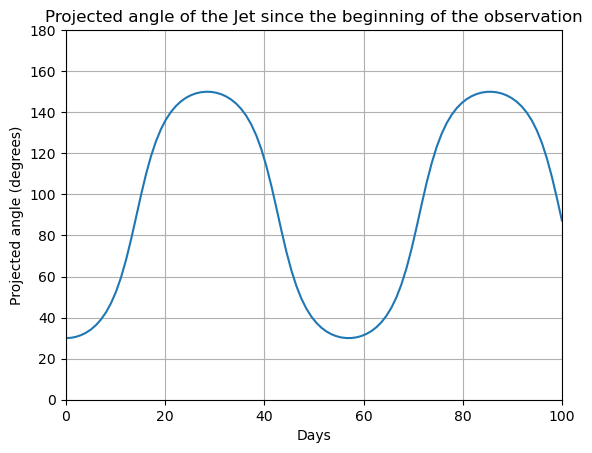

In [7]:
plt.plot(observation_days, projected_angles)
plt.xlim(0,100)
plt.ylim(0,180)
plt.xlabel('Days')
plt.ylabel('Projected angle (degrees)')
plt.title('Projected angle of the Jet since the beginning of the observation')
plt.grid()
plt.show()

Jet Simulation set up: 

- Nucleus: A sphere with a subtle texture.
- Jet: A cone or cylinder pointing outward from a fixed spot.
- Sunlight: A directional light source.
- Earth View: A camera aligned to simulate Earth’s POV.
- Animation Concept:
The nucleus rotates (one full turn = 57 days).
The jet stays fixed on the surface, but rotates with the body.




In [8]:
# Create a unit sphere (nucleus)
u, v = np.mgrid[0:np.pi:60j, 0:2*np.pi:60j] # making the spherical shape

# X,Y and Z coordinates
x = np.sin(u) * np.cos(v)
y = np.sin(u) * np.sin(v)
z = np.cos(u)

In [9]:
# Define jet direction (latitude 30°)
jet_lat, jet_lon = np.radians(30), np.radians(0)
jx = np.cos(jet_lat) * np.cos(jet_lon)
jy = np.cos(jet_lat) * np.sin(jet_lon)
jz = np.sin(jet_lat)
jet_vector = np.array([jx, jy, jz])

Text(0.5, 0.92, '29P model Nucleus')

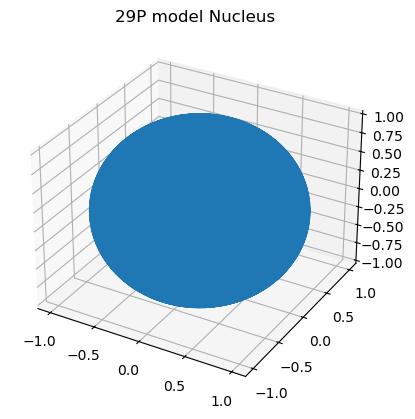

In [10]:
# Animation
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
jet_line, = ax.plot([x], [y], [z], linewidth=10)
plt.title('29P model Nucleus')


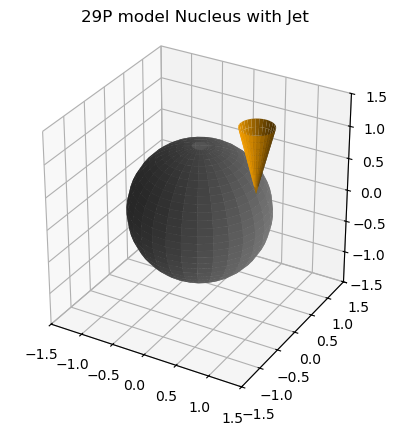

In [11]:
# Create figure and axis
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Sphere (nucleus)
u, v = np.mgrid[0:np.pi:30j, 0:2*np.pi:30j]
x = np.sin(u) * np.cos(v)
y = np.sin(u) * np.sin(v)
z = np.cos(u)
ax.plot_surface(x, y, z, color='grey')

# Jet (cone)
# Cone parameters
cone_height = 1
cone_radius = 0.25
theta = np.linspace(0, 2*np.pi, 30)
r = np.linspace(0, cone_radius, 10)
T, R = np.meshgrid(theta, r)
Xj = R * np.cos(T)
Yj = R * np.sin(T)
Zj = R * 0 + np.linspace(0, cone_height, 10)[:, None]

# Position and rotate the jet at 30° latitude on the sphere
# Direction vector for jet at 30° latitude, 0° longitude
lat = np.radians(30)  # latitude
long = np.radians(0) # longitude
jet_dir = np.array([
    np.cos(lat) * np.cos(long),
    np.cos(lat) * np.sin(long),
    np.sin(lat)])

# Shift jet base to the surface of the sphere
jet_base = jet_dir  # unit radius
jet_tip = jet_base + cone_height * jet_dir

# Translate the jet from origin to the jet_base and align direction
for i in range(Xj.shape[0]):
    for j in range(Xj.shape[1]):
        cone_point = np.array([Xj[i, j], Yj[i, j], Zj[i, j]])
        # Rotate: align with jet_dir
        # Translate:
        Xj[i, j], Yj[i, j], Zj[i, j] = cone_point + jet_base

# Plot the jet
ax.plot_surface(Xj, Yj, Zj, color='orange')

# Labels and limits
ax.set_title('29P model Nucleus with Jet')
ax.set_xlim([-1.5, 1.5])
ax.set_ylim([-1.5, 1.5])
ax.set_zlim([-1.5, 1.5])
ax.set_box_aspect([1,1,1])

plt.show()


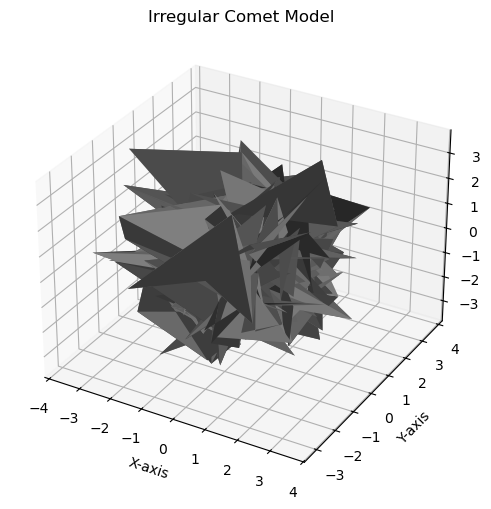

In [12]:
# Add random noise to simulate surface irregularities
noise_factor = 1
x += noise_factor * np.random.normal(size=x.shape)
y += noise_factor * np.random.normal(size=y.shape)
z += noise_factor * np.random.normal(size=z.shape)

# Re-plot with irregularities
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, z, color='grey')

ax.set_title("Irregular Comet Model")
ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_zlabel("Z-axis")

plt.show()


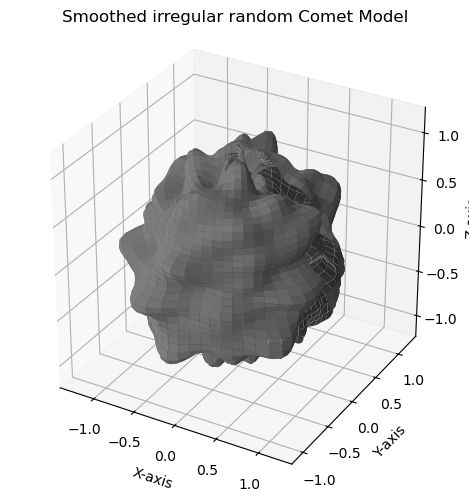

In [13]:
# Base sphere
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)
x = np.outer(np.cos(u), np.sin(v))
y = np.outer(np.sin(u), np.sin(v))
z = np.outer(np.ones_like(u), np.cos(v))

# Add smooth noise
noise_factor = 1
noise = noise_factor * np.random.normal(size=x.shape)
smooth_noise = gaussian_filter(noise, sigma=3)  # Sigma controls smoothness

# Apply noise as radial offset
r = 1 + smooth_noise  # Radial distance
x_irregular = r * x
y_irregular = r * y
z_irregular = r * z

# Plot
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x_irregular, y_irregular, z_irregular, color='gray')

ax.set_title("Smoothed irregular random Comet Model")
ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_zlabel("Z-axis")
ax.set_box_aspect([1, 1, 1])
plt.tight_layout()
plt.show()


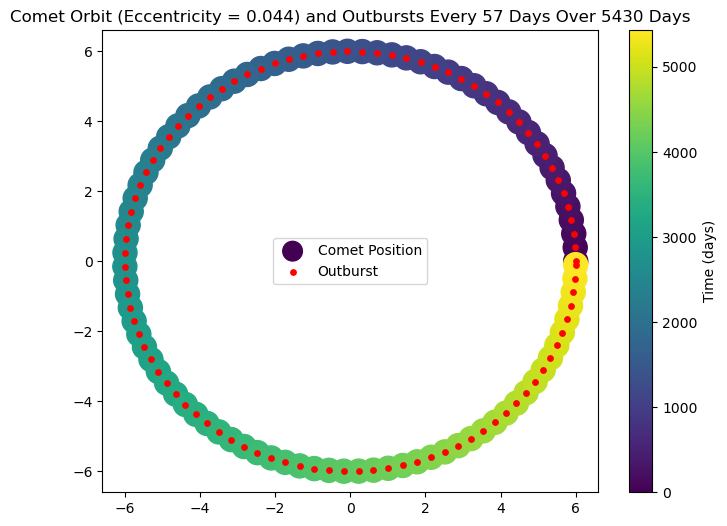

In [14]:
# Simulation parameters
num_days = 5430
time = np.linspace(0, num_days, num=num_days)  # Days from 0 to 5430

# Orbital parameters for an almost circular orbit
eccentricity = 0.044
a = 6  # Semi-major axis in AU
b = a * np.sqrt(1 - eccentricity**2)  # Compute semi-minor axis

# Generate positions of 29P along the orbit using an ellipse parameterization:
# x = a * cos(theta), y = b * sin(theta)
theta = np.linspace(0, 2 * np.pi, num=num_days) 
x_positions = a * np.cos(theta)
y_positions = b * np.sin(theta)

# Simulate outbursts:
# Mark an outburst every 57 days.
outburst = np.array([True if (day % 57 == 0) else False for day in range(num_days)])
brightness = np.ones(num_days)  # Normal brightness for all days
brightness[outburst] = 3   # Increased brightness for outburst days

# Plot the orbit and outbursts:
fig, ax = plt.subplots(figsize=(8, 6))

# Plot comet positions, using 'brightness' to adjust marker size.
scatter = ax.scatter(x_positions, y_positions, 
                     s=brightness * 100, 
                     c=time, 
                     cmap='viridis', 
                     label='Comet Position')

# Highlight positions where an outburst occurred
for i in range(num_days):
    if outburst[i]:
        ax.scatter(x_positions[i], y_positions[i], 
                   s=brightness[i] * 5, 
                   color='red',
                   label='Outburst' if i == 0 else "")


ax.set_title("Comet Orbit (Eccentricity = 0.044) and Outbursts Every 57 Days Over 5430 Days")
ax.legend()
plt.colorbar(scatter, label='Time (days)')

plt.show()


In [15]:
# Simulation parameters for comet 29P
orbital_period = 5430            # Total number of days (~14.87 years)
num_days = orbital_period        # One frame per day

# Time in days
time = np.arange(num_days)

# Orbital parameters for comet 29P
# Observational data:
# Semi-major axis a ≈ 6.0 AU with eccentricity e ≈ 0.044

a = 6.0  # in AU
eccentricity = 0.044
b = a * np.sqrt(1 - eccentricity**2)  # semi-minor axis

# For simplicity, assume uniform motion along the orbit.

theta = np.linspace(0, 2*np.pi, num=num_days)
x_positions = a * np.cos(theta)
y_positions = b * np.sin(theta)

# Define outbursts: The comet experiences an outburst every 57 days.

outburst = np.array([True if (day % 57 == 0) else False for day in time])

# Create a static background trace to display the full orbital path.

base_trace = go.Scatter(
    x=x_positions,
    y=y_positions,
    mode='markers',
    marker=dict(size=4, color='lightgrey'),
    name="Orbital Path")

# Create a static trace to mark all outburst positions with a red dot.

x_outbursts = x_positions[outburst]
y_outbursts = y_positions[outburst]

outburst_trace = go.Scatter(
    x=x_outbursts,
    y=y_outbursts,
    mode='markers',
    marker=dict(size=12, color='red'),
    name="Outbursts")

# Create static traces for the Sun and Earth.

sun_trace = go.Scatter(
    x=[0],
    y=[0],
    mode='markers+text',
    marker=dict(size=20, color='yellow'),
    text=["Sun"],
    textposition='bottom center',
    name="Sun")

earth_trace = go.Scatter(
    x=[1],  # Place Earth at 1 AU from the Sun 
    y=[0],
    mode='markers+text',
    marker=dict(size=12, color='blue'),
    text=["Earth"],
    textposition='bottom center',
    name="Earth")

# Create animation frames: each frame shows the comet's position on that day.
# When an outburst occurs, the marker is highlighted as a red open circle, otherwise blue.

frames = []
for i in range(num_days):
    if outburst[i]:
        marker_color = 'red'
        marker_size = 16
        marker_symbol = 'circle-open'
    else:
        marker_color = 'blue'
        marker_size = 10
        marker_symbol = 'circle'
        
    frame = go.Frame(
        data=[
            go.Scatter(
                x=[x_positions[i]],
                y=[y_positions[i]],
                mode='markers',
                marker=dict(size=marker_size, color=marker_color, symbol=marker_symbol),
                name=f"Day {i}") ],
        name=str(i))
    frames.append(frame)

# Define the layout with slider and play/pause buttons.
# Source: https://www.geeksforgeeks.org/create-multiple-buttons-in-matplotlib/
# Adjust the axis ranges to comfortably display the orbit (in AU).

layout = go.Layout(
    title="Comet 29P Orbit Visualization with 57-Day Outbursts",
    xaxis=dict(range=[-a-2, a+2], title="X Position (AU)", fixedrange=True),
    yaxis=dict(range=[-a-2, a+2], title="Y Position (AU)", fixedrange=True),
    updatemenus=[
        dict(
            type="buttons",
            showactive=False,
            x=0.1,
            y=1.15,
            buttons=[
                dict(
                    label="Play",
                    method="animate",
                    args=[None, {"frame": {"duration": 30, "redraw": True},
                                 "fromcurrent": True,
                                 "transition": {"duration": 30}}]
                ),
                dict(
                    label="Pause",
                    method="animate",
                    args=[[None], {"frame": {"duration": 0, "redraw": False},
                                   "mode": "immediate",
                                   "transition": {"duration": 0}}]
                )
            ]
        )
    ],
    sliders=[{
        "active": 0,
        "currentvalue": {
            "font": {"size": 16},
            "prefix": "Day: ",
            "visible": True,
            "xanchor": "right"
        },
        "pad": {"b": 10, "t": 60},
        "len": 0.9,
        "x": 0.1,
        "y": 0,
        "steps": [
            {
                "label": str(i),
                "method": "animate",
                "args": [
                    [str(i)],
                    {"frame": {"duration": 30, "redraw": True},
                     "mode": "immediate",
                     "transition": {"duration": 30}}
                ]
            } for i in range(num_days)
        ]
    }]
)

# Figure: 
fig = go.Figure(
    data=[base_trace, outburst_trace, sun_trace, earth_trace, frames[0].data[0]],
    layout=layout,
    frames=frames)

fig.show()


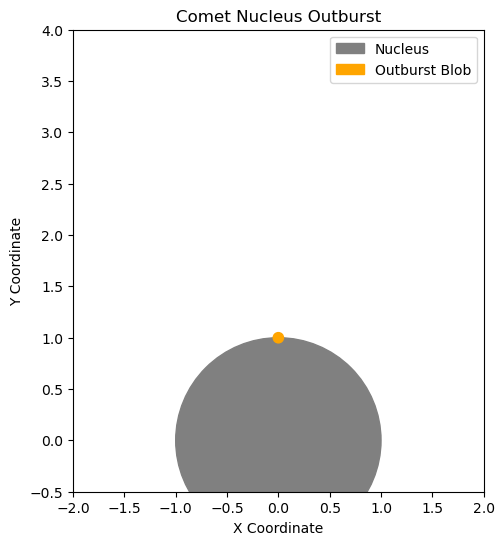

GIF saved to C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_1.gif


In [16]:
# Simulation parameters
duration = 57      # Number of animation frames 
dt = 1         # Time step per frame 

# Nucleus parameters
nucleus_radius = 1.0  # This can later change into the actual value of 29P radius (found in the bibliography)

# Outburst initial conditions:
# Outburst occurs at the top of the nucleus.
start_pos = np.array([0, nucleus_radius])
v0 = np.array([0, 1.0])  # initial velocity (in x and y); upward only
g = -0.25                 # gravitational deceleration (acting in the -y direction)

# Blob evolution parameters:
initial_blob_size = 0.05     # initial radius of the blob
expansion_rate = 0.5         # rate at which the blob expands (grows in radius)
alpha_decay = 0.1            # rate of fading (reduction in alpha per time unit)

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(-2, 2)
ax.set_ylim(-0.5, 4)
ax.set_aspect('equal')
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
plt.title("Comet Nucleus Outburst")

nucleus = plt.Circle((0, 0), nucleus_radius, color='grey', label="Nucleus")
ax.add_patch(nucleus)

# Draw the initial outburst blob with full opacity as an orange circle
blob_circle = plt.Circle(start_pos, initial_blob_size, color='orange', label="Outburst Blob")
ax.add_patch(blob_circle)

ax.legend()

def update(frame):
    t = frame * dt
    # Calculate the blob's new position by basic kinematics:
    # pos = start_pos + v0*t + 0.5 * acceleration * t^2.
    # Since the only acceleration is in the y direction (gravity), add it only to y.
    pos_x = start_pos[0] + v0[0] * t
    pos_y = start_pos[1] + v0[1] * t + 0.5 * g * t**2
    new_pos = (pos_x, pos_y)
    blob_circle.center = new_pos

    # Increase the blob size as it spreads out.
    new_radius = initial_blob_size + expansion_rate * t
    blob_circle.set_radius(new_radius)
    
    # Fade the blob over time (simulate dissipation)
    new_alpha = max(0, 1.0 - alpha_decay * t)
    blob_circle.set_alpha(new_alpha)
    
    return blob_circle,

# Create animation
anim = FuncAnimation(fig, update, frames=duration, interval=50, blit=True)

plt.show()

# Save animation as GIF using PillowWriter
gif_path = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_1.gif"
anim.save(gif_path, writer=PillowWriter(fps=10))  # Adjust FPS for smooth transition

plt.show()

print(f"GIF saved to {gif_path}")


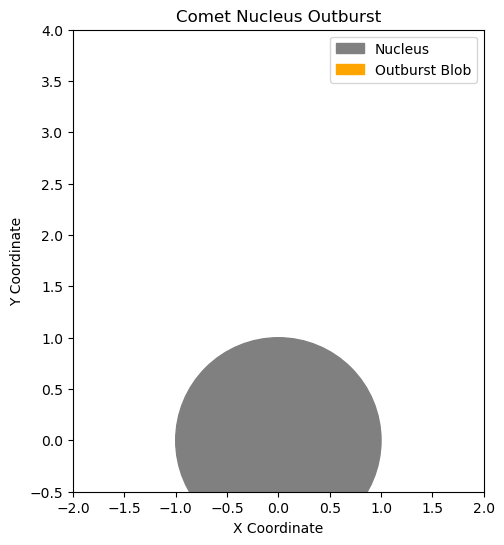

GIF saved to C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_2.gif


In [17]:
# Simulation parameters
duration = 100  # Number of frames (adjusted for smooth animation over 10 seconds)
dt = 0.1        # Time step per frame

# Nucleus parameters
nucleus_radius = 1.0  # Can later be adjusted to match the actual 29P nucleus size

# Outburst initial conditions
start_pos = np.array([0, nucleus_radius])  # Blob starts at the top of the nucleus
v0 = np.array([0, 0.01])  # Initial velocity (only upward)
g = -0.25                # Gravitational deceleration (pulling down)

# Blob evolution parameters
initial_blob_size = 0.1   # Initial blob radius
expansion_rate = 0.75     # Blob expansion rate
alpha_decay = 0.25        # Rate at which blob fades

# Create the figure and axis
fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(-2, 2)
ax.set_ylim(-0.5, 4)
ax.set_aspect('equal')
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
plt.title("Comet Nucleus Outburst")

# Draw the nucleus (starts alone)
nucleus = plt.Circle((0, 0), nucleus_radius, color='grey', label="Nucleus")
ax.add_patch(nucleus)

# Initialize the blob (hidden initially)
blob_circle = plt.Circle(start_pos, initial_blob_size, color='orange', label="Outburst Blob")
ax.add_patch(blob_circle)

ax.legend()

def update(frame):
    t = frame * dt

    # Introduce blob after a delay (e.g., after 10 frames)
    if frame > 10:
        blob_circle.set_alpha(max(0, 1.0 - alpha_decay * t))  # Simulate dissipation
    
        # Compute new position (kinematics: height affected by gravity)
        pos_x = start_pos[0] + v0[0] * t
        pos_y = start_pos[1] + v0[1] * t + 0.5 * g * t**2
        blob_circle.center = (pos_x, pos_y)

        # Expand blob size
        new_radius = initial_blob_size + expansion_rate * t
        blob_circle.set_radius(new_radius)

    return blob_circle,

# Create animation
anim = FuncAnimation(fig, update, frames=duration, interval=100, blit=True)

# Save animation as GIF using PillowWriter
gif_path = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_2.gif"
anim.save(gif_path, writer=PillowWriter(fps=10))  # Adjust FPS for smooth transition

plt.show()

print(f"GIF saved to {gif_path}")


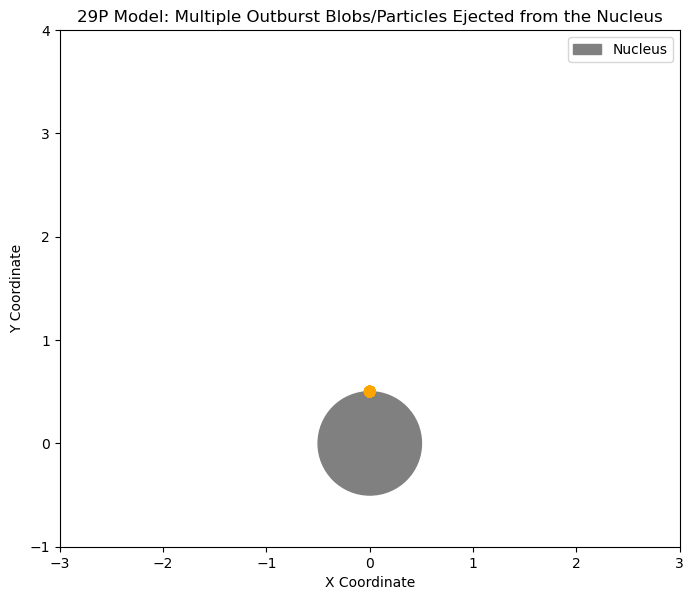

GIF saved to C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_multiple_1.gif


In [18]:
# Simulation parameters
total_frames = 100      # Total frames
dt = 0.1                # Time step per frame in seconds

# Nucleus parameters
nucleus_radius = 0.5       # Smaller nucleus
nucleus_center = (0, 0)    # Centered in the figure

# Outburst origin: at the top of the nucleus
start_pos = np.array([0, nucleus_radius]) 

# Gravity (affects only the vertical dimension)
g = -0.25

# Blob evolution parameters
initial_blob_size = 0.05       # Initial radius of each blob
expansion_rate = 0.5           # Rate at which each blob expands
fade_start = 30                # Frame number at which blobs start fading
alpha_decay = 0.2          # Fade rate per frame (after fade_start)

# Blob ejection parameters
N_total = 50                   # Total number of blobs
N_return = int(N_total / 3)    # Approximately 1/3 will be "return blobs"
N_ring = N_total - N_return    # The other 2/3 will become part of the ring

# Create a list to store each blob's properties
# Each blob will have its own initial velocity vector and a corresponding Circle patch
blob_list = []

# Create returning blobs: these have low upward velocities (minimal horizontal motion)
for i in range(N_return):
    # For a returning blob, we use a modest upward velocity with no horizontal component.
    v0 = np.array([0.0, 0.5])  
    blob_list.append({'type': 'return', 'v0': v0, 'patch': None})

# Create ring blobs: these blobs have a higher upward velocity and a randomized horizontal component.
for i in range(N_ring):
    v0_x = np.random.uniform(-1, 1)    # Random horizontal velocity
    v0_y = 2.0                         # Higher upward velocity
    v0 = np.array([v0_x, v0_y])
    blob_list.append({'type': 'ring', 'v0': v0, 'patch': None})

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-3, 3)
ax.set_ylim(-1, 4)
ax.set_aspect('equal')
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
plt.title("29P Model: Multiple Outburst Blobs/Particles Ejected from the Nucleus")

# Draw the nucleus (as a grey circle) at the center
nucleus = plt.Circle(nucleus_center, nucleus_radius, color='grey', label="Nucleus")
ax.add_patch(nucleus)

# Create the blob patches and add them to the axis
# Initially, all blobs are placed at the start position with full opacity.
for blob in blob_list:
    patch = plt.Circle(start_pos, initial_blob_size, color='orange')
    ax.add_patch(patch)
    blob['patch'] = patch

ax.legend()

def update(frame):
    """
    For each frame, update each blob's position, size (expansion) and brightness (alpha).
    The motion is computed using simple kinematics:
      pos_x = start_x + v0_x * t
      pos_y = start_y + v0_y * t + 0.5 * g * t^2
    """
    t = frame * dt
    for blob in blob_list:
        v0 = blob['v0']
        # Compute new position: note gravity affects only y.
        pos_x = start_pos

# Save the animation as a GIF using PillowWriter.
gif_path = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_multiple_1.gif"
writer = PillowWriter(fps=total_frames / 10)  # 100 frames over 10 seconds gives 10 fps.
anim.save(gif_path, writer=writer)

plt.show()

print(f"GIF saved to {gif_path}")


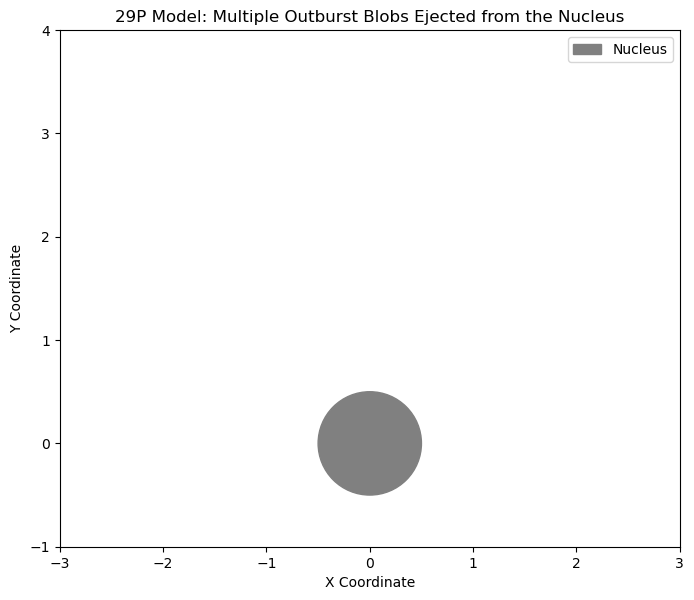

GIF saved to C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_multiple_2.gif


In [19]:
# Simulation parameters
total_frames = 100     # Total frames for a 10-second animation
dt = 0.1               # Time step per frame (in seconds)

# Nucleus parameters
nucleus_radius = 0.5    
nucleus_center = (0, 0)

# Outburst origin: at the top of the nucleus.
start_pos = np.array([0, nucleus_radius])

# Gravity (affects only the vertical component)
g = -0.25

# Blob evolution parameters
initial_blob_size = 0.025      # Initial radius for each blob
expansion_rate = 0.05        # Rate at which each blob expands
fade_start = 30               # Frame number at which blobs start to fade
alpha_decay = 0.25           # Fade rate per frame (after fade_start)

# Blob ejection parameters
N_total = 100                # Total number of blobs
N_return = 30                # 30 blobs will fall back
N_ring = N_total - N_return  # 70 blobs will move outward (form a ring around the core)

# Create a list to store each blob's properties.
# Each blob is characterized by its initial velocity vector and its corresponding Circle patch.
blob_list = []

# Create "return blobs": low upward velocity, minimal (or zero) horizontal velocity.
for i in range(N_return):
    # Lower upward velocity such that gravity eventually pulls them back.
    # You might need to adjust this velocity based on the effect you want.
    v0 = np.array([0.0, 0.8])
    blob_list.append({'type': 'return', 'v0': v0, 'patch': None})

# Create "ring blobs": higher upward velocity with a random horizontal component.
for i in range(N_ring):
    v0_x = np.random.uniform(-1.0, 1.0)   # Random horizontal velocity component
    v0_y = 2.0                            # Higher upward velocity
    v0 = np.array([v0_x, v0_y])
    blob_list.append({'type': 'ring', 'v0': v0, 'patch': None})

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-3, 3)
ax.set_ylim(-1, 4)
ax.set_aspect('equal')
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
plt.title("29P Model: Multiple Outburst Blobs Ejected from the Nucleus")

# Draw the nucleus (grey circle) at the center.
nucleus = plt.Circle(nucleus_center, nucleus_radius, color='grey', label="Nucleus")
ax.add_patch(nucleus)

# Create the blob patches and add them to the axis.
# Initially, all blobs are placed at the outburst start position with full opacity.
for blob in blob_list:
    patch = plt.Circle(start_pos, initial_blob_size, color='orange')
    ax.add_patch(patch)
    blob['patch'] = patch

ax.legend()

def update(frame):
    """
    Update each blob's position, radius, and alpha for each frame.
    The motion formula is:
      pos = start_pos + v0 * t + 0.5 * g * t^2   (with gravity affecting only the vertical component)
    """
    t = frame * dt
    for blob in blob_list:
        v0 = blob['v0']
        # Compute new position; note that gravity only affects y.
        pos_x = start_pos[0] + v0[0] * t
        pos_y = start_pos[1] + v0[1] * t + 0.5 * g * t**2
        blob['patch'].center = (pos_x, pos_y)

        # Update blob radius (expansion)
        new_radius = initial_blob_size + expansion_rate * t
        blob['patch'].set_radius(new_radius)

        # Update blob brightness.
        if frame < fade_start:
            new_alpha = 1.0
        else:
            new_alpha = max(0, 1.0 - alpha_decay * (frame - fade_start))
        blob['patch'].set_alpha(new_alpha)

    # Return a list of all blob patches for efficient blitting.
    return [blob['patch'] for blob in blob_list]

# Create the animation.
anim = FuncAnimation(fig, update, frames=total_frames, interval=dt*1000, blit=True)

# Final segment: Save the animation as a GIF using PillowWriter.
from matplotlib.animation import PillowWriter  # Ensure this is imported at the top.
gif_path = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_multiple_2.gif"
writer = PillowWriter(fps=total_frames/10)  # 100 frames over 10 seconds → 10 fps.
anim.save(gif_path, writer=writer)

plt.show()

print(f"GIF saved to {gif_path}")


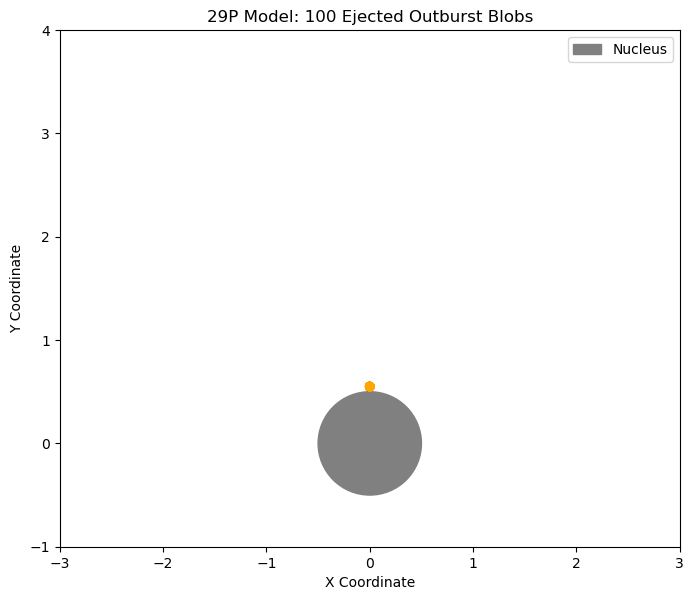

GIF saved to C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_multiple_3.gif


In [20]:
# Simulation parameters
total_frames = 100     # Total frames for a 10-second animation
dt = 0.1               # Time step per frame (in seconds)

# Nucleus parameters
nucleus_radius = 0.5    # Reduced nucleus size
nucleus_center = (0, 0) # Centered in the figure

# Outburst origin: at the top of the nucleus.
start_pos = np.array([0, nucleus_radius])

# Blob evolution parameters
initial_blob_size = 0.03      # Initial blob radius
expansion_rate = 0.001         # Rate at which each blob expands

# Blob ejection parameters
N_total = 100                # Total number of blobs
N_return = 30                # 30 blobs will fall back (return blobs)
N_ring = N_total - N_return  # 70 blobs will travel outward and then come back

# Define gravitational decelerations (mimicking a pull toward the nucleus)
g_return = -0.1   # For blobs intended to slowly return
g_ring = -0.5     # For blobs intended to arc outward and then fall back quickly

# Create a list to store each blob's properties.
# Each blob will be defined by its type, its initial velocity, and its Circle patch.
blob_list = []

# Create "return blobs": low upward velocity (and no horizontal motion)
for i in range(N_return):
    v0 = np.array([0.0, 0.5])
    blob_list.append({'type': 'return', 'v0': v0, 'patch': None})

# Create "ring blobs": higher upward velocity plus a random horizontal component.
for i in range(N_ring):
    v0_x = np.random.uniform(-1.0, 1.0)   # Random horizontal velocity component
    v0_y = 1.0                            # Higher upward velocity
    v0 = np.array([v0_x, v0_y])
    blob_list.append({'type': 'ring', 'v0': v0, 'patch': None})

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-3, 3)
ax.set_ylim(-1, 4)
ax.set_aspect('equal')
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
plt.title("29P Model: 100 Ejected Outburst Blobs")

# Draw the nucleus (as a grey circle) at the center.
nucleus = plt.Circle(nucleus_center, nucleus_radius, color='grey', label="Nucleus")
ax.add_patch(nucleus)

# Create and add the blob patches to the axis. 
# All blobs start at the outburst origin with full opacity.
for blob in blob_list:
    patch = plt.Circle(start_pos, initial_blob_size, color='orange')
    ax.add_patch(patch)
    blob['patch'] = patch

ax.legend()

def update(frame):
    """
    Update the position, radius, and brightness (alpha) of each blob.
    Each blob follows simple kinematics:
      pos = start_pos + v0*t + 0.5*g_effect*t^2
    where g_effect depends on the blob type.
    """
    t = frame * dt
    for blob in blob_list:
        v0 = blob['v0']
        # Use different gravitational acceleration for ring vs. return blobs.
        if blob['type'] == 'ring':
            g_effect = g_ring
        else:
            g_effect = g_return

        # Compute new position (gravity only affects y).
        pos_x = start_pos[0] + v0[0] * t
        pos_y = start_pos[1] + v0[1] * t + 0.5 * g_effect * t**2
        blob['patch'].center = (pos_x, pos_y)

        # Update blob radius (expansion).
        new_radius = initial_blob_size + expansion_rate * t
        blob['patch'].set_radius(new_radius)

        # In this updated simulation, all blobs remain fully opaque (alpha=1).
        blob['patch'].set_alpha(1.0)

    # Return list of all patches for efficient updating.
    return [blob['patch'] for blob in blob_list]

# Create the animation.
anim = FuncAnimation(fig, update, frames=total_frames, interval=dt*1000, blit=True)

# Final segment: Save the animation as a GIF using PillowWriter.
from matplotlib.animation import PillowWriter  # Ensure PillowWriter is imported.
gif_path = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation\comet_outburst_multiple_3.gif"
writer = PillowWriter(fps=total_frames/10)  # 100 frames over 10 seconds → 10 fps.
anim.save(gif_path, writer=writer)

plt.show()

print(f"GIF saved to {gif_path}")


Using the Particle model to add Physics and make it more accurate:  

Key Information 
Outburst area = 1 km (diameter)
Comet radius = 30 km (60.4±7.4 kilometers in diameter)
Density = 500 kg/m^3 (Estimated value according to other accurate measurements of 67P/Churyumov–Gerasimenko)

Table 1 from 
Sources: 
•	Dust Outburst Dynamics and Hazard Assessment for Close Spacecraft–Comet Encounters
•	Evolution of the dust trail of comet 17P/Holmes


In [21]:
# Estimating the Mass of 29P/Schwassmann–Wachmann:
π = np.pi
r = 30                         # in km  
rho_29P = 500                  # in kg/m^3

V_sphere = 4/3*π*(r*1000)**3
M_29P = rho_29P * V_sphere 

print(f'The estimated mass of 29P in [kg] is: {M_29P:.2e} kg')

The estimated mass of 29P in [kg] is: 5.65e+16 kg


In [22]:
# Estimating the Mass of an outburst/ ejected material: 
# Assume the change in magnitude/brightness is 1 mag 
# Assume that the expansion velocity is v = 100m/s 
# Assume the albedo of dust particle is alpha = 0.04 (Lamy, P., Toth, I., Fernández, Y.R., & Weaver, H.A. (2004))

delta_mag = 1.0             # brightness increase in magnitudes
v_exp = 100.0               # expansion velocity in m/s
albedo = 0.04               # assumed albedo 
A0 = 1e8                    # cross-sectional area (in m^2)
a = 1e-3                    # effective dust grain radius in m (1 mm)
rho_dust = 1000.0           # dust density in kg/m^3

# A brightness change of 1 mag means the flux increases by a factor 10^(0.4*1) ~ 2.512
# If brightness is proportional to cross-sectional area then:
delta_A = A0 * (10**(0.4 * delta_mag) - 1)

# Calculate mass-to-area ratio for spherical particles.
# For a single particle: mass m = (4/3) * π * a^3 * rho_dust, cross-sectional area A_part = π * a^2.
mass_area_ratio = (4.0 / 3.0) * a * rho_dust  # in kg/m^2

# Estimate the ejected dust mass
mass_ejected = delta_A * mass_area_ratio

print(f'Estimated mass of ejected material: {mass_ejected:.2e} kg')


Estimated mass of ejected material: 2.02e+08 kg


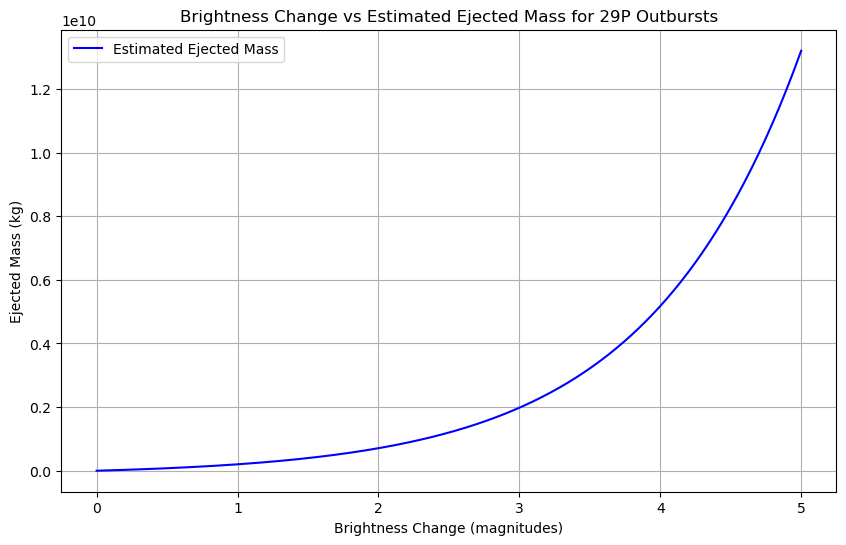

In [23]:
# Mass-to-area ratio for spherical grains:
mass_per_area = (4/3) * a * rho_dust

# Define a range of brightness changes (in magnitudes)
# For example, from 0 (no change) up to 5 magnitudes- typical for 29P.
delta_mags = np.linspace(0, 5, 300)

# Compute the extra cross-sectional area due to the brightness increase:
delta_A = A0 * (10**(0.4 * delta_mags) - 1)

# Estimate the ejected dust mass:
mass_ejected = delta_A * mass_per_area

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(delta_mags, mass_ejected, color='blue', label='Estimated Ejected Mass')
plt.xlabel("Brightness Change (magnitudes)")
plt.ylabel("Ejected Mass (kg)")
plt.title("Brightness Change vs Estimated Ejected Mass for 29P Outbursts")
plt.grid(True)
plt.legend()
plt.show()

In [24]:
# Estimating the acceleration of the ejected particles 
# Assume the velocity is constant at v_eject = 100 m/s 

C_d = 2.0                    # Drag coefficient (dimensionless)
v_eject = 100.0              # Relative velocity (or gas velocity) in m/s

# Assumed gas density near the nucleus during the outburst. 
rho_gas = 5e-3            # in kg/m^3

# Calculate the acceleration using the derived formula:
# Force (drag) = m_dust * acceleration = 1/2 C_d * π * a^2 * rho_dust * v^2 
# Rearrange above for acceleration. The equation is directly put to the ideal form in respect to the acceleration. 
acceleration = (3 * C_d * rho_gas * v_eject**2) / (8 * a * rho_dust)

print(f"With rho_gas = {rho_gas:.3e} kg/m^3, the estimated acceleration is: {acceleration:.2f} m/s^2")


With rho_gas = 5.000e-03 kg/m^3, the estimated acceleration is: 37.50 m/s^2


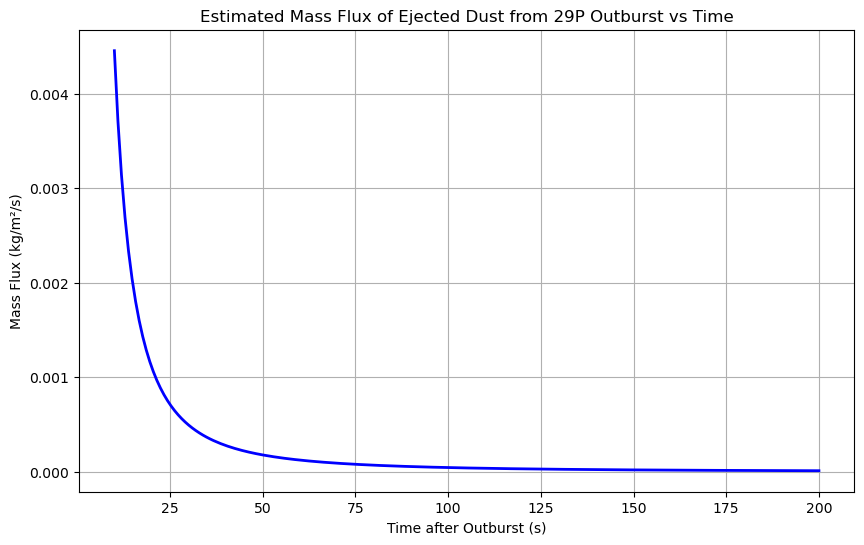

Total ejected mass, M_ejected = 2.02e+08 kg
Average mass ejection rate, M_dot = 5.60e+04 kg/s


In [25]:
# Re-write parameters   (same as the ones used earlier)
delta_m = 1.0           # Brightness increase in magnitudes during the outburst
A0 = 1e8                # Baseline scattering cross-sectional area in m² (assumed)
a = 1e-3                # Effective dust grain radius in m (1 mm)
rho_dust = 1000.0       # Dust grain density in kg/m³
v = 100.0               # Expansion (ejection) velocity in m/s

duration = 3600         # Duration of the outburst in seconds

# Compute Extra Scattering Cross-Section
# A brightness change increases the flux by a factor: 10^(0.4Δm)
# Under the assumption that brightness ∝ area, the extra area is:
delta_A = A0 * (10**(0.4 * delta_m) - 1)

# Compute the Total Ejected Mass
# For spherical particles, mass-to-area ratio is: (4/3)*a*rho_dust
mass_per_area = (4/3) * a * rho_dust
# Total ejected dust mass:
M_ejected = delta_A * mass_per_area  # in kg

# Compute the Mass Ejection Rate
M_dot = M_ejected / duration         # in kg/s

# Calculate Mass Flux as a Function of Time
# At a time 't' after the outburst, the particles have traveled a distance R = v * t.
# For an isotropic ejection, they are spread over a sphere of area 4πR².
# The mass flux (kg/m²/s) at distance R is then:
# Flux(R) = M_dot / 4 × π × (v*t)².
times = np.linspace(10, 200, 200)   # time in seconds after the outburst
R = v * times                       # distance in meters
flux = M_dot / (4 * np.pi * R**2)     # mass flux at distance R (kg/m²/s)

# Plot the Mass Flux vs Time
plt.figure(figsize=(10, 6))
plt.plot(times, flux, color='blue', lw=2)
plt.xlabel("Time after Outburst (s)")
plt.ylabel("Mass Flux (kg/m²/s)")
plt.title("Estimated Mass Flux of Ejected Dust from 29P Outburst vs Time")
plt.grid(True)
plt.show()

print(f"Total ejected mass, M_ejected = {M_ejected:.2e} kg")
print(f"Average mass ejection rate, M_dot = {M_dot:.2e} kg/s")


In [26]:
# Estimating the Luminosity/ Reflectivity of the dust particles: 
delta_m = 1.0          # Brightness change during outburst (in magnitudes)
A0 = 1e8               # Baseline scattering cross-sectional area in m^2
albedo = 0.04          # Assumed effective albedo of dust
r_h = 6.0              # Distance from the Sun in AU

# Solar flux at 1 AU (W/m^2), then reduced by 1/r_h^2 at comet's distance.
F_sun_1AU = 1361              # W/m^2 (This value can be googled)
F_sun = F_sun_1AU / (r_h**2)  # W/m^2 at r_h AU

# Calculate Extra Scattering Cross-Section
# A 1-mag change corresponds to an increase in flux (and area) by a factor of 10^(0.4*delta_m)
delta_A = A0 * (10**(0.4 * delta_m) - 1)  # in m^2

# Estimate the Luminosity
# The total luminosity scattered by the dust is roughly:
# L_dust = albedo * (F_sun * delta_A)
L_dust = albedo * F_sun * delta_A         # in Watts

print(f"Extra scattering cross-sectional area, Delta A: {delta_A:.2e} m^2")
print(f"Solar flux at {r_h} AU: {F_sun:.2f} W/m^2")
print(f"Estimated luminosity of the ejected dust: {L_dust:.2e} Watts")


Extra scattering cross-sectional area, Delta A: 1.51e+08 m^2
Solar flux at 6.0 AU: 37.81 W/m^2
Estimated luminosity of the ejected dust: 2.29e+08 Watts


Now I will try to apply these on the last particle model I had generated above: 


##################################################################################################################################################################################

Animation saved successfully as C:\Users\stels\OneDrive\Desktop\MSc Dissertation\29P_outburst_final_draft_1.gif


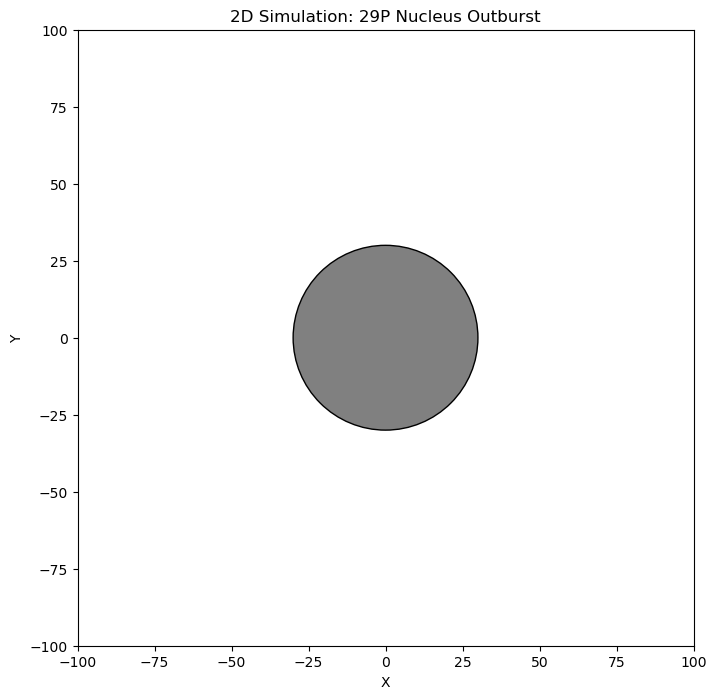

In [27]:
data_directory = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation"
output_file = os.path.join(data_directory, "29P_outburst_final_draft_1.gif")

# Simulation parameters
nucleus_radius = 30         # Radius of 29P nucleus (km)
n_particles = 100           # Number of dust particles ejected
v_eject = 100.0             # Ejection speed (m/s)
simulation_duration = 10    # Total simulation time in seconds
fps = 30                    # Frames per second for animation

# Create the nucleus
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')

# Create a filled circle to represent the nucleus
nucleus = plt.Circle((0, 0), nucleus_radius, color='grey', ec='black', zorder=1)
ax.add_patch(nucleus)

ax.set_xlim(-100, 100)
ax.set_ylim(-100, 100)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("2D Simulation: 29P Nucleus Outburst")

# Define the eruption point on the nucleus surface
eruption_angle = np.deg2rad(45)
eruption_point = np.array([nucleus_radius * np.cos(eruption_angle),
                           nucleus_radius * np.sin(eruption_angle)])

# Generate dust ejection directions for each particle
# The outward (radial) direction from the eruption point is the same as eruption_angle.
# Add a random deviation uniformly between -90° and +90°.
deviations_deg = np.random.uniform(-90, 90, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
# Compute the ejection angles for each particle
ejection_angles = eruption_angle + deviations_rad
# Compute unit velocity vectors from these angles
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)
velocities = np.column_stack((vx, vy))

# All particles have the same starting position
initial_positions = np.tile(eruption_point, (n_particles, 1))

# Plot the initial dust positions as red dots
dust_scatter = ax.scatter(initial_positions[:, 0], initial_positions[:, 1],
                          color='red', s=20, zorder=2)

# Animation update function
def update(frame):
    t = frame / fps  # time in seconds
    # New positions: initial position + (v_eject * t * velocity_vector)
    new_positions = initial_positions + v_eject * t * velocities
    dust_scatter.set_offsets(new_positions)
    return dust_scatter,

# Create the animation
n_frames = int(simulation_duration * fps)
ani = animation.FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=True)

try:
    ani.save(output_file, writer='pillow', fps=fps)
    print(f"Animation saved successfully as {output_file}")
except Exception as e:
    print("Error saving animation:", e)

plt.show()


Animation saved successfully as C:\Users\stels\OneDrive\Desktop\MSc Dissertation\29P_outburst_with_gaussian_velocity.gif


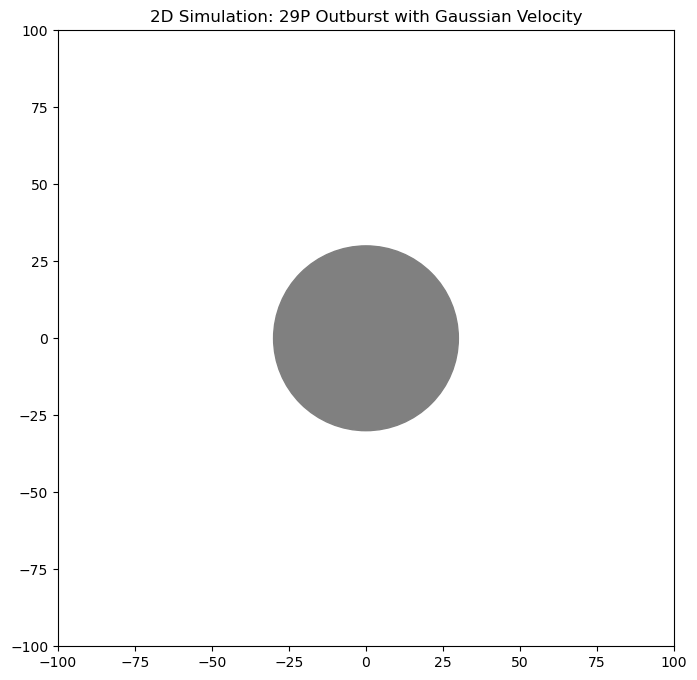

In [28]:
data_directory = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation"
output_file = os.path.join(data_directory, "29P_outburst_with_gaussian_velocity.gif")

# Simulation parameters:
nucleus_radius = 30         # Radius of 29P nucleus (km)
n_particles = 100           # Number of dust particles ejected
v_mean = 100                # Mean ejection speed (m/s)
v_std = 20                  # Standard deviation for ejection speed (m/s)
simulation_duration = 10    # Total simulation time in seconds
fps = 30                    # Frames per second for animation

# Create the nucleus:
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')

# Represent the nucleus:
nucleus = plt.Circle((0, 0), nucleus_radius, color='grey')
ax.add_patch(nucleus)

ax.set_xlim(-100, 100)
ax.set_ylim(-100, 100)
ax.set_title("2D Simulation: 29P Outburst with Gaussian Velocity")

# Define the eruption point on the nucleus surface:
eruption_angle = np.deg2rad(45)
eruption_point = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

# Generate dust ejection directions for each particle:
deviations_deg = np.random.uniform(-90, 90, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad

# Compute unit velocity vectors from ejection angles:
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)

# Gaussian-distributed ejection speeds:
v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)  # prevent negative velocities

# Combine directions with magnitudes:
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

# All particles have the same starting position (eruption point):
initial_positions = np.tile(eruption_point, (n_particles, 1))

# Plot the initial dust positions as red dots:
dust_scatter = ax.scatter(initial_positions[:, 0], initial_positions[:, 1],
                          color='red', s=20, zorder=2)

def update(frame):
    t = frame / fps  # time in seconds
    new_positions = initial_positions + velocities * t
    dust_scatter.set_offsets(new_positions)
    return dust_scatter,

# Create the animation:
n_frames = int(simulation_duration * fps)
ani = animation.FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=True)

try:
    ani.save(output_file, writer='pillow', fps=fps)
    print(f"Animation saved successfully as {output_file}")
except Exception as e:
    print("Error saving animation:", e)

plt.show()


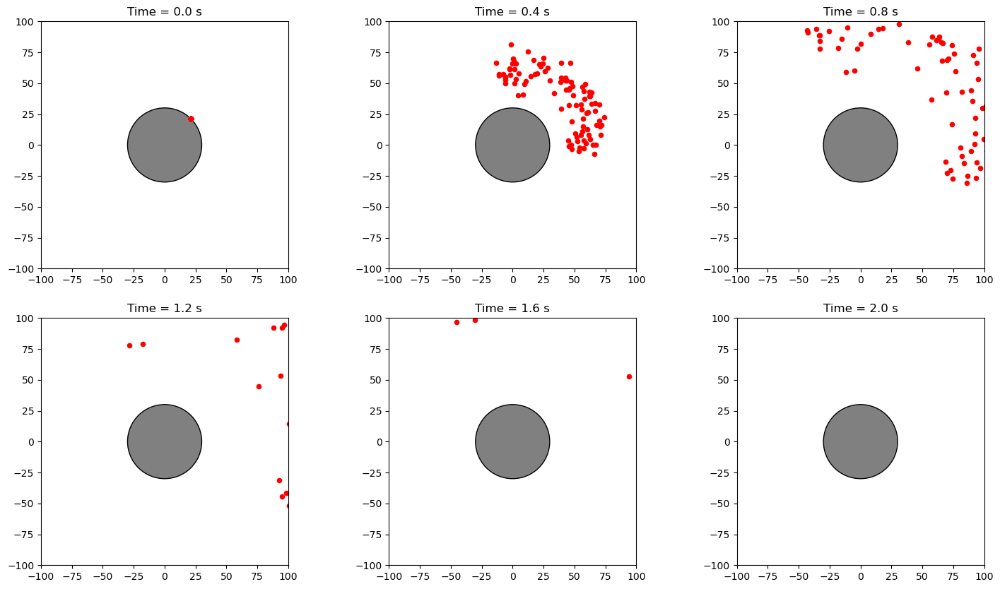

In [29]:
# Generate 6 snapshots of the same code as above but showing each step using the Gaussian velocity distribution 
nucleus_radius = 30         # Radius of 29P nucleus (km)
n_particles = 100           # Number of dust particles ejected
v_mean = 100.0              # Mean ejection speed (m/s)
v_std = 20.0                # Standard deviation (m/s)
simulation_duration = 2     # Total simulation time in seconds
snapshot_times = np.linspace(0, simulation_duration, 6)  # 6 snapshots

eruption_angle = np.deg2rad(45)
eruption_point = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

deviations_deg = np.random.uniform(-90, 90, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad

vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)

v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

initial_positions = np.tile(eruption_point, (n_particles, 1))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, t in enumerate(snapshot_times):
    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"Time = {t:.1f} s")
    
    nucleus = plt.Circle((0, 0), nucleus_radius, color='grey', ec='black', zorder=1)
    ax.add_patch(nucleus)

    positions = initial_positions + velocities * t
    ax.scatter(positions[:, 0], positions[:, 1], color='red', s=20, zorder=2)
plt.show()


Animation saved successfully as C:\Users\stels\OneDrive\Desktop\MSc Dissertation\29P_outburst_cone60deg.gif


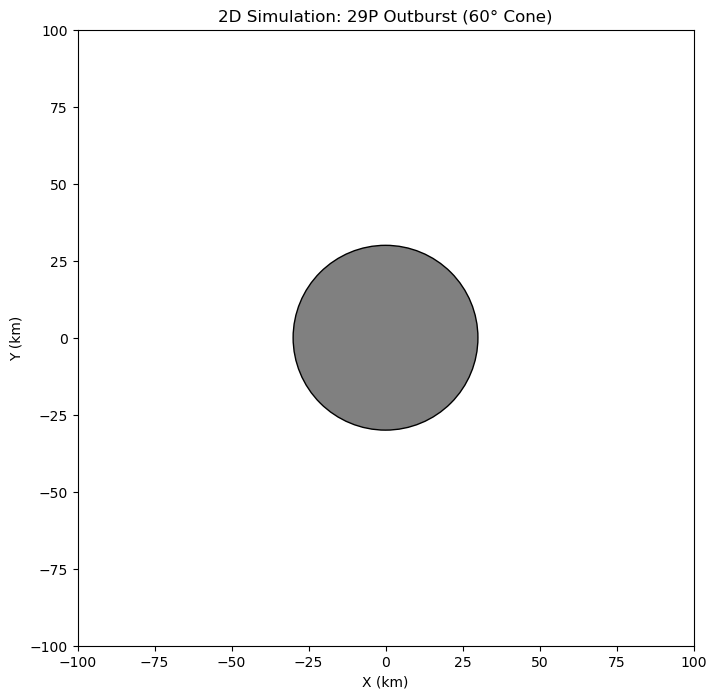

In [30]:
# Output setup for GIF
data_directory = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation"
output_file = os.path.join(data_directory, "29P_outburst_cone60deg.gif")

# Simulation parameters:
nucleus_radius = 30         # Radius of 29P nucleus (km)
n_particles = 100           # Number of dust particles ejected
v_mean = 100.0              # Mean ejection speed (m/s)
v_std = 20.0                # Standard deviation for ejection speed (m/s)
simulation_duration = 10    # Total simulation time in seconds
fps = 30                    # Frames per second for animation

# Define eruption direction:
eruption_angle = np.deg2rad(45)  # central angle of eruption in radians
eruption_point = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

# Generate ejection angles within a 60° cone (±30°):
cone_half_angle = 30  # degrees
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad

# Compute unit velocity vectors:
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)

# Gaussian-distributed ejection speeds:
v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)  # remove any negative speeds

# Final velocity vectors:
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

# All particles start from the eruption point:
initial_positions = np.tile(eruption_point, (n_particles, 1))

# Set up plot:
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')
ax.set_xlim(-100, 100)
ax.set_ylim(-100, 100)
ax.set_xlabel("X (km)")
ax.set_ylabel("Y (km)")
ax.set_title("2D Simulation: 29P Outburst (60° Cone)")

nucleus = plt.Circle((0, 0), nucleus_radius, color='grey', ec='black', zorder=1)
ax.add_patch(nucleus)

# Initialize scatter plot for dust particles:
dust_scatter = ax.scatter(initial_positions[:, 0], initial_positions[:, 1],
                          color='red', s=20, zorder=2)

# Animation update function:
def update(frame):
    t = frame / fps  # current time in seconds
    new_positions = initial_positions + velocities * t
    dust_scatter.set_offsets(new_positions)
    return dust_scatter,

n_frames = int(simulation_duration * fps)
ani = animation.FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=True)

try:
    ani.save(output_file, writer='pillow', fps=fps)
    print(f"Animation saved successfully as {output_file}")
except Exception as e:
    print("Error saving animation:", e)

plt.show()


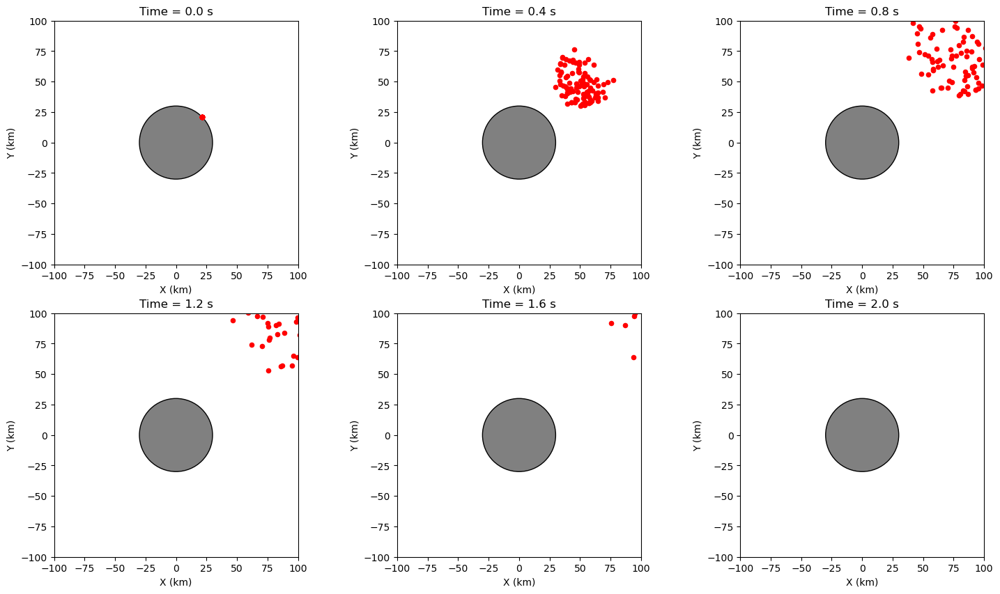

In [31]:
nucleus_radius = 30         # Radius of 29P nucleus (km)
n_particles = 100           # Number of dust particles ejected
v_mean = 100.0              # Mean ejection speed (m/s)
v_std = 20.0                # Standard deviation (m/s)
snapshot_times = np.linspace(0, 2, 6)  # 6 snapshots

eruption_angle = np.deg2rad(45)
eruption_point = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

cone_half_angle = 30  # degrees
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad

vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)

v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

initial_positions = np.tile(eruption_point, (n_particles, 1))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, t in enumerate(snapshot_times):
    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"Time = {t:.1f} s")
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")

    nucleus = plt.Circle((0, 0), nucleus_radius, color='grey', ec='black', zorder=1)
    ax.add_patch(nucleus)

    positions = initial_positions + velocities * t
    ax.scatter(positions[:, 0], positions[:, 1], color='red', s=20, zorder=2)

plt.show()


##################################################################################################################################################################################

In [32]:
# Estimating the Gravity due to the comet: 
# Physical constants and comet parameters:
G = 6.67e-11            # gravitational constant in m^3 kg^-1 s^-2
nucleus_radius_km = 30  # in km
nucleus_radius = nucleus_radius_km * 1e3  # convert to meters (30000 m)
rho_29P = 500           # density in kg/m³ (also introduced above)

# Compute gravitational acceleration at the surface:
a_surface = G * M_29P / (nucleus_radius**2)
print("Gravitational acceleration at the comet's surface:")
print("{:.4e} m/s²".format(a_surface))

# Assume a dust particle mass- all ejected particles have the same size. 
m_dust = 1e-6  # mass in kg
F_gravity = m_dust * a_surface
print("\nGravitational force on a particle of mass {:.2e} kg:".format(m_dust))
print("{:.4e} N".format(F_gravity))


Gravitational acceleration at the comet's surface:
4.1909e-03 m/s²

Gravitational force on a particle of mass 1.00e-06 kg:
4.1909e-09 N


Animation saved successfully as C:\Users\stels\OneDrive\Desktop\MSc Dissertation\29P_outburst_with_gravity_fixed.gif


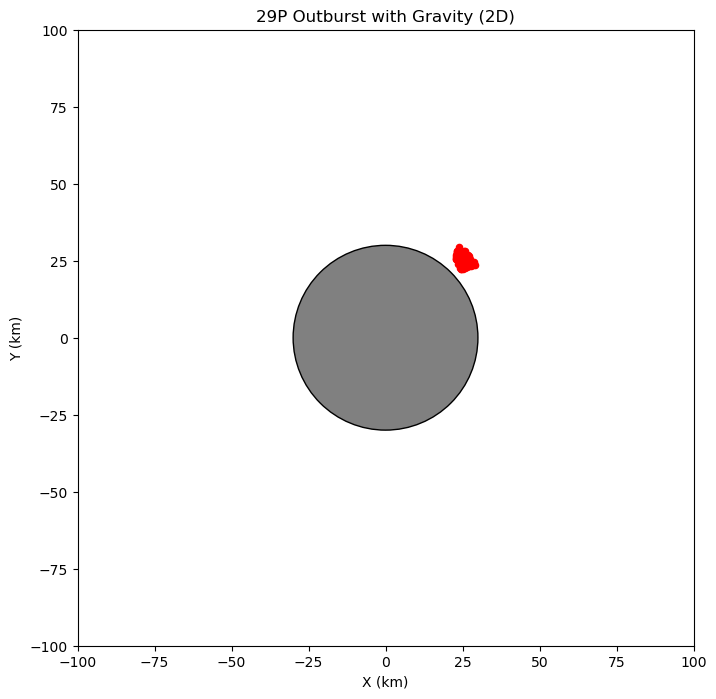

In [33]:
data_directory = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation"
output_file = os.path.join(data_directory, "29P_outburst_with_gravity_fixed.gif")

# Physical constants and nucleus properties
G = 6.67e-11                     # Gravitational constant (m³/kg/s²)
nucleus_radius_km = 30           # Nucleus radius in km
nucleus_radius = nucleus_radius_km * 1e3  # Convert to meters
nucleus_density = 500            # kg/m³
nucleus_volume = (4/3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume  # kg

# Simulation parameters (Increased the mean velocity so the simulation happens faster)
n_particles = 100
v_mean = 100.0                   # Mean ejection speed (m/s)
v_std = 20.0                     # Standard deviation (m/s)
simulation_duration = 60         # Total simulation time (s)
fps = 30
dt = 1 / fps                     # Time step (s)
n_frames = int(simulation_duration * fps)

# Define eruption angle and location
eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

# Ejection angle cone (±30°)
cone_half_angle = 30
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad

# Direction vectors
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)

# Ejection speeds (Gaussian)
v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

# Initial positions (all start at eruption point, in meters)
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)

# Set up plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')
ax.set_xlim(-100, 100)  # in km
ax.set_ylim(-100, 100)
ax.set_xlabel("X (km)")
ax.set_ylabel("Y (km)")
ax.set_title("29P Outburst with Gravity (2D)")

# Draw nucleus (in km)
nucleus = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1)
ax.add_patch(nucleus)

# Initial scatter plot (convert positions to km for plotting)
dust_scatter = ax.scatter(positions[:, 0] / 1e3, positions[:, 1] / 1e3,
                          color='red', s=20, zorder=2)

# Update function for animation
def update(frame):
    global positions, velocities

    # Distance to nucleus
    r_vec = positions
    r = np.linalg.norm(r_vec, axis=1).reshape(-1, 1)
    r = np.maximum(r, nucleus_radius)

    # Gravitational acceleration
    acc = -G * nucleus_mass / r**3 * r_vec

    # Euler integration
    velocities += acc * dt
    positions += velocities * dt

    # Update scatter plot (convert meters to km)
    dust_scatter.set_offsets(positions / 1e3)
    return dust_scatter,

# Create animation
ani = animation.FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=True)

# Save as GIF
try:
    ani.save(output_file, writer='pillow', fps=fps)
    print(f"Animation saved successfully as {output_file}")
except Exception as e:
    print("Error saving animation:", e)

plt.show()


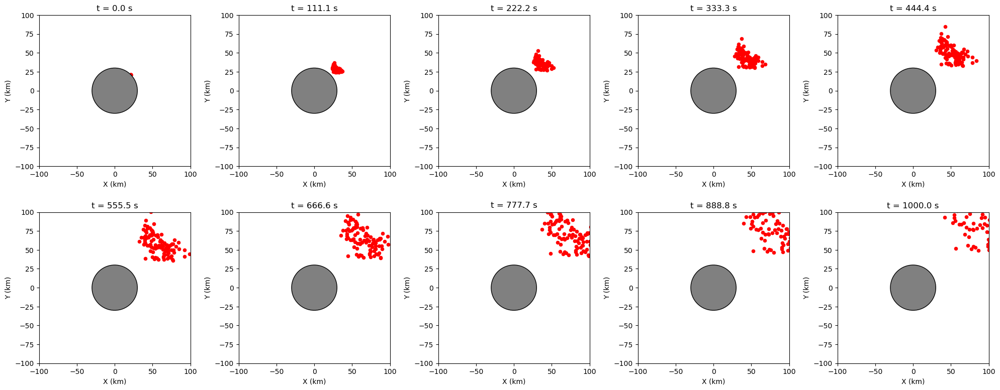

In [34]:
# Same code as above but with 10 snapshots
G = 6.67e-11                     # Gravitational constant (m³/kg/s²)
nucleus_radius_km = 30           # Nucleus radius in km
nucleus_radius = nucleus_radius_km * 1e3  # Convert to meters
nucleus_density = 500            # kg/m³
nucleus_volume = (4/3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume  # kg

n_particles = 100
v_mean = 100.0                   # Mean ejection speed (m/s)
v_std = 20.0                     # Standard deviation (m/s)
simulation_duration = 1000        # Total simulation time (s)
fps = 30
dt = 1 / fps                     # Time step (s)
n_frames = int(simulation_duration * fps)

eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

cone_half_angle = 30  # degrees
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad

vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)

v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)

def update_simulation():
    global positions, velocities
    # Compute the vector from the nucleus center to each particle (in meters)
    r_vec = positions
    # Compute distances; avoid division by very small numbers by enforcing a minimum r (the nucleus radius)
    r = np.linalg.norm(r_vec, axis=1).reshape(-1, 1)
    r = np.maximum(r, nucleus_radius)
    
    # Gravitational acceleration: a = -G * M / r^3 * r_vec
    acc = -G * nucleus_mass / r**3 * r_vec
    
    # Euler integration:
    velocities += acc * dt
    positions += velocities * dt

snapshot_indices = np.linspace(0, n_frames - 1, 10, dtype=int)  # indices for 10 snapshots
snapshots = []  # list to store the positions (in meters) at each snapshot

for frame in range(n_frames):
    update_simulation()
    if frame in snapshot_indices:
        snapshots.append(positions.copy())

fig, axs = plt.subplots(2, 5, figsize=(20, 8))
axs = axs.flatten()

for i, snapshot in enumerate(snapshots):
    ax = axs[i]
    ax.set_aspect('equal')
    # Convert positions from meters to kilometers for easier visualization.
    snapshot_km = snapshot / 1e3
    ax.scatter(snapshot_km[:, 0], snapshot_km[:, 1], color='red', s=20)
    # Draw nucleus as a filled grey circle with a black edge.
    nucleus_circle = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1, fill=True)
    ax.add_patch(nucleus_circle)
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    time_snapshot = snapshot_indices[i] / fps
    ax.set_title(f"t = {time_snapshot:.1f} s")
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")

plt.tight_layout()
plt.show()


Animation saved successfully as C:\Users\stels\OneDrive\Desktop\MSc Dissertation\29P_outburst_with_gravity_different_sized_particles.gif


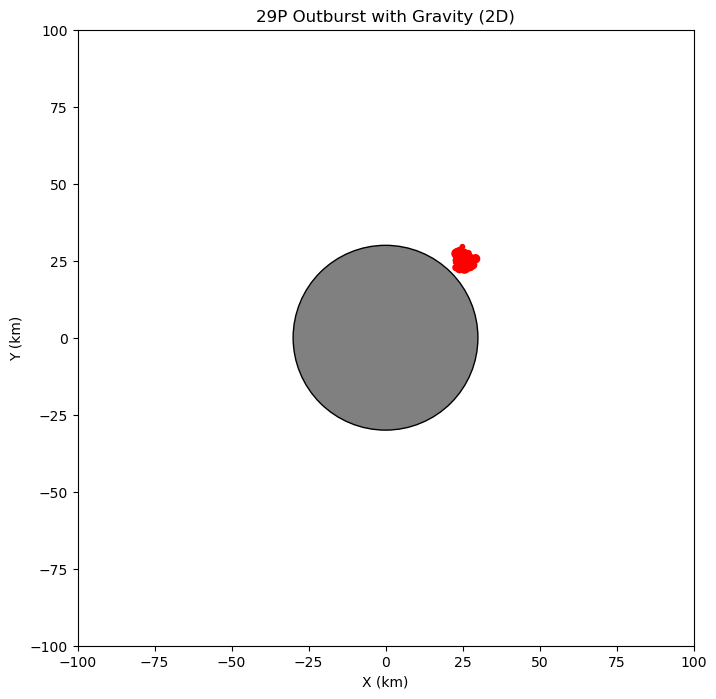

In [35]:
# Introducing different sized particles with Gaussian distribution for the sizes. Average size is 1e-6 m. 
# Directory and output file settings
data_directory = r"C:\Users\stels\OneDrive\Desktop\MSc Dissertation"
output_file = os.path.join(data_directory, "29P_outburst_with_gravity_different_sized_particles.gif")

# Physical constants and nucleus properties
G = 6.67e-11                     # Gravitational constant (m³/kg/s²)
nucleus_radius_km = 30           # Nucleus radius in km
nucleus_radius = nucleus_radius_km * 1e3  # Convert to meters
nucleus_density = 500            # kg/m³ (typical nucleus density)
nucleus_volume = (4/3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume  # kg

# Simulation parameters
n_particles = 100
v_mean = 100.0                   # Mean ejection speed (m/s)
v_std = 20.0                     # Standard deviation of ejection speed (m/s)
simulation_duration = 60         # Total simulation time (s)
fps = 30
dt = 1 / fps                   # Time step (s)
n_frames = int(simulation_duration * fps)

# Particle size and mass properties
# Set the average diameter to 1e-3 mm = 1e-6 m.
mean_diameter = 1e-6             # in meters (1 micrometer)
sigma_diameter = 0.3e-6          # standard deviation in meters
# Gaussian distribution for particle diameters
particle_diameters = np.random.normal(mean_diameter, sigma_diameter, n_particles)
# Ensure no particle has a negative size 
particle_diameters = np.clip(particle_diameters, 1e-7, None)

# Assume a dust density (for the particles) of 1000 kg/m³.
dust_density = 1000  # kg/m³
# Compute particle radii and masses (spherical particles)
particle_radii = particle_diameters / 2
particle_masses = (4/3) * np.pi * (particle_radii**3) * dust_density

# Define marker sizes for visualization.
# The scatter 's' parameter expects an area in points². Here we scale relative to the mean diameter.
marker_sizes = 20 * (particle_diameters / mean_diameter)**2

# Define eruption angle and location (in meters)
eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

# Ejection angle cone (±30°) for the particle trajectories
cone_half_angle = 30  # degrees
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad

# Compute direction vectors from the ejection angles
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)

# Ejection speeds (Gaussian distributed)
v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

# Initial positions (all particles start at the eruption point, in meters)
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)

# Set up the plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')
ax.set_xlim(-100, 100)  # in km
ax.set_ylim(-100, 100)
ax.set_xlabel("X (km)")
ax.set_ylabel("Y (km)")
ax.set_title("29P Outburst with Gravity (2D)")

# Draw nucleus (converted to km for plotting)
nucleus = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1)
ax.add_patch(nucleus)

# Create the initial scatter plot.
# Positions are converted to km by dividing by 1e3.
dust_scatter = ax.scatter(positions[:, 0] / 1e3, positions[:, 1] / 1e3,
                          color='red', s=marker_sizes, zorder=2)

# Update function for animation
def update(frame):
    global positions, velocities

    # Compute the vector (r_vec) from the nucleus center to each particle (in meters)
    r_vec = positions
    # Compute the distance r, ensuring we do not go below the nucleus radius.
    r = np.linalg.norm(r_vec, axis=1).reshape(-1, 1)
    r = np.maximum(r, nucleus_radius)

    # Gravitational acceleration from the nucleus:
    # a = -G*M / r^3 * r_vec
    acc = -G * nucleus_mass / r**3 * r_vec

    # Euler integration update
    velocities += acc * dt
    positions += velocities * dt

    # Update the scatter plot (convert positions from meters to km)
    dust_scatter.set_offsets(positions / 1e3)
    return dust_scatter,

# Create the animation
ani = animation.FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=True)

# Save as GIF using Pillow
try:
    ani.save(output_file, writer='pillow', fps=fps)
    print(f"Animation saved successfully as {output_file}")
except Exception as e:
    print("Error saving animation:", e)

plt.show()


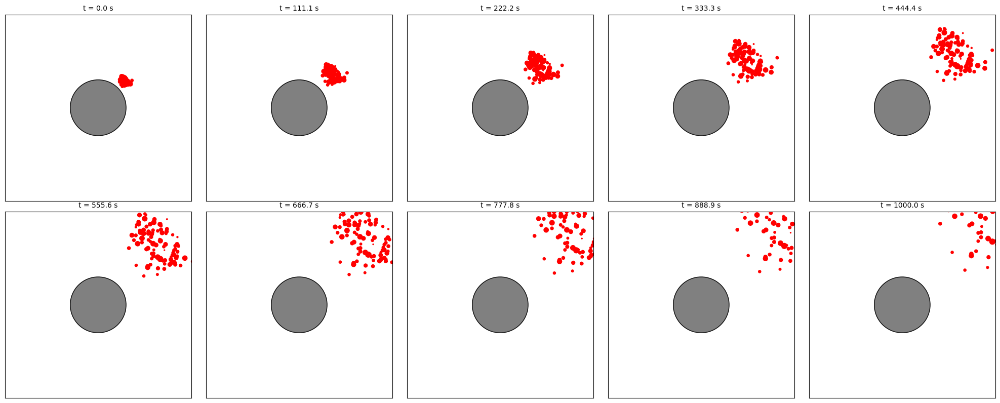

In [36]:
G = 6.67e-11
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3
nucleus_density = 500
nucleus_volume = (4/3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

n_particles = 100
v_mean = 100.0
v_std = 20.0
simulation_duration = 1000
n_snapshots = 10
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)
dt = 1 / 30  # simulation time step
steps_per_snapshot = int(snapshot_times[1] / dt)

mean_diameter = 1e-6
sigma_diameter = 0.3e-6
particle_diameters = np.random.normal(mean_diameter, sigma_diameter, n_particles)
particle_diameters = np.clip(particle_diameters, 1e-7, None)

dust_density = 1000
particle_radii = particle_diameters / 2
particle_masses = (4/3) * np.pi * (particle_radii**3) * dust_density
marker_sizes = 20 * (particle_diameters / mean_diameter)**2

eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])
cone_half_angle = 30
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)
v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, t_snap in enumerate(snapshot_times):
    # Simulate motion up to this snapshot
    for _ in range(steps_per_snapshot):
        r_vec = positions
        r = np.linalg.norm(r_vec, axis=1).reshape(-1, 1)
        r = np.maximum(r, nucleus_radius)
        acc = -G * nucleus_mass / r**3 * r_vec
        velocities += acc * dt
        positions += velocities * dt

    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"t = {t_snap:.1f} s", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

    # Draw the nucleus
    nucleus = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1)
    ax.add_patch(nucleus)

    # Plot dust particles (converted to km)
    ax.scatter(positions[:, 0] / 1e3, positions[:, 1] / 1e3,
               color='red', s=marker_sizes, zorder=2)

# Final layout and save
plt.tight_layout()
plt.show()



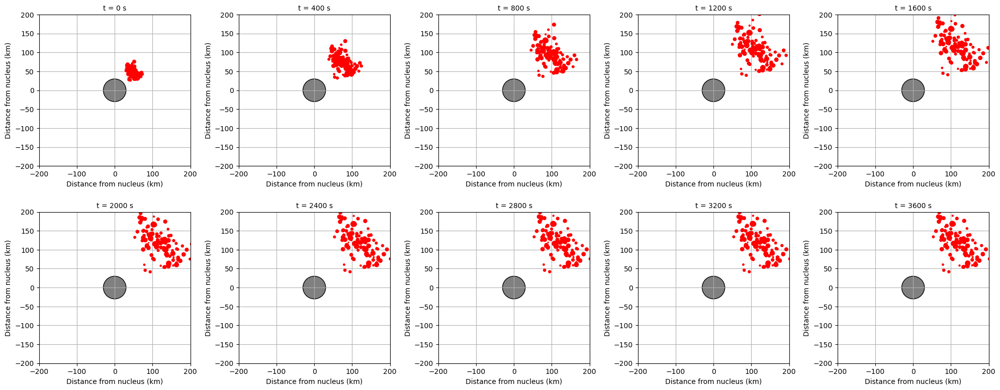

In [37]:
# Physical constants and comet properties
G = 6.67e-11  # Gravitational constant (m^3 kg^-1 s^-2)
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # meters
nucleus_density = 500                     # kg/m^3
nucleus_volume = (4 / 3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters
n_particles = 100
v_mean = 100.0              # m/s
v_std = 20.0                # m/s
simulation_duration = 3600  # 1 hour in seconds
n_snapshots = 10
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)
dt = 1 / 30  # simulation time step (s)
steps_per_snapshot = int(snapshot_times[1] / dt)

# Particle properties
mean_diameter = 1e-6  # meters
sigma_diameter = 0.3e-6
particle_diameters = np.random.normal(mean_diameter, sigma_diameter, n_particles)
particle_diameters = np.clip(particle_diameters, 1e-7, None)
dust_density = 1000  # kg/m^3
particle_radii = particle_diameters / 2
particle_masses = (4/3) * np.pi * (particle_radii**3) * dust_density
marker_sizes = 20 * (particle_diameters / mean_diameter)**2

# Initial positions and velocities 
eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])
cone_half_angle = 30
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)
v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)

# Fading ejection over time: exponential decay 
# A decay factor to initial velocities at each step is applied
tau = simulation_duration / 2  # characteristic fading time
decay_factors = np.exp(-snapshot_times / tau).reshape(-1, 1, 1)  # for 10 snapshots

# Plotting setup
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

# Reset initial state for consistent snapshots
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)
velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

for i, t_snap in enumerate(snapshot_times):
    for _ in range(steps_per_snapshot):
        r_vec = positions
        r = np.linalg.norm(r_vec, axis=1).reshape(-1, 1)
        r = np.maximum(r, nucleus_radius)
        acc = -G * nucleus_mass / r**3 * r_vec
        velocities += acc * dt
        positions += velocities * dt

    # Apply fading ejection effect (damping)
    velocities *= decay_factors[i]

    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-200, 200)      
    ax.set_ylim(-200, 200)
    ax.set_title(f"t = {int(t_snap)} s", fontsize=10)
    ax.set_xlabel("Distance from nucleus (km)")
    ax.set_ylabel("Distance from nucleus (km)")
    ax.grid(True)

    # Draw nucleus
    nucleus = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1)
    ax.add_patch(nucleus)

    # Plot particles
    ax.scatter(positions[:, 0] / 1e3, positions[:, 1] / 1e3,  # convert m to km
               color='red', s=marker_sizes, zorder=2)

plt.tight_layout()
plt.show()


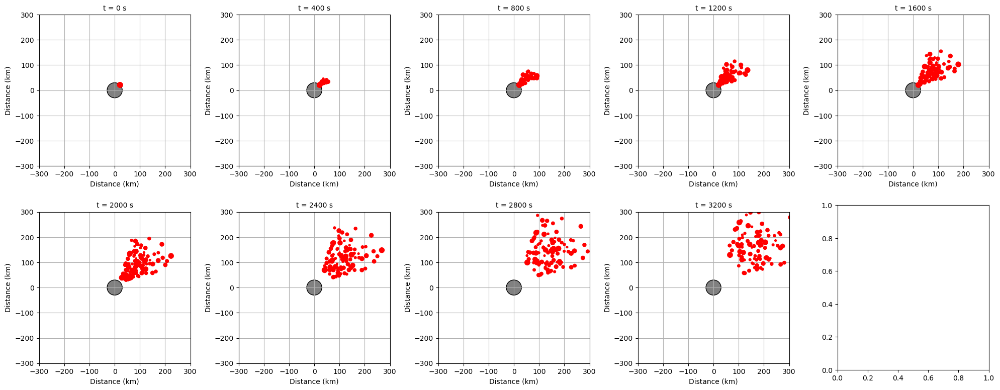

In [38]:
# This code includes ejected particles continiously for 30' for a total of 1 hour simulation. 
# Particles will have an exponential decay/ fading effect set at 1000 seconds. 
# These parameters can be changed in the model according to different scenarios. 

# Physical constants and comet properties
G = 6.67e-11  # Gravitational constant (m^3 kg^-1 s^-2)
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # meters
nucleus_density = 500  # kg/m^3
nucleus_volume = (4 / 3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters
n_particles = 100
v_mean = 100.0  # m/s (mean ejection speed)
v_std = 20.0    # m/s (standard deviation)
simulation_duration = 3600  # seconds (1 hour)
n_snapshots = 10
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)  # Snapshot times (s)
dt = 1 / 30  # simulation time step (s)
n_steps = int(simulation_duration / dt)
steps_per_snapshot = int((snapshot_times[1] - snapshot_times[0]) / dt)

# Particle properties (size and mass)
mean_diameter = 1e-6       # meters (1e-3 mm)
sigma_diameter = 0.3e-6
particle_diameters = np.random.normal(mean_diameter, sigma_diameter, n_particles)
particle_diameters = np.clip(particle_diameters, 1e-7, None)
dust_density = 1000  # kg/m^3
particle_radii = particle_diameters / 2
particle_masses = (4/3) * np.pi * (particle_radii**3) * dust_density
marker_sizes = 20 * (particle_diameters / mean_diameter)**2

# Emission parameters: continuous emission over 30 minutes
emission_duration = 1800  # seconds (first 30 minutes)
# Each particle is assigned a random emission time between 0 and 1800s
emission_times = np.random.uniform(0, emission_duration, n_particles)

# Initial conditions for particles
eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])
cone_half_angle = 30  # degrees
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)
v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
# Store the initial velocities for each particle (to be activated at its emission time)
initial_velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]

# For all particles, initialize positions at the eruption point.
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)
# Before emission, particles are stationary.
velocities = np.zeros((n_particles, 2))

# Fading parameters: linking fading to particle size
# We define a global characteristic time τ (here half the simulation duration).
tau = 1000   #seconds 
# Each particle's effective fading time scales with its diameter:
# (Larger particles "live" longer.)
tau_eff = tau * (particle_diameters / mean_diameter)

# Prepare to record simulation snapshots
snapshots_positions = []
snapshots_alphas = []  # per-particle alpha values at the snapshot time
snapshots_times = []

# Run simulation loop
current_time = 0.0
snapshot_index = 0
for step in range(n_steps):
    current_time = step * dt

    # Determine which particles have been emitted (current time >= emission time)
    emitted = current_time >= emission_times  # boolean mask
    
    # Activate particles at emission: for those not yet emitted (emitted==False), keep them at the eruption point
    # and with zero velocity. When they become emitted, restore their initial velocity.
    newly_emitted = (~emitted) & (current_time + dt >= emission_times)  
    if np.any(newly_emitted):
        velocities[newly_emitted] = initial_velocities[newly_emitted]
    
    # Update only the particles that have been emitted
    if np.any(emitted):
        r_vec = positions[emitted]
        # Compute distances; enforce a minimum value equal to the nucleus radius
        r = np.linalg.norm(r_vec, axis=1, keepdims=True)
        r = np.maximum(r, nucleus_radius)
        # Gravitational acceleration: a = -G*M/r^3 * r_vec
        acc = -G * nucleus_mass / r**3 * r_vec
        velocities[emitted] += acc * dt
        positions[emitted] += velocities[emitted] * dt

    # If current time has reached (or exceeded) the next snapshot time, record the state:
    if snapshot_index < n_snapshots and current_time >= snapshot_times[snapshot_index]:
        # For every particle that has been emitted, compute its "age"
        ages = np.maximum(current_time - emission_times, 0)
        # Compute an alpha value for each particle that is proportional to exp(-age / τ_eff)
        # (For particles not yet emitted, age=0 leads to alpha=exp(0)=1; but we want them to be invisible.)
        alphas = np.where(emitted, np.exp(-ages / tau_eff), 0)
        snapshots_positions.append(positions.copy())
        snapshots_alphas.append(alphas.copy())
        snapshots_times.append(current_time)
        snapshot_index += 1
        if snapshot_index >= n_snapshots:
            break

# Plot snapshots in a 2x5 subplot grid
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i in range(len(snapshots_positions)):
    pos_snap = snapshots_positions[i]
    alphas_snap = snapshots_alphas[i]  # shape (n_particles,)
    t_snap = snapshots_times[i]
    
    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-300, 300)
    ax.set_ylim(-300, 300)
    ax.set_title(f"t = {int(t_snap)} s", fontsize=10)
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    ax.grid(True)
    
    # Draw nucleus (convert radius to km)
    nucleus_circle = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1)
    ax.add_patch(nucleus_circle)

    # Plot particle positions (convert meters to kilometers)
    ax.scatter(pos_snap[:, 0] / 1e3, pos_snap[:, 1] / 1e3,
               color='red', s=marker_sizes, zorder=2)

plt.tight_layout()
plt.show()


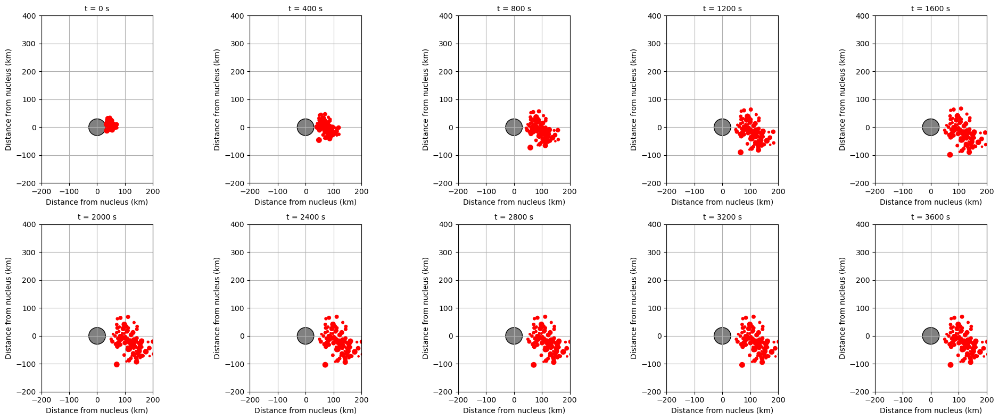

In [39]:
# Physical constants and comet properties
G = 6.67e-11  # Gravitational constant (m^3 kg^-1 s^-2)
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # meters
nucleus_density = 500                     # kg/m^3
nucleus_volume = (4 / 3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters
n_particles = 100
v_mean = 100.0              # m/s
v_std = 20.0                # m/s
simulation_duration = 3600  # 1 hour in seconds
n_snapshots = 10
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)
dt = 1 / 30  # simulation time step (s)
steps_per_snapshot = int(snapshot_times[1] / dt)

# Particle properties
mean_diameter = 1e-6  # meters
sigma_diameter = 0.3e-6
particle_diameters = np.random.normal(mean_diameter, sigma_diameter, n_particles)
particle_diameters = np.clip(particle_diameters, 1e-7, None)
dust_density = 1000  # kg/m^3
particle_radii = particle_diameters / 2
particle_masses = (4/3) * np.pi * (particle_radii**3) * dust_density
marker_sizes = 20 * (particle_diameters / mean_diameter)**2

# Comet velocity (in inertial frame, moving upward)
comet_velocity = np.array([0.0, -100.0])  # m/s upward

# Initial positions and velocities 
eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])
cone_half_angle = 30
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_particles)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles = eruption_angle + deviations_rad
vx = np.cos(ejection_angles)
vy = np.sin(ejection_angles)
v_ejects = np.random.normal(v_mean, v_std, n_particles)
v_ejects = np.clip(v_ejects, 0, None)
relative_velocities = np.column_stack((vx, vy)) * v_ejects[:, np.newaxis]
velocities = relative_velocities + comet_velocity  # Add comet motion
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)

# Fading ejection over time: exponential decay 
tau = simulation_duration / 2  # characteristic fading time
decay_factors = np.exp(-snapshot_times / tau).reshape(-1, 1, 1)

# Plotting setup
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

# Reset state
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)
velocities = relative_velocities + comet_velocity

for i, t_snap in enumerate(snapshot_times):
    for _ in range(steps_per_snapshot):
        r_vec = positions
        r = np.linalg.norm(r_vec, axis=1).reshape(-1, 1)
        r = np.maximum(r, nucleus_radius)
        acc = -G * nucleus_mass / r**3 * r_vec
        velocities += acc * dt
        positions += velocities * dt

    # Apply fading ejection effect
    velocities *= decay_factors[i]

    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-200, 200)
    ax.set_ylim(-200, 400)
    ax.set_title(f"t = {int(t_snap)} s", fontsize=10)
    ax.set_xlabel("Distance from nucleus (km)")
    ax.set_ylabel("Distance from nucleus (km)")
    ax.grid(True)

    # Draw nucleus
    nucleus = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black')
    ax.add_patch(nucleus)

    # Plot particles
    ax.scatter(positions[:, 0] / 1e3, positions[:, 1] / 1e3,
               color='red', s=marker_sizes, zorder=2)

plt.tight_layout()
plt.show()


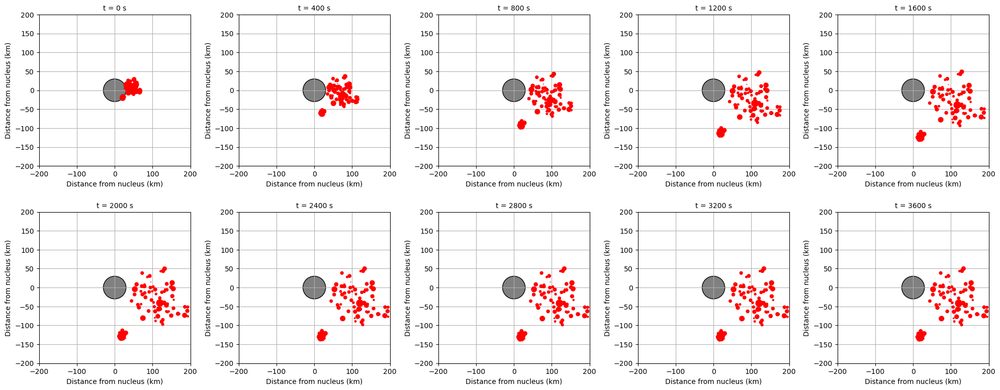

In [40]:
# Physical constants and comet properties
G = 6.67e-11  # Gravitational constant (m^3 kg^-1 s^-2)
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # meters
nucleus_density = 500  # kg/m^3
nucleus_volume = (4 / 3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters
n_particles = 100
simulation_duration = 3600  # 1 hour in seconds
n_snapshots = 10
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)
dt = 1 / 30  # time step in seconds
steps_per_snapshot = int(snapshot_times[1] / dt)

# Particle properties
mean_diameter = 1e-6  # meters
sigma_diameter = 0.3e-6
particle_diameters = np.random.normal(mean_diameter, sigma_diameter, n_particles)
particle_diameters = np.clip(particle_diameters, 1e-7, None)
dust_density = 1000  # kg/m^3
particle_radii = particle_diameters / 2
particle_masses = (4/3) * np.pi * (particle_radii**3) * dust_density
marker_sizes = 20 * (particle_diameters / mean_diameter)**2

# Ejection angles 
eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

# Split particles into fast (tail) and slow (coma)
n_fast = int(0.7 * n_particles)
n_slow = n_particles - n_fast

cone_half_angle = 30  # degrees
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_fast)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles_fast = eruption_angle + deviations_rad

# Fast particles
v_fast = np.random.normal(100, 20, n_fast)
v_fast = np.clip(v_fast, 0, None)
vx_fast = np.cos(ejection_angles_fast)
vy_fast = np.sin(ejection_angles_fast)
vel_fast = np.column_stack((vx_fast, vy_fast)) * v_fast[:, np.newaxis]

# Slow particles (coma) - random direction
angles_slow = np.random.uniform(0, 2 * np.pi, n_slow)
v_slow = np.random.normal(5, 2, n_slow)
v_slow = np.clip(v_slow, 0, None)
vx_slow = np.cos(angles_slow)
vy_slow = np.sin(angles_slow)
vel_slow = np.column_stack((vx_slow, vy_slow)) * v_slow[:, np.newaxis]

# Combine particles
velocities = np.vstack([vel_fast, vel_slow])
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)

# Add comet's motion (upward) to all velocities
v_comet = np.array([0, -100])  # m/s upward
velocities += v_comet

# Fading ejection velocity over time
tau = simulation_duration / 2  # characteristic fading time
decay_factors = np.exp(-snapshot_times / tau).reshape(-1, 1, 1)

# Plotting setup
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

# Reset state for consistency
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)
velocities = np.vstack([vel_fast, vel_slow]) + v_comet

# Time evolution loop
for i, t_snap in enumerate(snapshot_times):
    for _ in range(steps_per_snapshot):
        r_vec = positions
        r = np.linalg.norm(r_vec, axis=1).reshape(-1, 1)
        r = np.maximum(r, nucleus_radius)
        acc = -G * nucleus_mass / r**3 * r_vec
        velocities += acc * dt
        positions += velocities * dt

    # Apply fading velocity
    velocities *= decay_factors[i]

    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-200, 200)
    ax.set_ylim(-200, 200)
    ax.set_title(f"t = {int(t_snap)} s", fontsize=10)
    ax.set_xlabel("Distance from nucleus (km)")
    ax.set_ylabel("Distance from nucleus (km)")
    ax.grid(True)

    # Draw nucleus
    nucleus = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1)
    ax.add_patch(nucleus)

    # Plot particles (in km)
    ax.scatter(positions[:, 0] / 1e3, positions[:, 1] / 1e3,
               color='red', s=marker_sizes, zorder=2)

plt.tight_layout()
plt.show()


In the following code, the continuous 30' ejection and the motion (upward velocity) of the comet are combined into one diagram. 

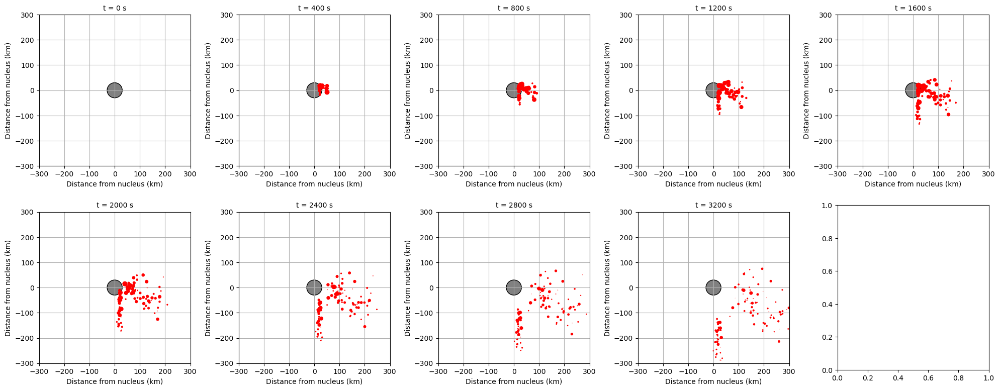

In [41]:
# Physical constants and comet properties
G = 6.67e-11  # Gravitational constant (m^3 kg^-1 s^-2)
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # meters
nucleus_density = 500                     # kg/m^3
nucleus_volume = (4 / 3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters 
n_particles = 100                         # Number of ejected particles. This value can change.
simulation_duration = 3600                # 1 hour in seconds.
n_snapshots = 10                          # number of snapshots over the duration of the simulation used on the diagram.
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)  # Divides the duration of the simulation into 10 snapshots. 
dt = 1 / 30                               # seconds.
n_steps = int(simulation_duration / dt)
steps_per_snapshot = int((snapshot_times[1] - snapshot_times[0]) / dt)

# Particle properties
mean_diameter = 1e-6     # meters
sigma_diameter = 0.3e-6  # standard deviation
particle_diameters = np.random.normal(mean_diameter, sigma_diameter, n_particles)  # Randon normal distribution for the particle sizes.
particle_diameters = np.clip(particle_diameters, 1e-7, None)                       # Limit set for the minimum size of particles so the value doesn't go negative. 
dust_density = 1000      # kg/m^3
particle_radii = particle_diameters / 2
particle_masses = (4/3) * np.pi * (particle_radii**3) * dust_density
marker_sizes = 20 * (particle_diameters / mean_diameter)**2

# Emission time: continuous for 30 minutes
emission_duration = 1800  # seconds
emission_times = np.random.uniform(0, emission_duration, n_particles)

# Comet motion
v_comet = np.array([0, -100])  # m/s (upward)

# Ejection directions and speeds
eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

n_fast = int(0.7 * n_particles)
n_slow = n_particles - n_fast

# Fast particles (tail)
cone_half_angle = 30
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_fast)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles_fast = eruption_angle + deviations_rad
v_fast = np.random.normal(100, 20, n_fast)
v_fast = np.clip(v_fast, 0, None)
vx_fast = np.cos(ejection_angles_fast)
vy_fast = np.sin(ejection_angles_fast)
vel_fast = np.column_stack((vx_fast, vy_fast)) * v_fast[:, np.newaxis]

# Slow particles (coma)
angles_slow = np.random.uniform(0, 2 * np.pi, n_slow)
v_slow = np.random.normal(5, 2, n_slow)
v_slow = np.clip(v_slow, 0, None)
vx_slow = np.cos(angles_slow)
vy_slow = np.sin(angles_slow)
vel_slow = np.column_stack((vx_slow, vy_slow)) * v_slow[:, np.newaxis]

# Combine
initial_velocities = np.vstack([vel_fast, vel_slow]) + v_comet
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)
velocities = np.zeros_like(initial_velocities)

# Fading parameters 
tau = 1000  # seconds
tau_eff = tau * (particle_diameters / mean_diameter)

# Snapshot recording
snapshots_positions = []
snapshots_alphas = []
snapshots_times = []

# Simulation loop
snapshot_index = 0
for step in range(n_steps):
    current_time = step * dt
    emitted = current_time >= emission_times
    newly_emitted = (~emitted) & (current_time + dt >= emission_times)
    velocities[newly_emitted] = initial_velocities[newly_emitted]

    if np.any(emitted):
        r_vec = positions[emitted]
        r = np.linalg.norm(r_vec, axis=1, keepdims=True)
        r = np.maximum(r, nucleus_radius)
        acc = -G * nucleus_mass / r**3 * r_vec
        velocities[emitted] += acc * dt
        positions[emitted] += velocities[emitted] * dt

    if snapshot_index < n_snapshots and current_time >= snapshot_times[snapshot_index]:
        ages = np.maximum(current_time - emission_times, 0)
        alphas = np.where(emitted, np.exp(-ages / tau_eff), 0)
        snapshots_positions.append(positions.copy())
        snapshots_alphas.append(alphas.copy())
        snapshots_times.append(current_time)
        snapshot_index += 1
        if snapshot_index >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i in range(len(snapshots_positions)):
    pos_snap = snapshots_positions[i]
    alphas_snap = snapshots_alphas[i]
    t_snap = snapshots_times[i]

    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-300, 300)
    ax.set_ylim(-300, 300)
    ax.set_title(f"t = {int(t_snap)} s", fontsize=10)
    ax.set_xlabel("Distance from nucleus (km)")
    ax.set_ylabel("Distance from nucleus (km)")
    ax.grid(True)

    # Draw nucleus
    nucleus_circle = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1)
    ax.add_patch(nucleus_circle)

    # Plot particles
    ax.scatter(pos_snap[:, 0] / 1e3, pos_snap[:, 1] / 1e3,
               color='red', s=marker_sizes * alphas_snap, alpha=1.0, zorder=2)

plt.tight_layout()
plt.show()


Now I will try to make the model even more realistic. Velocity of the comet will be estimated and inserted so it is more accurate for the model. Also number of particles will be increased. 

In [42]:
# Estimating the velocity of 29P:
# constants
GMsun = 1.327e20       # m^3/s^2. This is the grav. constant (G) multiplied by the solar mass. 
AU    = 1.496e11       # m

a_AU = 6.0
a   = a_AU * AU            # m
r   = a                    # for a circular approximation

v = np.sqrt(GMsun * (2/r - 1/a))
print(f"Orbital speed at {a_AU} AU ≈ {v/1e3:.2f} km/s")


Orbital speed at 6.0 AU ≈ 12.16 km/s


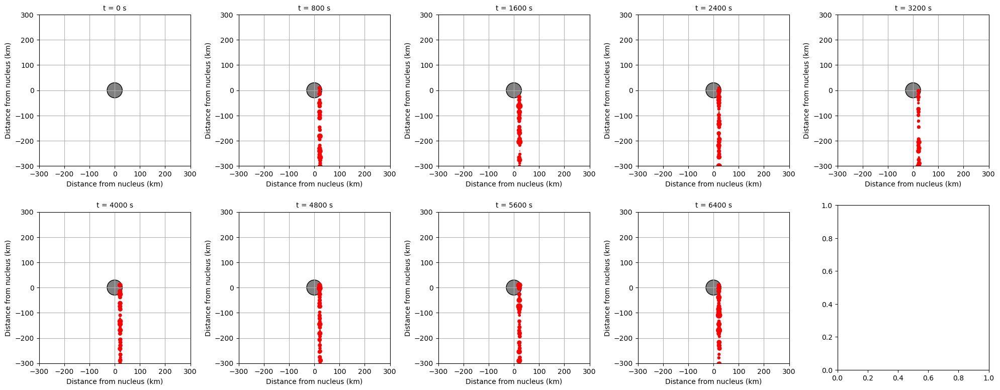

In [43]:
# Physical constants and comet properties
G = 6.67e-11  # Gravitational constant (m^3 kg^-1 s^-2)
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # meters
nucleus_density = 500                     # kg/m^3
nucleus_volume = (4 / 3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters 
n_particles = 10000                       # Number of ejected particles. This value can change.
simulation_duration = 7200                # 1 hour in seconds.
n_snapshots = 10                          # number of snapshots over the duration of the simulation used on the diagram.
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)  # Divides the duration of the simulation into 10 snapshots. 
dt = 1                                    # seconds.
n_steps = int(simulation_duration / dt)
steps_per_snapshot = int((snapshot_times[1] - snapshot_times[0]) / dt)

# Particle properties
mean_diameter = 1e-6     # meters
sigma_diameter = 0.3e-6  # standard deviation
particle_diameters = np.random.normal(mean_diameter, sigma_diameter, n_particles)  # Randon normal distribution for the particle sizes.
particle_diameters = np.clip(particle_diameters, 1e-7, None)                       # Limit set for the minimum size of particles so the value doesn't go negative. 
dust_density = 1000      # kg/m^3
particle_radii = particle_diameters / 2
particle_masses = (4/3) * np.pi * (particle_radii**3) * dust_density
marker_sizes = 20 * (particle_diameters / mean_diameter)**2

# Emission time: continuous for 7000 seconds
emission_duration = 7000  # seconds
emission_times = np.random.uniform(0, emission_duration, n_particles)

# Comet motion
v_comet = np.array([0, -12000])  # m/s (upward)

# Ejection directions and speeds
eruption_angle = np.deg2rad(45)
eruption_point_m = np.array([
    nucleus_radius * np.cos(eruption_angle),
    nucleus_radius * np.sin(eruption_angle)
])

n_fast = int(0.7 * n_particles)
n_slow = n_particles - n_fast

# Fast particles (tail)
cone_half_angle = 30
deviations_deg = np.random.uniform(-cone_half_angle, cone_half_angle, n_fast)
deviations_rad = np.deg2rad(deviations_deg)
ejection_angles_fast = eruption_angle + deviations_rad
v_fast = np.random.normal(100, 20, n_fast)
v_fast = np.clip(v_fast, 0, None)
vx_fast = np.cos(ejection_angles_fast)
vy_fast = np.sin(ejection_angles_fast)
vel_fast = np.column_stack((vx_fast, vy_fast)) * v_fast[:, np.newaxis]

# Slow particles (coma)
angles_slow = np.random.uniform(0, 2 * np.pi, n_slow)
v_slow = np.random.normal(5, 2, n_slow)
v_slow = np.clip(v_slow, 0, None)
vx_slow = np.cos(angles_slow)
vy_slow = np.sin(angles_slow)
vel_slow = np.column_stack((vx_slow, vy_slow)) * v_slow[:, np.newaxis]

# Combine
initial_velocities = np.vstack([vel_fast, vel_slow]) + v_comet
positions = np.tile(eruption_point_m, (n_particles, 1)).astype(float)
velocities = np.zeros_like(initial_velocities)

# Fading parameters 
tau = 3600  # seconds
tau_eff = tau * (particle_diameters / mean_diameter)

# Snapshot recording
snapshots_positions = []
snapshots_alphas = []
snapshots_times = []

# Simulation loop
snapshot_index = 0
for step in range(n_steps):
    current_time = step * dt
    emitted = current_time >= emission_times
    newly_emitted = (~emitted) & (current_time + dt >= emission_times)
    velocities[newly_emitted] = initial_velocities[newly_emitted]

    if np.any(emitted):
        r_vec = positions[emitted]
        r = np.linalg.norm(r_vec, axis=1, keepdims=True)
        r = np.maximum(r, nucleus_radius)
        acc = -G * nucleus_mass / r**3 * r_vec
        velocities[emitted] += acc * dt
        positions[emitted] += velocities[emitted] * dt

    if snapshot_index < n_snapshots and current_time >= snapshot_times[snapshot_index]:
        ages = np.maximum(current_time - emission_times, 0)
        alphas = np.where(emitted, np.exp(-ages / tau_eff), 0)
        snapshots_positions.append(positions.copy())
        snapshots_alphas.append(alphas.copy())
        snapshots_times.append(current_time)
        snapshot_index += 1
        if snapshot_index >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i in range(len(snapshots_positions)):
    pos_snap = snapshots_positions[i]
    alphas_snap = snapshots_alphas[i]
    t_snap = snapshots_times[i]

    ax = axes[i]
    ax.set_aspect('equal')
    ax.set_xlim(-300, 300)
    ax.set_ylim(-300, 300)
    ax.set_title(f"t = {int(t_snap)} s", fontsize=10)
    ax.set_xlabel("Distance from nucleus (km)")
    ax.set_ylabel("Distance from nucleus (km)")
    ax.grid(True)

    # Draw nucleus
    nucleus_circle = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='black', zorder=1)
    ax.add_patch(nucleus_circle)

    # Plot particles
    ax.scatter(pos_snap[:, 0] / 1e3, pos_snap[:, 1] / 1e3,
               color='red', s=marker_sizes * alphas_snap, alpha=1.0, zorder=2)

plt.tight_layout()
plt.show()


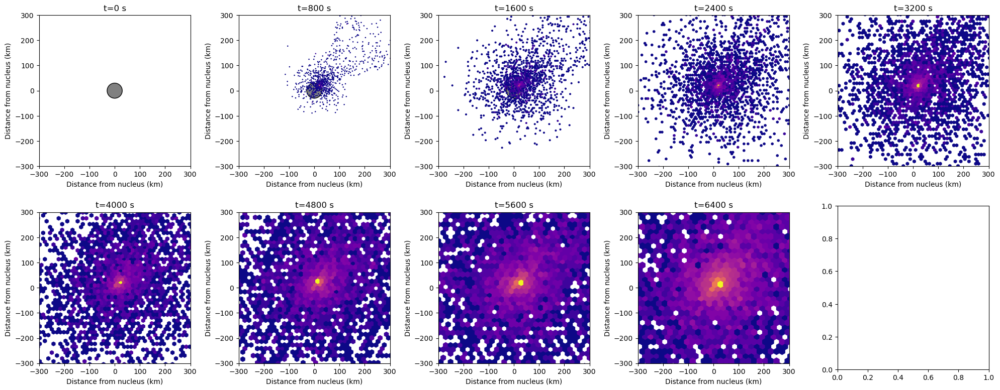

In [44]:
# Comet physical properties
G = 6.67e-11                              # m^3 / kg / s^2
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # m
nucleus_density = 500                     # kg/m^3
nucleus_volume = (4/3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters
n_particles = 10000
simulation_duration = 2*3600         # 2 hours in seconds
n_snapshots    = 10
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)
dt             = 1.0                 # 1s timestep 
n_steps        = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57*24*3600             # seconds
omega_spin  = 2*np.pi / spin_period

'''
# Emission pulses (5 × 700 s pulses)
n_pulses      = 5
pulse_length  = simulation_duration / n_pulses
emission_times = np.hstack([
    np.random.uniform(i*pulse_length, (i+1)*pulse_length, n_particles//n_pulses)
    for i in range(n_pulses)
])
# pad if needed
if emission_times.size < n_particles:
    extra = n_particles - emission_times.size
    emission_times = np.hstack([emission_times,
                                np.random.uniform(0, pulse_length, extra)])
emission_times = emission_times[:n_particles]'''

# Emission time: continuous for 7000 seconds
emission_duration = 7000  # seconds
emission_times = np.random.uniform(0, emission_duration, n_particles)

# Particle size
mean_d = 1e-6; sigma_d = 0.3e-6
d = np.random.normal(mean_d, sigma_d, n_particles)
d = np.clip(d, 1e-7, None)
r = d/2
rho_dust = 1000
# particle mass
m = (4/3)*np.pi*r**3 * rho_dust
marker_s = 20 * (d/mean_d)**2

# Fast vs slow split
# It creates a condition where 30% of particles go into the tail and 70% into the coma.
# This will be adjusted later (if able) and have a condition according to the gravitational force: 
# If the force of the particle > than gravity of comet, then particle will go to the tail. 
n_fast = int(0.3 * n_particles)
is_fast = np.zeros(n_particles, bool)
is_fast[:n_fast] = True
np.random.shuffle(is_fast)

# tail: ±30° cone around 45°, speed ~400±50
cone = np.deg2rad(30)
dev_fast = np.random.uniform(-cone, cone,  n_fast)
v_fast  = np.clip(np.random.normal(400, 50,  n_fast), 0, None)

# coma: isotropic, speed ~100±50
dev_slow = np.random.uniform(0, 2*np.pi, n_particles-n_fast)
v_slow   = np.clip(np.random.normal(100, 50, n_particles-n_fast), 0, None)

# assemble
v_mag     = np.zeros(n_particles)
theta_dev = np.zeros(n_particles)
v_mag[is_fast]     = v_fast
theta_dev[is_fast] = dev_fast
v_mag[~is_fast]     = v_slow
theta_dev[~is_fast] = dev_slow

# Eruption point (top of nucleus at t=0)
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius*np.cos(base_angle),
                      nucleus_radius*np.sin(base_angle)],
                     (n_particles,1))
velocities = np.zeros_like(positions)

emitted = np.zeros(n_particles, bool)

# Prepare storage for snapshots
snapshots = []
times = snapshot_times.copy()

# simulation loop
snap_i = 0
for step in range(n_steps):
    t = step*dt

    # current eruption angle & point
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius*np.cos(phi0),
                     nucleus_radius*np.sin(phi0)])

    # emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        # direction = current eruption angle + dev for fast; dev_slow for slow
        thetas = np.where(is_fast[new_emit],
                          phi0 + theta_dev[new_emit],
                          theta_dev[new_emit])
        velocities[new_emit,0] = np.cos(thetas)*v_mag[new_emit]
        velocities[new_emit,1] = np.sin(thetas)*v_mag[new_emit]
        positions[new_emit] = epic  # start at current eruption point

    # gravity on emitted
    if emitted.any():
        vec = positions[emitted]
        dist = np.linalg.norm(vec,axis=1,keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G*nucleus_mass/dist**3 * vec
        velocities[emitted] += acc*dt
        positions[emitted]  += velocities[emitted]*dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        snap_i += 1
        if snap_i>=n_snapshots:
            break

# Plot 2×5 hex‐bin density panels
fig, axes = plt.subplots(2,5,figsize=(20,8))
axes = axes.flatten()
for i,(pos,ax) in enumerate(zip(snapshots,axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-300,300)
    ax.set_ylim(-300,300)
    ax.set_title(f"t={int(times[i])} s")
    ax.set_xlabel("Distance from nucleus (km)")
    ax.set_ylabel("Distance from nucleus (km)")
    # nucleus
    circ = plt.Circle((0,0), nucleus_radius_km, color='grey', ec='k', zorder=1)
    ax.add_patch(circ)
    # density map
    x_km = pos[:,0]/1e3; y_km = pos[:,1]/1e3
    ax.hexbin(x_km, y_km, gridsize=200, cmap='plasma', bins='log', mincnt=1)
plt.tight_layout()
plt.show()


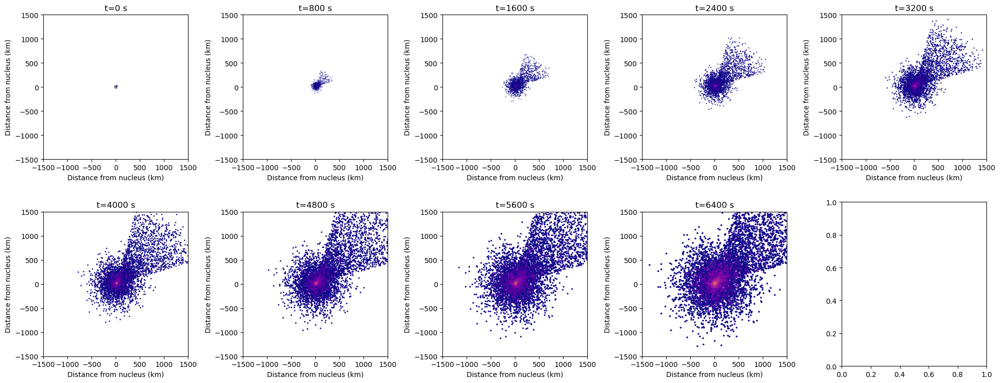

In [45]:
# Comet physical properties
G = 6.67e-11                          # m^3 / kg / s^2
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # m
nucleus_density = 500                     # kg/m^3
nucleus_volume = (4/3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters
n_particles = 10000
simulation_duration = 2*3600         # 2 hours in seconds
n_snapshots    = 10
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)
dt             = 1.0                 # 1s timestep 
n_steps        = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57*24*3600             # seconds
omega_spin  = 2*np.pi / spin_period

'''
# Emission pulses (5 × 700 s pulses)
n_pulses      = 5
pulse_length  = simulation_duration / n_pulses
emission_times = np.hstack([
    np.random.uniform(i*pulse_length, (i+1)*pulse_length, n_particles//n_pulses)
    for i in range(n_pulses)
])
# pad if needed
if emission_times.size < n_particles:
    extra = n_particles - emission_times.size
    emission_times = np.hstack([emission_times,
                                np.random.uniform(0, pulse_length, extra)])
emission_times = emission_times[:n_particles]'''

# Emission time: continuous for 7000 seconds
emission_duration = 7000  # seconds
emission_times = np.random.uniform(0, emission_duration, n_particles)

# Particle size
mean_d = 1e-6; sigma_d = 0.3e-6
d = np.random.normal(mean_d, sigma_d, n_particles)
d = np.clip(d, 1e-7, None)
r = d/2
rho_dust = 1000
# particle mass
m = (4/3)*np.pi*r**3 * rho_dust
marker_s = 20 * (d/mean_d)**2

# Fast vs slow split
# It creates a condition where 30% of particles go into the tail and 70% into the coma.
# This will be adjusted later (if able) and have a condition according to the gravitational force: 
# If the force of the particle > than gravity of comet, then particle will go to the tail. 
n_fast = int(0.3 * n_particles)
is_fast = np.zeros(n_particles, bool)
is_fast[:n_fast] = True
np.random.shuffle(is_fast)

# tail: ±30° cone around 45°, speed ~400±50
cone = np.deg2rad(30)
dev_fast = np.random.uniform(-cone, cone,  n_fast)
v_fast  = np.clip(np.random.normal(400, 50,  n_fast), 0, None)

# coma: isotropic, speed ~100±50
dev_slow = np.random.uniform(0, 2*np.pi, n_particles-n_fast)
v_slow   = np.clip(np.random.normal(100, 50, n_particles-n_fast), 0, None)

# assemble
v_mag     = np.zeros(n_particles)
theta_dev = np.zeros(n_particles)
v_mag[is_fast]     = v_fast
theta_dev[is_fast] = dev_fast
v_mag[~is_fast]     = v_slow
theta_dev[~is_fast] = dev_slow

# Eruption point (top of nucleus at t=0)
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius*np.cos(base_angle),
                      nucleus_radius*np.sin(base_angle)],
                     (n_particles,1))
velocities = np.zeros_like(positions)

emitted = np.zeros(n_particles, bool)

# Prepare storage for snapshots
snapshots = []
times = snapshot_times.copy()

# simulation loop
snap_i = 0
for step in range(n_steps):
    t = step*dt

    # current eruption angle & point
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius*np.cos(phi0),
                     nucleus_radius*np.sin(phi0)])

    # emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        # direction = current eruption angle + dev for fast; dev_slow for slow
        thetas = np.where(is_fast[new_emit],
                          phi0 + theta_dev[new_emit],
                          theta_dev[new_emit])
        velocities[new_emit,0] = np.cos(thetas)*v_mag[new_emit]
        velocities[new_emit,1] = np.sin(thetas)*v_mag[new_emit]
        positions[new_emit] = epic  # start at current eruption point

    # gravity on emitted
    if emitted.any():
        vec = positions[emitted]
        dist = np.linalg.norm(vec,axis=1,keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G*nucleus_mass/dist**3 * vec
        velocities[emitted] += acc*dt
        positions[emitted]  += velocities[emitted]*dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        snap_i += 1
        if snap_i>=n_snapshots:
            break

# Plot 2×5 hex‐bin density panels
fig, axes = plt.subplots(2,5,figsize=(20,8))
axes = axes.flatten()
for i,(pos,ax) in enumerate(zip(snapshots,axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-1500,1500)
    ax.set_ylim(-1500,1500)
    ax.set_title(f"t={int(times[i])} s")
    ax.set_xlabel("Distance from nucleus (km)")
    ax.set_ylabel("Distance from nucleus (km)")
    # nucleus
    circ = plt.Circle((0,0), nucleus_radius_km, color='grey')
    ax.add_patch(circ)
    # density map
    x_km = pos[:,0]/1e3; y_km = pos[:,1]/1e3
    ax.hexbin(x_km, y_km, gridsize=200, cmap='plasma', bins='log')
plt.tight_layout()
plt.show()


In [46]:
# Consider the solar radiation pressure:
S = 1361  # Solar constant (W/m^2)
c = 3e8  # Speed of light (m/s)
Qpr = 1.0  # Efficiency factor
a = particle_radii  # particle radius (m)
area = np.pi * a**2
F_rad = (S * Qpr * area) / c  # radiation force (N)
a_rad = F_rad / particle_masses  # acceleration (m/s^2)
rad_direction = np.array([1, 0])  # Solar direction (to right)
a_rad_vector = a_rad.reshape(-1, 1) * rad_direction

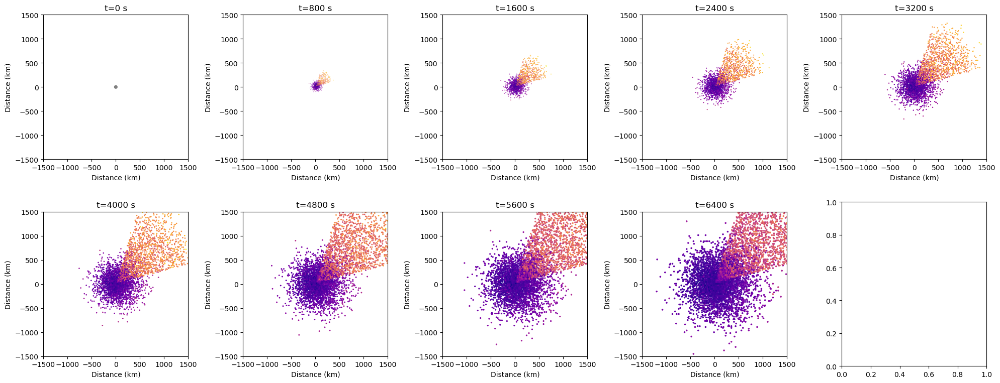

In [47]:
# Comet physical properties 
G = 6.67e-11                          # m^3 / kg / s^2
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3  # m
nucleus_density = 500                     # kg/m^3
nucleus_volume = (4/3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

# Simulation parameters
n_particles = 10000
simulation_duration = 2*3600         # 2 hours in seconds
n_snapshots    = 10
snapshot_times = np.linspace(0, simulation_duration, n_snapshots)
dt             = 1.0                 # 1s timestep 
n_steps        = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57*24*3600             # seconds
omega_spin  = 2*np.pi / spin_period

# Emission time: continuous for 7000 seconds
emission_duration = 7000  # seconds
emission_times = np.random.uniform(0, emission_duration, n_particles)

# Particle size
mean_d = 1e-6; sigma_d = 0.3e-6
d = np.random.normal(mean_d, sigma_d, n_particles)
d = np.clip(d, 1e-7, None)
r = d/2
rho_dust = 1000
m = (4/3)*np.pi*r**3 * rho_dust
marker_s = 20 * (d/mean_d)**2

# Fast vs slow split
n_fast = int(0.3 * n_particles)
is_fast = np.zeros(n_particles, bool)
is_fast[:n_fast] = True
np.random.shuffle(is_fast)

# Tail and coma parameters
cone = np.deg2rad(30)
dev_fast = np.random.uniform(-cone, cone,  n_fast)
v_fast  = np.clip(np.random.normal(400, 50,  n_fast), 0, None)
dev_slow = np.random.uniform(0, 2*np.pi, n_particles-n_fast)
v_slow   = np.clip(np.random.normal(100, 50, n_particles-n_fast), 0, None)

# Combine into arrays
v_mag = np.zeros(n_particles)
theta_dev = np.zeros(n_particles)
v_mag[is_fast] = v_fast
theta_dev[is_fast] = dev_fast
v_mag[~is_fast] = v_slow
theta_dev[~is_fast] = dev_slow

# Initial positions and velocities
base_angle = np.deg2rad(45)
positions = np.tile([nucleus_radius*np.cos(base_angle),
                     nucleus_radius*np.sin(base_angle)],
                    (n_particles, 1))
velocities = np.zeros_like(positions)
emitted = np.zeros(n_particles, bool)

# For color coding
speed_record = np.zeros(n_particles)

# Solar radiation pressure
S = 1361   # Solar constant (W/m^2)
c = 3e8    # Speed of light (m/s)
Qpr = 1.0  # Efficiency factor
a = particle_radii  # particle radius (m)
area = np.pi * a**2
F_rad = (S * Qpr * area) / c  # radiation force (N)
a_rad = F_rad / particle_masses  # acceleration (m/s^2)
rad_direction = np.array([1, 0])  # Solar direction (to right)
a_solar = a_rad.reshape(-1, 1) * rad_direction

# Prepare storage for snapshots
snapshots = []
snapshots_speeds = []
times = snapshot_times.copy()

# simulation loop
snap_i = 0
for step in range(n_steps):
    t = step * dt

    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius*np.cos(phi0),
                     nucleus_radius*np.sin(phi0)])

    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        thetas = np.where(is_fast[new_emit],
                          phi0 + theta_dev[new_emit],
                          theta_dev[new_emit])
        velocities[new_emit, 0] = np.cos(thetas) * v_mag[new_emit]
        velocities[new_emit, 1] = np.sin(thetas) * v_mag[new_emit]
        positions[new_emit] = epic

    if emitted.any():
        vec = positions[emitted]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)

        # gravitational acceleration (M×2)
        grav_acc = -G * nucleus_mass / dist**3 * vec

        # solar‐pressure acceleration (also M×2 after masking)
        solar_acc = a_solar[emitted]

        # update velocities & positions
        velocities[emitted] += (grav_acc + solar_acc) * dt
        positions[emitted]  += velocities[emitted] * dt

        # Track speeds
        speed_record[emitted] = np.linalg.norm(velocities[emitted], axis=1)

    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        snapshots_speeds.append(speed_record.copy())
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plot
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()
for i, (pos, speed, ax) in enumerate(zip(snapshots, snapshots_speeds, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-1500, 1500)
    ax.set_ylim(-1500, 1500)
    ax.set_title(f"t={int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey')
    ax.add_patch(circ)
    x_km = pos[:, 0] / 1e3
    y_km = pos[:, 1] / 1e3
    hb = ax.hexbin(x_km, y_km, C=speed, reduce_C_function=np.mean,
                   gridsize=200, cmap='plasma')
plt.tight_layout()
plt.show()


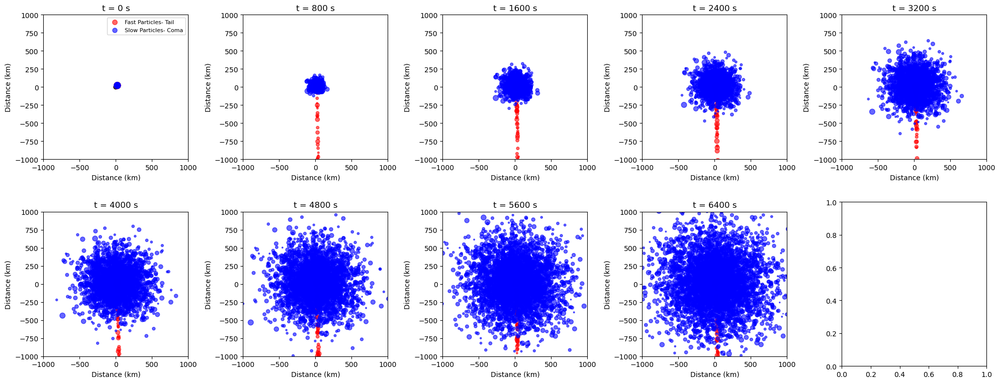

In [48]:
# Comet physical properties
G = 6.67e-11                                 # m^3 / kg / s^2
nucleus_radius_km = 30                       # km
nucleus_radius    = nucleus_radius_km * 1e3  # m
nucleus_density   = 500                      # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3 # m^3
nucleus_mass      = nucleus_density * nucleus_volume  # kg

# Simulation parameters
n_particles         = 10000     # The number of ejected particles from the outburst. 
simulation_duration = 2*3600    # 2 hours in seconds. 
n_snapshots         = 10        # The number of snapshots being shown in the figure. 
snapshot_times      = np.linspace(0, simulation_duration, n_snapshots)
dt                  = 1.0       # 1s timestep for the simulation. 
n_steps             = int(simulation_duration / dt)

# nucleus rotation: 57 day period
spin_period = 57 * 24 * 3600         # seconds
omega_spin  = 2*np.pi / spin_period  # orbital velocity

# continuous emission for first 7000 seconds (model purposes)
emission_duration = 7000
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size & markers
mean_d   = 1e-6    # meters
sigma_d  = 0.3e-6  # standard deviation
d        = np.random.normal(mean_d, sigma_d, n_particles) # Random normal (Gaussian) size distribution of ejected particles
d        = np.clip(d, 1e-7, None)  # minimum size is set to 1e-7 so particles don't have negative size. 
r        = d/2                 # radius of the ejected particles
rho_dust = 1000                # kg/m^3
m        = (4/3)*np.pi*r**3 * rho_dust # mass of the ejected particles
marker_s = 20 * (d/mean_d)**2

# Fast vs slow particle split
# Fraction was used: this is not a precise model. It was used for the purpose of simulating the coma and the tail of 29P. 

# 30% of ejected particles are set to be fast moving particles that simulate the tail of the comet as it moves. 
frac_fast = 0.3   # Fraction of fast moving particles.
n_fast    = int(frac_fast * n_particles) # total number of fast moving particles. 
is_fast   = np.zeros(n_particles, bool)  
is_fast[:n_fast] = True
np.random.shuffle(is_fast)

# fast tail: cone ±30° around 45°, speed ~300±50 m/s
cone     = np.deg2rad(30)
dev_fast = np.random.uniform(-cone, cone, n_fast)
v_fast   = np.clip(np.random.normal(300, 50, n_fast), 0, None)

# 70% of ejected particles are set to be slow moving so it simulates the coma formed around the comet nucleus. 
# slow coma: isotropic 0–2π, speed ~100±50 m/s 
n_slow   = n_particles - n_fast
dev_slow = np.random.uniform(0, 2*np.pi, n_slow)
v_slow   = np.clip(np.random.normal(100, 50, n_slow), 0, None)

# assemble speed & angle arrays
v_mag     = np.zeros(n_particles)
theta_dev = np.zeros(n_particles)
v_mag[ is_fast] = v_fast
theta_dev[ is_fast] = dev_fast
v_mag[~is_fast] = v_slow
theta_dev[~is_fast] = dev_slow

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius*np.cos(base_angle),
                      nucleus_radius*np.sin(base_angle)],
                     (n_particles,1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# comet bulk drift (12 km/s upward)
v_comet = np.array([0.0, -12000])

# storage for snapshots
snapshots = []
times     = snapshot_times.copy()
snap_i    = 0

# Main simulation loop
for step in range(n_steps):
    t = step * dt

    # rotating jet direction & eruption point
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius*np.cos(phi0),
                     nucleus_radius*np.sin(phi0)])

    # emit new particles at their emission times
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]
        thetas = np.zeros(len(idx))

        fast_local = is_fast[idx]
        # fast: φ₀ + cone dev
        thetas[fast_local] = phi0 + theta_dev[idx][fast_local]
        # slow: isotropic (phi0 ignored, dev_slow gives full 0–2π)
        thetas[~fast_local] = theta_dev[idx][~fast_local]

        # assign velocities:
        #   slow  → only their v_slow * direction
        #   fast  → v_fast * direction + v_comet drift
        velocities[idx,0] = np.cos(thetas) * v_mag[idx] + fast_local * v_comet[0]
        velocities[idx,1] = np.sin(thetas) * v_mag[idx] + fast_local * v_comet[1]

        # start at rotating eruption point
        positions[idx] = epic

    # Gravity applied on all ejected dust particles.
    # Gravity is calculated using F = GM / d^2
    if emitted.any():
        vec  = positions[emitted]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G * nucleus_mass / dist**3 * vec

        velocities[emitted] += acc * dt
        positions[emitted]  += velocities[emitted] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plot 2×5 scatter: red=fast, blue=slow
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, ax) in enumerate(zip(snapshots, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-1000, 1000)
    ax.set_ylim(-1000, 1000)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")

    # nucleus
    circ = plt.Circle((0,0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    # fast particles in red
    xf = pos[is_fast,0]/1e3
    yf = pos[is_fast,1]/1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=0.6, label='Fast Particles- Tail')

    # slow particles in blue
    xs = pos[~is_fast,0]/1e3
    ys = pos[~is_fast,1]/1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=0.6, label='Slow Particles- Coma')

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


################################################################################################################################################################################

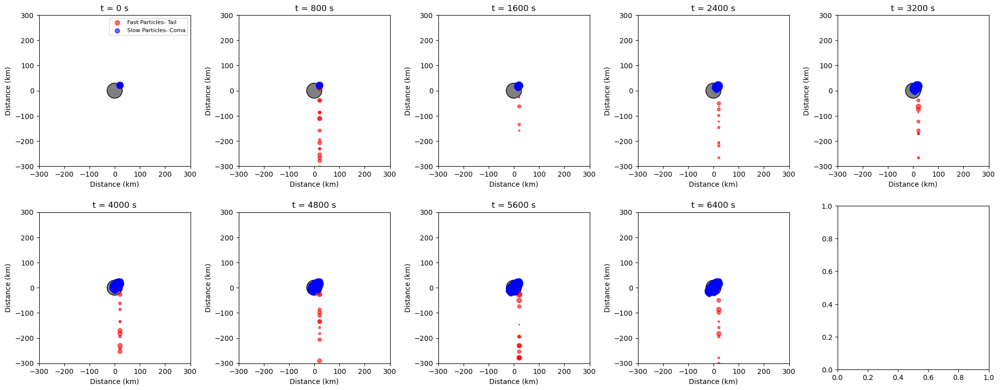

In [49]:
# Comet physical properties
G = 6.67e-11                                 # m^3 / kg / s^2
nucleus_radius_km = 30                       # km
nucleus_radius    = nucleus_radius_km * 1e3  # m
nucleus_density   = 500                      # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3 # m^3
nucleus_mass      = nucleus_density * nucleus_volume  # kg

# Simulation parameters
n_particles         = 10000     # The number of ejected particles from the outburst. 
simulation_duration = 2*3600    # 2 hours in seconds. 
n_snapshots         = 10        # The number of snapshots being shown in the figure. 
snapshot_times      = np.linspace(0, simulation_duration, n_snapshots)
dt                  = 1.0       # 1s timestep for the simulation. 
n_steps             = int(simulation_duration / dt)

# nucleus rotation: 57 day period
spin_period = 57 * 24 * 3600         # seconds
omega_spin  = 2*np.pi / spin_period  # orbital velocity

# continuous emission for first 7000 seconds (model purposes)
emission_duration = 7000
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size & markers
mean_d   = 1e-6    # meters
sigma_d  = 0.3e-6  # standard deviation
d        = np.random.normal(mean_d, sigma_d, n_particles) # Random normal (Gaussian) size distribution of ejected particles
d        = np.clip(d, 1e-7, None)  # minimum size is set to 1e-7 so particles don't have negative size. 
r        = d/2                 # radius of the ejected particles
rho_dust = 1000                # kg/m^3
m        = (4/3)*np.pi*r**3 * rho_dust # mass of the ejected particles
marker_s = 20 * (d/mean_d)**2

# Fast vs slow particle split
# Fraction was used: this is not a precise model. It was used for the purpose of simulating the coma and the tail of 29P. 
# THe escape velocity of the particles is found such that: 
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)  # which is ≈ ~16 m/s
# If the speed of the particle is > than the v_escape, then the particle will escape to the tail of the comet
# If the speed of the particle is < than the v_escape, then the particle will not escape and will create the coma of the comet

# 30% of ejected particles are set to be fast moving particles that simulate the tail of the comet as it moves. 
frac_fast = 0.3   # Fraction of fast moving particles.
n_fast    = int(frac_fast * n_particles) # total number of fast moving particles. 
is_fast   = np.zeros(n_particles, bool)  
is_fast[:n_fast] = True
np.random.shuffle(is_fast)

# fast tail: cone ±30° around 45°, speed ~300±50 m/s
cone     = np.deg2rad(30)
dev_fast = np.random.uniform(-cone, cone, n_fast)
v_fast   = np.clip(np.random.normal(17, 0, n_fast), 0, None)

# 70% of ejected particles are set to be slow moving so it simulates the coma formed around the comet nucleus. 
# slow coma: isotropic 0–2π, speed ~100±50 m/s 
n_slow   = n_particles - n_fast
dev_slow = np.random.uniform(0, 2*np.pi, n_slow)
v_slow = np.clip(np.random.normal(4, 1, n_slow), 0, 9)

# assemble speed & angle arrays
v_mag     = np.zeros(n_particles)
theta_dev = np.zeros(n_particles)
v_mag[ is_fast] = v_fast
theta_dev[ is_fast] = dev_fast
v_mag[~is_fast] = v_slow
theta_dev[~is_fast] = dev_slow

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius*np.cos(base_angle),
                      nucleus_radius*np.sin(base_angle)],
                     (n_particles,1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# comet bulk drift (12 km/s upward)
v_comet = np.array([0.0, -12000])

# storage for snapshots
snapshots = []
times     = snapshot_times.copy()
snap_i    = 0

# Main simulation loop
for step in range(n_steps):
    t = step * dt

    # rotating jet direction & eruption point
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius*np.cos(phi0),
                     nucleus_radius*np.sin(phi0)])

    # emit new particles at their emission times
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]
        thetas = np.zeros(len(idx))

        fast_local = is_fast[idx]
        # fast: φ₀ + cone dev
        thetas[fast_local] = phi0 + theta_dev[idx][fast_local]
        # slow: isotropic (phi0 ignored, dev_slow gives full 0–2π)
        thetas[~fast_local] = theta_dev[idx][~fast_local]

        # assign velocities:
        #   slow: only their v_slow * direction
        #   fast:            v_fast * direction + v_comet drift
        velocities[idx,0] = np.cos(thetas) * v_mag[idx] + fast_local * v_comet[0]
        velocities[idx,1] = np.sin(thetas) * v_mag[idx] + fast_local * v_comet[1]

        # start at rotating eruption point
        positions[idx] = epic

    # Gravity applied on all ejected dust particles.
    # Gravity is calculated using F = GM / d^3
    if emitted.any():
        vec  = positions[emitted]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G * nucleus_mass / dist**3 * vec

        velocities[emitted] += acc * dt
        positions[emitted]  += velocities[emitted] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plot 2×5 scatter: red=fast, blue=slow
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, ax) in enumerate(zip(snapshots, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-300, 300)
    ax.set_ylim(-300, 300)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")

    # nucleus
    circ = plt.Circle((0,0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    # fast particles in red
    xf = pos[is_fast,0]/1e3
    yf = pos[is_fast,1]/1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=0.6, label='Fast Particles- Tail')

    # slow particles in blue
    xs = pos[~is_fast,0]/1e3
    ys = pos[~is_fast,1]/1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=0.6, label='Slow Particles- Coma')

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


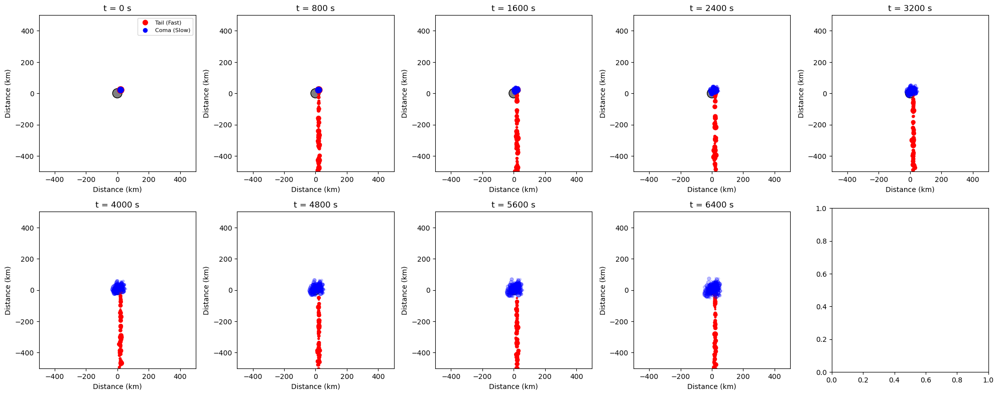

In [50]:
# Comet physical properties
G = 6.67e-11
nucleus_radius_km = 30
nucleus_radius    = nucleus_radius_km * 1e3  # m
nucleus_density   = 500                      # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3
nucleus_mass      = nucleus_density * nucleus_volume

# Calculate surface escape velocity
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 10000
simulation_duration = 2 * 3600
n_snapshots         = 10
snapshot_times      = np.linspace(0, simulation_duration, n_snapshots)
dt                  = 1.0
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600
omega_spin  = 2 * np.pi / spin_period

# Emission timing
emission_duration = 7000
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
d        = np.clip(d, 1e-7, None)
r        = d / 2
rho_dust = 1000
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    if emitted.any():
        vec  = positions[emitted]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G * nucleus_mass / dist**3 * vec
        velocities[emitted] += acc * dt
        positions[emitted]  += velocities[emitted] * dt

    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


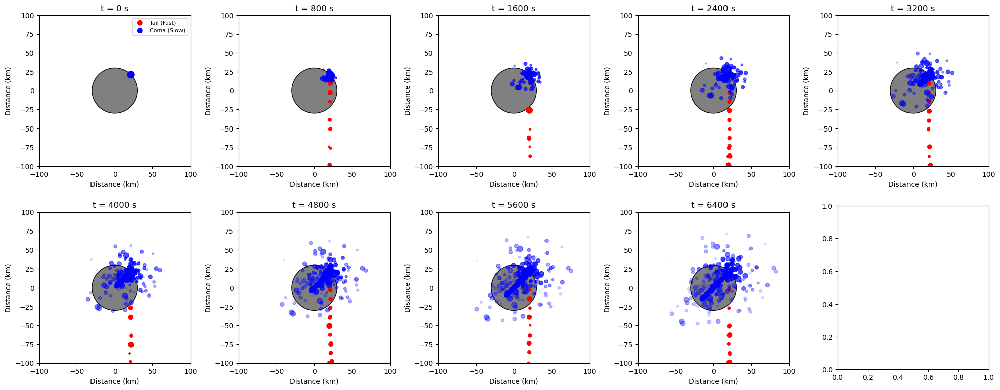

In [51]:
# Comet physical properties
G = 6.67e-11
nucleus_radius_km = 30
nucleus_radius    = nucleus_radius_km * 1e3  # m
nucleus_density   = 500                      # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3
nucleus_mass      = nucleus_density * nucleus_volume

# Calculate surface escape velocity
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 10000
simulation_duration = 2 * 3600
n_snapshots         = 10
snapshot_times      = np.linspace(0, simulation_duration, n_snapshots)
dt                  = 1.0
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600
omega_spin  = 2 * np.pi / spin_period

# Emission timing
emission_duration = 7000
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
d        = np.clip(d, 1e-7, None)
r        = d / 2
rho_dust = 1000
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    if emitted.any():
        vec  = positions[emitted]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G * nucleus_mass / dist**3 * vec
        velocities[emitted] += acc * dt
        positions[emitted]  += velocities[emitted] * dt

    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


# BELOW CAN BE USED IN THE PAPER # 

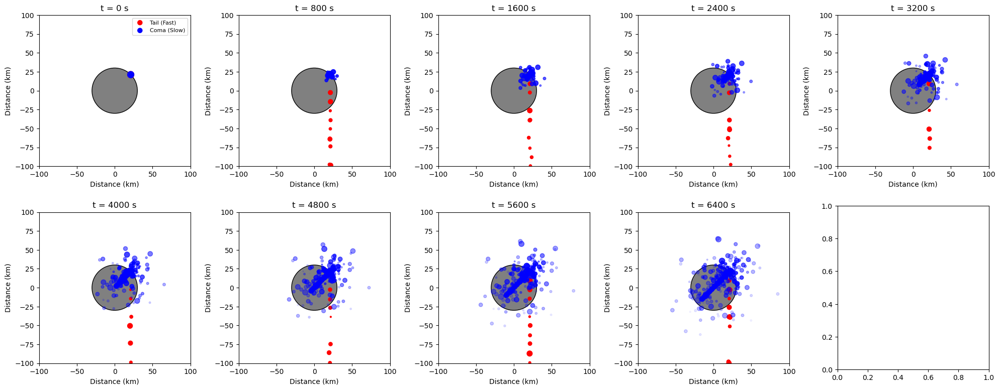

In [52]:
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
# The density of the simulation is based on the density of the comet 67P, which is precisely found 
# because of the Rossetta mission which landed on the comet. Density of 67P is 532 kg/m^3. 
nucleus_density   = 500                                # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
# If this is exceeded, then the particles will escape the coma of the comet. 
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 10000       # total number of particles
simulation_duration = 2 * 3600    # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration, n_snapshots)
dt                  = 1.0         # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
# In this model it is assumed that the duration of the outburst is the same as the duration of the simulation.
emission_duration = simulation_duration  # duration of the continuous ejection of particles.
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
# A minimum size of the smallest particles is set so there are no negative values (sizes) included. 
d        = np.clip(d, 1e-7, None)
r        = d / 2
# The density of the ejected particles in the simulation is set to be 1000 (water). 
# This value is adjustable for different elements. For dust, rho is approx. 1700.
rho_dust = 1000     # density of the particles.
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
# If the ejection velocity is greater than the escape velocity, then the particle is considered fast. 
# Fast particles are escaping the comet and they form the tail due to the extremely high velocity of the comet (12km/s).
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape.
# slow moving particles are not affected by this. 
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
# I wanted to simulate the fading of the particles mostly if they remain in the coma. 
# This also makes the effect more visible and the 'expired' particles also appear to move outwards slowly fading away. 
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # launch + (comet drift only for fast particles)
        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    # Apply gravity only to slow / bound particles. 
    # This forms the coma around the nucleus of the comet. 
    if emitted.any():
        emi_idx = np.where(emitted)[0]       # indices of all emitted particles.
        vec  = positions[emi_idx]            # position vector.
        dist = np.linalg.norm(vec, axis=1, keepdims=True)  # distance from nucleus.
        dist = np.maximum(dist, nucleus_radius)            # maximum distance of the particle from the nucleus.

        # Compute gravitational acceleration. 
        acc  = -G * nucleus_mass / dist**3 * vec

        # compute kinetic vs potential energy.
        # particles that have extremely high kinetic energy (> than the potential) will also escape and fade away. 
        v_vec = velocities[emi_idx]    # velocity vector
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        # condition for bound: ½ v² < GM / r
        # If the grav. potential is greater than kinetic, particles will remain bound to the nucleus. 
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)   

        # zero‐out gravity for unbound
        # no gravity effect on the particles that hava very high kinetic energy. 
        # kinetic energy is also affected by the mass and the velocity of the particles. 
        acc[~bound_mask.flatten()] = 0

        # apply only to the emitted subset
        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


Same Code as above, just increased the simulation period to 5 hours and the number of particles to 50000

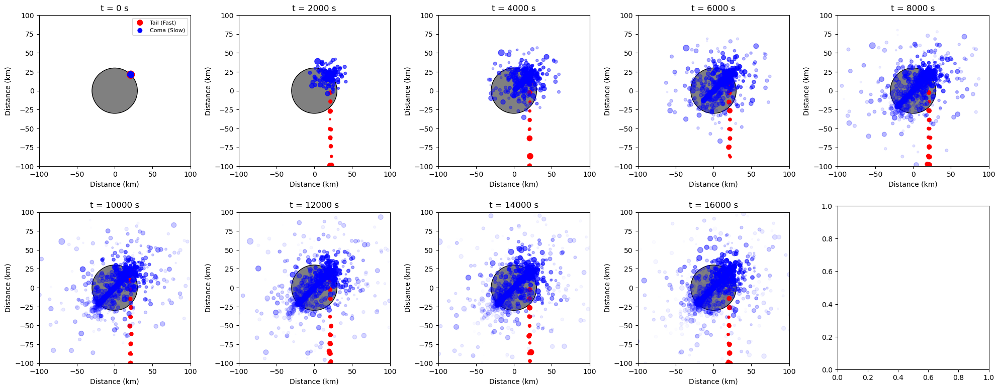

In [53]:
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
# The density of the simulation is based on the density of the comet 67P, which is precisely found 
# because of the Rossetta mission which landed on the comet. Density of 67P is 532 kg/m^3. 
nucleus_density   = 500                                # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
# If this is exceeded, then the particles will escape the coma of the comet. 
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000       # total number of particles
simulation_duration = 5 * 3600    # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration, n_snapshots)
dt                  = 1.0         # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
# In this model it is assumed that the duration of the outburst is the same as the duration of the simulation.
emission_duration = simulation_duration  # duration of the continuous ejection of particles.
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
# A minimum size of the smallest particles is set so there are no negative values (sizes) included. 
d        = np.clip(d, 1e-7, None)
r        = d / 2
# The density of the ejected particles in the simulation is set to be 1000 (water). 
# This value is adjustable for different elements. For dust, rho is approx. 1700.
rho_dust = 1000     # density of the particles.
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
# If the ejection velocity is greater than the escape velocity, then the particle is considered fast. 
# Fast particles are escaping the comet and they form the tail due to the extremely high velocity of the comet (12km/s).
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape.
# slow moving particles are not affected by this. 
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
# I wanted to simulate the fading of the particles mostly if they remain in the coma. 
# This also makes the effect more visible and the 'expired' particles also appear to move outwards slowly fading away. 
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # launch + (comet drift only for fast particles)
        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    # Apply gravity only to slow / bound particles. 
    # This forms the coma around the nucleus of the comet. 
    if emitted.any():
        emi_idx = np.where(emitted)[0]       # indices of all emitted particles.
        vec  = positions[emi_idx]            # position vector.
        dist = np.linalg.norm(vec, axis=1, keepdims=True)  # distance from nucleus.
        dist = np.maximum(dist, nucleus_radius)            # maximum distance of the particle from the nucleus.

        # Compute gravitational acceleration. 
        acc  = -G * nucleus_mass / dist**3 * vec

        # compute kinetic vs potential energy.
        # particles that have extremely high kinetic energy (> than the potential) will also escape and fade away. 
        v_vec = velocities[emi_idx]    # velocity vector
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        # condition for bound: ½ v² < GM / r
        # If the grav. potential is greater than kinetic, particles will remain bound to the nucleus. 
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)   

        # zero‐out gravity for unbound
        # no gravity effect on the particles that hava very high kinetic energy. 
        # kinetic energy is also affected by the mass and the velocity of the particles. 
        acc[~bound_mask.flatten()] = 0

        # apply only to the emitted subset
        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


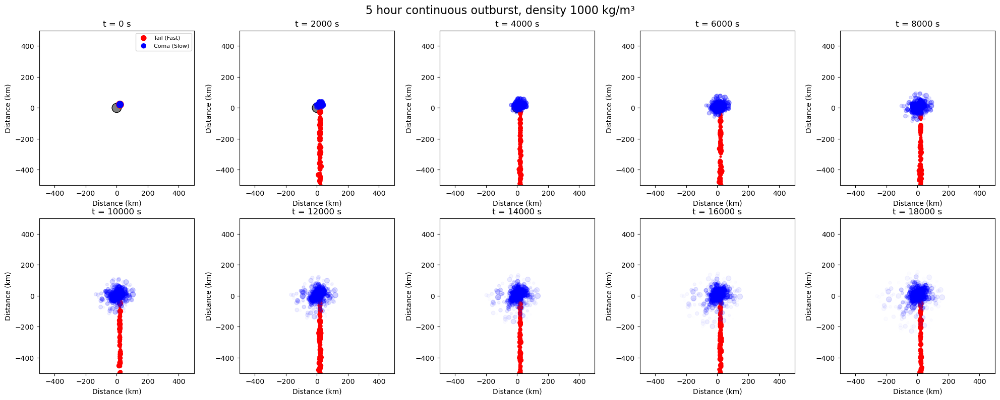

In [54]:
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
# The density of the simulation is based on the density of the comet 67P, which is precisely found 
# because of the Rossetta mission which landed on the comet. Density of 67P is 532 kg/m^3. 
nucleus_density   = 500                                # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
# If this is exceeded, then the particles will escape the coma of the comet. 
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000       # total number of particles
simulation_duration = 5 * 3600 + 1   # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration - dt , n_snapshots)
dt                  = 1           # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
# In this model it is assumed that the duration of the outburst is the same as the duration of the simulation.
emission_duration = simulation_duration  # duration of the continuous ejection of particles.
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
# A minimum size of the smallest particles is set so there are no negative values (sizes) included. 
d        = np.clip(d, 1e-7, None)
r        = d / 2
# The density of the ejected particles in the simulation is set to be 1000 (water). 
# This value is adjustable for different elements. For dust, rho is approx. 1700.
rho_dust = 1000     # density of the particles.
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
# If the ejection velocity is greater than the escape velocity, then the particle is considered fast. 
# Fast particles are escaping the comet and they form the tail due to the extremely high velocity of the comet (12km/s).
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape.
# slow moving particles are not affected by this. 
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
# I wanted to simulate the fading of the particles mostly if they remain in the coma. 
# This also makes the effect more visible and the 'expired' particles also appear to move outwards slowly fading away. 
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # launch + (comet drift only for fast particles)
        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    # Apply gravity only to slow / bound particles. 
    # This forms the coma around the nucleus of the comet. 
    if emitted.any():
        emi_idx = np.where(emitted)[0]       # indices of all emitted particles.
        vec  = positions[emi_idx]            # position vector.
        dist = np.linalg.norm(vec, axis=1, keepdims=True)  # distance from nucleus.
        dist = np.maximum(dist, nucleus_radius)            # maximum distance of the particle from the nucleus.

        # Compute gravitational acceleration. 
        acc  = -G * nucleus_mass / dist**3 * vec

        # compute kinetic vs potential energy.
        # particles that have extremely high kinetic energy (> than the potential) will also escape and fade away. 
        v_vec = velocities[emi_idx]    # velocity vector
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        # condition for bound: ½ v² < GM / r
        # If the grav. potential is greater than kinetic, particles will remain bound to the nucleus. 
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)   

        # zero‐out gravity for unbound
        # no gravity effect on the particles that hava very high kinetic energy. 
        # kinetic energy is also affected by the mass and the velocity of the particles. 
        acc[~bound_mask.flatten()] = 0

        # apply only to the emitted subset
        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

fig.suptitle("5 hour continuous outburst, density 1000 kg/m³", fontsize=16)
plt.tight_layout()
plt.show()


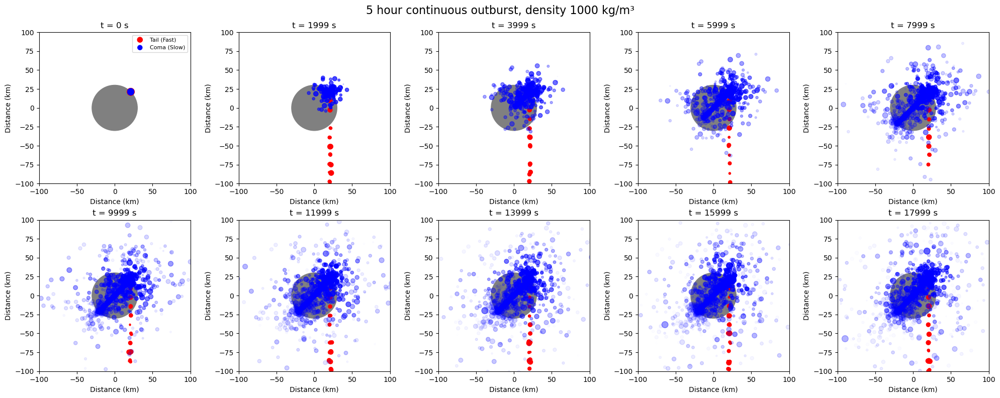

In [55]:
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
# The density of the simulation is based on the density of the comet 67P, which is precisely found 
# because of the Rossetta mission which landed on the comet. Density of 67P is 532 kg/m^3. 
nucleus_density   = 500                                # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
# If this is exceeded, then the particles will escape the coma of the comet. 
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000       # total number of particles
simulation_duration = 5 * 3600    # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)
dt                  = 1           # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
# In this model it is assumed that the duration of the outburst is the same as the duration of the simulation.
emission_duration = simulation_duration  # duration of the continuous ejection of particles.
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
# A minimum size of the smallest particles is set so there are no negative values (sizes) included. 
d        = np.clip(d, 1e-7, None)
r        = d / 2
# The density of the ejected particles in the simulation is set to be 1000 (water). 
# This value is adjustable for different elements. For dust, rho is approx. 1700.
rho_dust = 1000     # density of the particles.
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
# If the ejection velocity is greater than the escape velocity, then the particle is considered fast. 
# Fast particles are escaping the comet and they form the tail due to the extremely high velocity of the comet (12km/s).
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape.
# slow moving particles are not affected by this. 
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
# I wanted to simulate the fading of the particles mostly if they remain in the coma. 
# This also makes the effect more visible and the 'expired' particles also appear to move outwards slowly fading away. 
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # launch + (comet drift only for fast particles)
        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    # Apply gravity only to slow / bound particles. 
    # This forms the coma around the nucleus of the comet. 
    if emitted.any():
        emi_idx = np.where(emitted)[0]       # indices of all emitted particles.
        vec  = positions[emi_idx]            # position vector.
        dist = np.linalg.norm(vec, axis=1, keepdims=True)  # distance from nucleus.
        dist = np.maximum(dist, nucleus_radius)            # maximum distance of the particle from the nucleus.

        # Compute gravitational acceleration. 
        acc  = -G * nucleus_mass / dist**3 * vec

        # compute kinetic vs potential energy.
        # particles that have extremely high kinetic energy (> than the potential) will also escape and fade away. 
        v_vec = velocities[emi_idx]    # velocity vector
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        # condition for bound: ½ v² < GM / r
        # If the grav. potential is greater than kinetic, particles will remain bound to the nucleus. 
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)   

        # zero‐out gravity for unbound
        # no gravity effect on the particles that hava very high kinetic energy. 
        # kinetic energy is also affected by the mass and the velocity of the particles. 
        acc[~bound_mask.flatten()] = 0

        # apply only to the emitted subset
        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey')
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)')

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)')

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
fig.suptitle("5 hour continuous outburst, density 1000 kg/m³", fontsize=16)
plt.tight_layout()
plt.show()


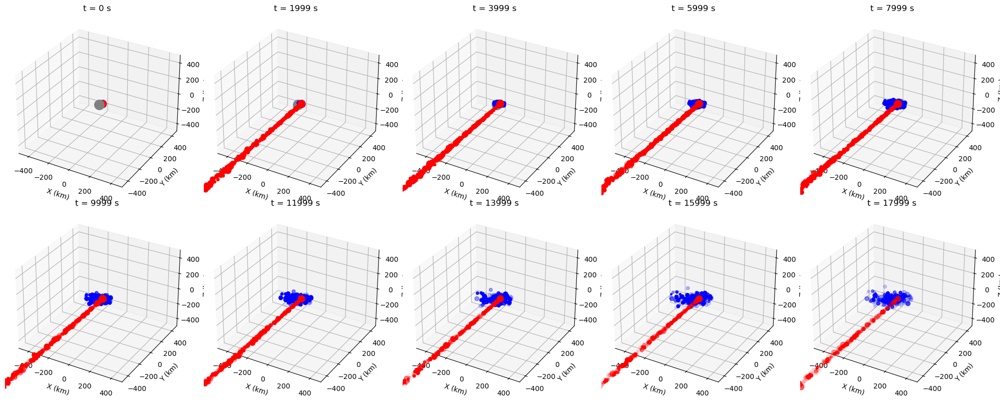

In [56]:
from mpl_toolkits.mplot3d import Axes3D  # for 3D projection

# Comet physical properties
G = 6.67e-11
nucleus_radius_km = 30
nucleus_radius    = nucleus_radius_km * 1e3
nucleus_density   = 500
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3
nucleus_mass      = nucleus_density * nucleus_volume

# Calculate surface escape velocity
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000
simulation_duration = 5 * 3600
n_snapshots         = 10
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)
dt                  = 1.0
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600
omega_spin  = 2 * np.pi / spin_period

# Emission timing
emission_duration = simulation_duration
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size & mass
mean_d   = 1e-6; sigma_d = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
d        = np.clip(d, 1e-7, None)
r        = d / 2
rho_dust = 1000
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity & direction
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)
theta_dev= np.random.uniform(0, 2*np.pi, n_particles)
is_fast  = v_eject >= v_escape

# Initial arrays: promote to 3D by adding zero z
base_angle = np.deg2rad(45)
xy0        = np.array([nucleus_radius * np.cos(base_angle),
                       nucleus_radius * np.sin(base_angle)])
positions  = np.tile(np.hstack([xy0, 0.0]), (n_particles, 1))  # (N,3)
velocities = np.zeros_like(positions)                         # (N,3)
emitted    = np.zeros(n_particles, bool)

# Comet drift (3D): only for fast
v_comet = np.array([0.0, -12000, 0.0])

# Fading
tau_base = 3600
tau_eff  = tau_base * (d / mean_d)
snapshots       = []
snapshots_alpha = []
times           = snapshot_times.copy()
snap_i          = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius*np.cos(phi0),
                     nucleus_radius*np.sin(phi0),
                     0.0])

    # Emit
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]
        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        fast_l = is_fast[idx].astype(float)

        velocities[idx, 0] = np.cos(thetas) * v_vals + fast_l * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + fast_l * v_comet[1]
        velocities[idx, 2] = 0.0
        positions[idx]     = epic

    # Gravity
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec     = positions[emi_idx]
        dist    = np.linalg.norm(vec, axis=1, keepdims=True)
        dist    = np.maximum(dist, nucleus_radius)
        acc     = -G * nucleus_mass / dist**3 * vec

        # kinetic vs potential for escape (as before)
        v_vec     = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound     = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound.flatten()] = 0

        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # Snapshot + fading
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age    = np.maximum(t - emission_times, 0)
        alpha  = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plot 2×5 3D scatter panels
fig = plt.figure(figsize=(20, 8))
axes = [fig.add_subplot(2, 5, i+1, projection='3d') for i in range(n_snapshots)]

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlim(-500, 500); ax.set_ylim(-500, 500); ax.set_zlim(-500, 500)
    ax.set_xlabel("X (km)"); ax.set_ylabel("Y (km)"); ax.set_zlabel("Z (km)")

    # nucleus
    ax.scatter(0, 0, 0, color='grey', s=200, zorder=5)

    # fast (red)
    xf = pos[is_fast, 0]/1e3; yf = pos[is_fast, 1]/1e3; zf = pos[is_fast, 2]/1e3
    ax.scatter(xf, yf, zf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], zorder=1)

    # slow (blue)
    xs = pos[~is_fast, 0]/1e3; ys = pos[~is_fast, 1]/1e3; zs = pos[~is_fast, 2]/1e3
    ax.scatter(xs, ys, zs, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], zorder=1)

plt.tight_layout()
plt.show()


Extra scattering cross‐section ΔA: 1.51e+08 m^2
Solar flux at 6.0 AU: 37.81 W/m^2
Estimated total dust luminosity: 2.29e+08 W
Mean per‐grain L: 1.29e-12 W, Total (all grains): 6.47e-08 W


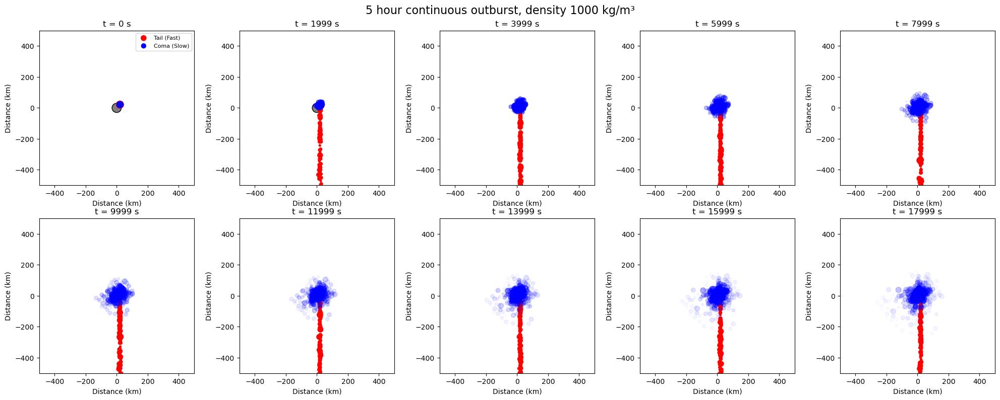

In [57]:
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
nucleus_density   = 500                      # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000      # total number of particles
simulation_duration = 5 * 3600    # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)
dt                  = 1           # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
emission_duration = simulation_duration
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
d        = np.clip(d, 1e-7, None)
r        = d / 2
rho_dust = 1000
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Reflectivity / Luminosity calculation 
delta_m    = 1.0       # Brightness change during outburst (mag)
A0         = 1e8       # Baseline scattering cross‐section (m^2)
albedo     = 0.04      # Dust albedo
r_h        = 6.0       # Sun‐comet distance (AU)
F_sun_1AU  = 1361      # W/m^2 at 1 AU
F_sun      = F_sun_1AU / (r_h**2)

# extra cross‐section needed for 1‐mag change
delta_A = A0 * (10**(0.4 * delta_m) - 1)

# global dust luminosity
L_dust = albedo * F_sun * delta_A

print(f"Extra scattering cross‐section ΔA: {delta_A:.2e} m^2")
print(f"Solar flux at {r_h} AU: {F_sun:.2f} W/m^2")
print(f"Estimated total dust luminosity: {L_dust:.2e} W")

# per‐particle scattering luminosity
cross_section = np.pi * r**2               # m^2 per grain
L_particle    = albedo * F_sun * cross_section  # W per grain

print(f"Mean per‐grain L: {L_particle.mean():.2e} W, "
      f"Total (all grains): {L_particle.sum():.2e} W")

# Ejection velocity: assign from single normal distribution
v_eject   = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift (only for fast grains)
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
tau_base        = 3600
tau_eff         = tau_base * (d / mean_d)
snapshots       = []
snapshots_alpha = []
times           = snapshot_times.copy()
snap_i          = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas        = theta_dev[idx]
        v_vals        = v_eject[idx]
        is_fast_local = is_fast[idx]

        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    # Apply gravity only to bound (slow) grains
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec     = positions[emi_idx]
        dist    = np.linalg.norm(vec, axis=1, keepdims=True)
        dist    = np.maximum(dist, nucleus_radius)
        acc     = -G * nucleus_mass / dist**3 * vec

        v_vec     = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound     = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound.flatten()] = 0

        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age        = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
fig.suptitle("5 hour continuous outburst, density 1000 kg/m³", fontsize=16)
plt.tight_layout()
plt.show()


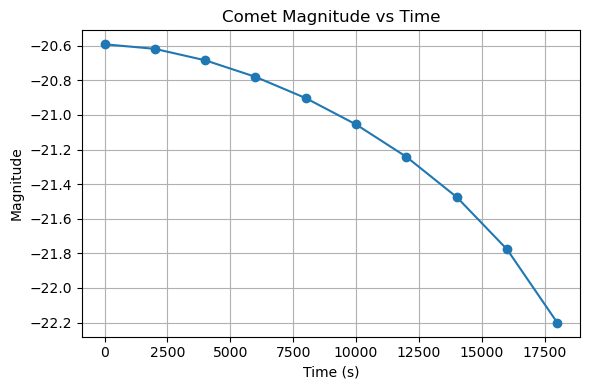

In [58]:
# Constants
albedo    = 0.3
r_h       = 6.0
F_sun_1AU = 1361.0
F_sun     = F_sun_1AU / (r_h**2)       # W/m^2 at comet distance
A0        = 1e8                        # reference cross‐section for Δm=1

# Compute per‐grain cross-section (m^2)
cross_section = np.pi * (d/2)**2

# Total scattered luminosity at each snapshot
L_snap = np.array([
    albedo * F_sun * np.sum(cross_section * alpha_vals)
    for alpha_vals in snapshots_alpha
])

# Reference luminosity for a 1-mag increase
L_ref   = albedo * F_sun * A0

m0 = 17.83       # Source: https://theskylive.com/how-bright-is-29p#:~:text=The%20current%20visual%20magnitude%20of%20Comet%2029P%2FSchwassmann-Wachmann%20is,an%20aperture%20of%206%20inches%20%28150mm%29%20or%20more.

# Compute the magnitude change Δm(t)
# Δm = 2.5 * log10( L_ref / L_snap )
delta_m = 2.5 * np.log10(L_ref / L_snap)

# Compute the actual magnitude at each time
# Brightening by Δm makes the numeric magnitude go down
m_t = m0 - delta_m

# Slice times to match the length of m_t
t_plot = times[: len(m_t)]

# Plot
plt.figure(figsize=(6,4))
plt.plot(t_plot, m_t, '-o')
plt.xlabel('Time (s)')
plt.ylabel('Magnitude')
plt.title('Comet Magnitude vs Time')
plt.grid(True)
plt.tight_layout()
plt.show()



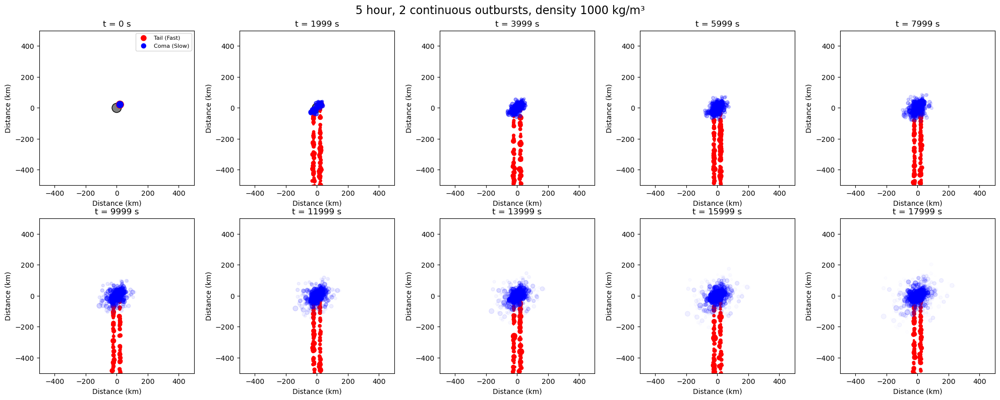

In [59]:
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
# The density of the simulation is based on the density of the comet 67P, which is precisely found 
# because of the Rossetta mission which landed on the comet. Density of 67P is 532 kg/m^3. 
nucleus_density   = 500                                # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
# If this is exceeded, then the particles will escape the coma of the comet. 
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000       # total number of particles
simulation_duration = 5 * 3600    # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)
dt                  = 1           # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
# In this model it is assumed that the duration of the outburst is the same as the duration of the simulation.
emission_duration = simulation_duration  # duration of the continuous ejection of particles.
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
# A minimum size of the smallest particles is set so there are no negative values (sizes) included. 
d        = np.clip(d, 1e-7, None)
r        = d / 2
# The density of the ejected particles in the simulation is set to be 1000 (water). 
# This value is adjustable for different elements. For dust, rho is approx. 1700.
rho_dust = 1000     # density of the particles.
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
# If the ejection velocity is greater than the escape velocity, then the particle is considered fast. 
# Fast particles are escaping the comet and they form the tail due to the extremely high velocity of the comet (12km/s).
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape.
# slow moving particles are not affected by this. 
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
# I wanted to simulate the fading of the particles mostly if they remain in the coma. 
# This also makes the effect more visible and the 'expired' particles also appear to move outwards slowly fading away. 
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t

    # We'll launch particles from two opposing jets: φ0 and φ0 + π
    epic_1 = np.array([nucleus_radius * np.cos(phi0),
                          nucleus_radius * np.sin(phi0)])
    epic_2  = np.array([nucleus_radius * np.cos(phi0 + np.pi),
                          nucleus_radius * np.sin(phi0 + np.pi)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]
        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # Each particle randomly assigned to main jet or opposite side
        jet_side = np.random.choice([0, 1], size=len(idx))  # 0: φ0, 1: φ0+π
        phi_launch = phi0 + jet_side * np.pi
        eruption_x = nucleus_radius * np.cos(phi_launch)
        eruption_y = nucleus_radius * np.sin(phi_launch)
        positions[idx, 0] = eruption_x
        positions[idx, 1] = eruption_y

        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]

    # Apply gravity only to bound particles
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec  = positions[emi_idx]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G * nucleus_mass / dist**3 * vec

        v_vec     = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound_mask.flatten()] = 0

        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # Record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
fig.suptitle("5 hour, 2 continuous outbursts, density 1000 kg/m³", fontsize=16)
plt.tight_layout()
plt.show()


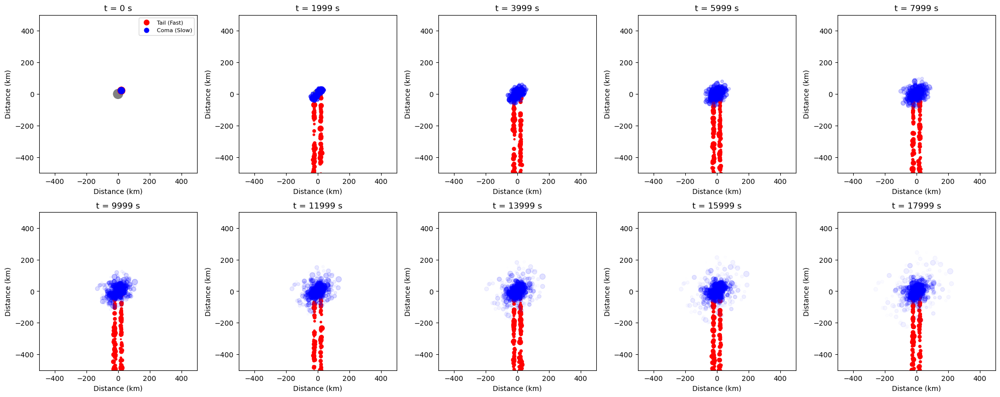

In [60]:
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
# The density of the simulation is based on the density of the comet 67P, which is precisely found 
# because of the Rossetta mission which landed on the comet. Density of 67P is 532 kg/m^3. 
nucleus_density   = 500                                # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
# If this is exceeded, then the particles will escape the coma of the comet. 
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000       # total number of particles
simulation_duration = 5 * 3600    # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)
dt                  = 1           # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
# In this model it is assumed that the duration of the outburst is the same as the duration of the simulation.
emission_duration = simulation_duration  # duration of the continuous ejection of particles.
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
# A minimum size of the smallest particles is set so there are no negative values (sizes) included. 
d        = np.clip(d, 1e-7, None)
r        = d / 2
# The density of the ejected particles in the simulation is set to be 1000 (water). 
# This value is adjustable for different elements. For dust, rho is approx. 1700.
rho_dust = 1000     # density of the particles.
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
# If the ejection velocity is greater than the escape velocity, then the particle is considered fast. 
# Fast particles are escaping the comet and they form the tail due to the extremely high velocity of the comet (12km/s).
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape.
# slow moving particles are not affected by this. 
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
# I wanted to simulate the fading of the particles mostly if they remain in the coma. 
# This also makes the effect more visible and the 'expired' particles also appear to move outwards slowly fading away. 
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t

    # We'll launch particles from two opposing jets: φ0 and φ0 + π
    epic_1 = np.array([nucleus_radius * np.cos(phi0),
                          nucleus_radius * np.sin(phi0)])
    epic_2  = np.array([nucleus_radius * np.cos(phi0 + np.pi),
                          nucleus_radius * np.sin(phi0 + np.pi)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]
        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # Each particle randomly assigned to main jet or opposite side
        jet_side = np.random.choice([0, 1], size=len(idx))  # 0: φ0, 1: φ0+π
        phi_launch = phi0 + jet_side * np.pi
        eruption_x = nucleus_radius * np.cos(phi_launch)
        eruption_y = nucleus_radius * np.sin(phi_launch)
        positions[idx, 0] = eruption_x
        positions[idx, 1] = eruption_y

        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]

    # Apply gravity only to bound particles
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec  = positions[emi_idx]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G * nucleus_mass / dist**3 * vec

        v_vec     = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound_mask.flatten()] = 0

        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # Record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey')
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)')

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)')

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()


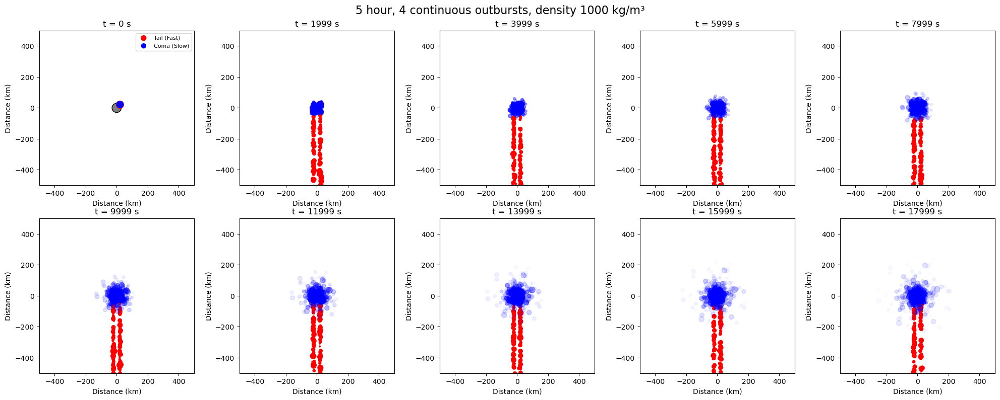

In [61]:
# Comet physical properties
G = 6.67e-11
nucleus_radius_km = 30
nucleus_radius    = nucleus_radius_km * 1e3
nucleus_density   = 500
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3
nucleus_mass      = nucleus_density * nucleus_volume

v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000
simulation_duration = 5 * 3600
n_snapshots         = 10
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)
dt                  = 1
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600
omega_spin  = 2 * np.pi / spin_period

# Emission timing
emission_duration = simulation_duration
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d  = 1e-6
sigma_d = 0.3e-6
d       = np.random.normal(mean_d, sigma_d, n_particles)
d       = np.clip(d, 1e-7, None)
r       = d / 2
rho_dust = 1000
m       = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity and direction
v_eject   = np.clip(np.random.normal(120, 80, n_particles), 0, None)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)
is_fast   = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet bulk drift (applied only to fast particles)
v_comet = np.array([0.0, -12000])

# Fading setup
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]
        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # Randomly assign each particle to one of four eruption points
        jet_side = np.random.choice([0, 1, 2, 3], size=len(idx))
        phi_launch = phi0 + np.where(jet_side == 0, 0,
                            np.where(jet_side == 1, np.pi,
                            np.where(jet_side == 2, np.pi/2, -np.pi/2)))

        eruption_x = nucleus_radius * np.cos(phi_launch)
        eruption_y = nucleus_radius * np.sin(phi_launch)
        positions[idx, 0] = eruption_x
        positions[idx, 1] = eruption_y

        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]

    # Apply gravity to bound particles
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec  = positions[emi_idx]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G * nucleus_mass / dist**3 * vec

        v_vec     = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound_mask.flatten()] = 0

        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # Record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting 2×5 grid
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
fig.suptitle("5 hour, 4 continuous outbursts, density 1000 kg/m³", fontsize=16)
plt.tight_layout()
plt.show()


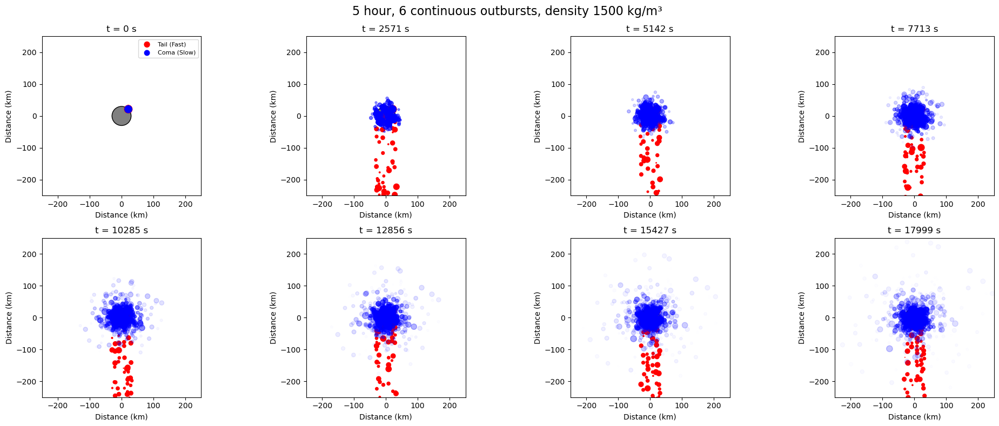

In [62]:
# Comet physical properties
G = 6.67e-11
nucleus_radius_km = 30
nucleus_radius    = nucleus_radius_km * 1e3
nucleus_density   = 500
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3
nucleus_mass      = nucleus_density * nucleus_volume

v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000
simulation_duration = 5 * 3600
n_snapshots         = 8
snapshot_times      = np.linspace(0, simulation_duration -dt, n_snapshots)
dt                  = 1
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600
omega_spin  = 2 * np.pi / spin_period

# Emission timing
emission_duration = simulation_duration
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d  = 1e-6
sigma_d = 0.3e-6
d       = np.random.normal(mean_d, sigma_d, n_particles)
d       = np.clip(d, 1e-7, None)
r       = d / 2
rho_dust = 1500
m       = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity and direction
v_eject   = np.clip(np.random.normal(120, 80, n_particles), 0, None)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)
is_fast   = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet bulk drift (applied only to fast particles)
v_comet = np.array([0.0, -12000])

# Fading setup
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]
        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # Assign particles to one of six rotating jets spaced every 60°
        jet_side = np.random.choice(6, size=len(idx))  # values 0–5
        phi_launch = phi0 + jet_side * (np.pi / 3)     # adds 0, 60°, ..., 300°

        eruption_x = nucleus_radius * np.cos(phi_launch)
        eruption_y = nucleus_radius * np.sin(phi_launch)
        positions[idx, 0] = eruption_x
        positions[idx, 1] = eruption_y

        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]

    # Apply gravity to bound particles
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec  = positions[emi_idx]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc  = -G * nucleus_mass / dist**3 * vec

        v_vec     = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound_mask.flatten()] = 0

        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # Record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting 2×5 grid
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-250, 250)
    ax.set_ylim(-250, 250)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
fig.suptitle("5 hour, 6 continuous outbursts, density 1500 kg/m³", fontsize=16)
plt.tight_layout()
plt.show()


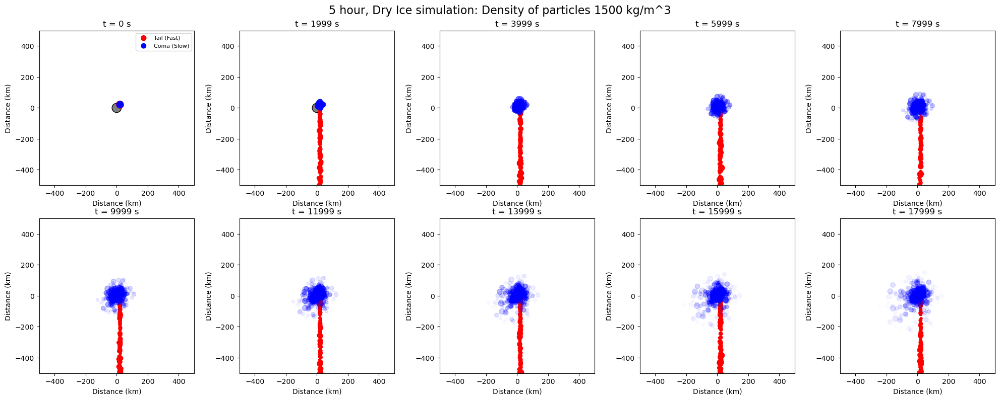

In [63]:
# Code for density 1500 kgm^-3/ Dry Ice
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
# The density of the simulation is based on the density of the comet 67P, which is precisely found 
# because of the Rossetta mission which landed on the comet. Density of 67P is 532 kg/m^3. 
nucleus_density   = 500                                # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
# If this is exceeded, then the particles will escape the coma of the comet. 
v_escape = np.sqrt(2 * G * nucleus_mass / nucleus_radius)

# Simulation parameters
n_particles         = 50000       # total number of particles
simulation_duration = 5 * 3600    # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)
dt                  = 1           # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
# In this model it is assumed that the duration of the outburst is the same as the duration of the simulation.
emission_duration = simulation_duration  # duration of the continuous ejection of particles.
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
# A minimum size of the smallest particles is set so there are no negative values (sizes) included. 
d        = np.clip(d, 1e-7, None)
r        = d / 2
# The density of the ejected particles in the simulation is set to be 1500 (dry ice). 
# This value is adjustable for different elements. For dust, rho is approx. 1700.
rho_dust = 1500     # density of the particles.
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(120, 80, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
# If the ejection velocity is greater than the escape velocity, then the particle is considered fast. 
# Fast particles are escaping the comet and they form the tail due to the extremely high velocity of the comet (12km/s).
is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape.
# slow moving particles are not affected by this. 
v_comet = np.array([0.0, -12000])

# Optional fading (linked to particle size)
# I wanted to simulate the fading of the particles mostly if they remain in the coma. 
# This also makes the effect more visible and the 'expired' particles also appear to move outwards slowly fading away. 
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # launch + (comet drift only for fast particles)
        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    # Apply gravity only to slow / bound particles. 
    # This forms the coma around the nucleus of the comet. 
    if emitted.any():
        emi_idx = np.where(emitted)[0]       # indices of all emitted particles.
        vec  = positions[emi_idx]            # position vector.
        dist = np.linalg.norm(vec, axis=1, keepdims=True)  # distance from nucleus.
        dist = np.maximum(dist, nucleus_radius)            # maximum distance of the particle from the nucleus.

        # Compute gravitational acceleration. 
        acc  = -G * nucleus_mass / dist**3 * vec

        # compute kinetic vs potential energy.
        # particles that have extremely high kinetic energy (> than the potential) will also escape and fade away. 
        v_vec = velocities[emi_idx]    # velocity vector
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        # condition for bound: ½ v² < GM / r
        # If the grav. potential is greater than kinetic, particles will remain bound to the nucleus. 
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)   

        # zero‐out gravity for unbound
        # no gravity effect on the particles that hava very high kinetic energy. 
        # kinetic energy is also affected by the mass and the velocity of the particles. 
        acc[~bound_mask.flatten()] = 0

        # apply only to the emitted subset
        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='red',
               alpha=alpha[is_fast], label='Tail (Fast)', zorder=1)

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast], label='Coma (Slow)', zorder=1)

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
        
fig.suptitle("5 hour, Dry Ice simulation: Density of particles 1500 kg/m^3", fontsize=16)        
plt.tight_layout()
plt.show()


C:\Users\stels\AppData\Local\Temp\ipykernel_16412\341634453.py:164: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



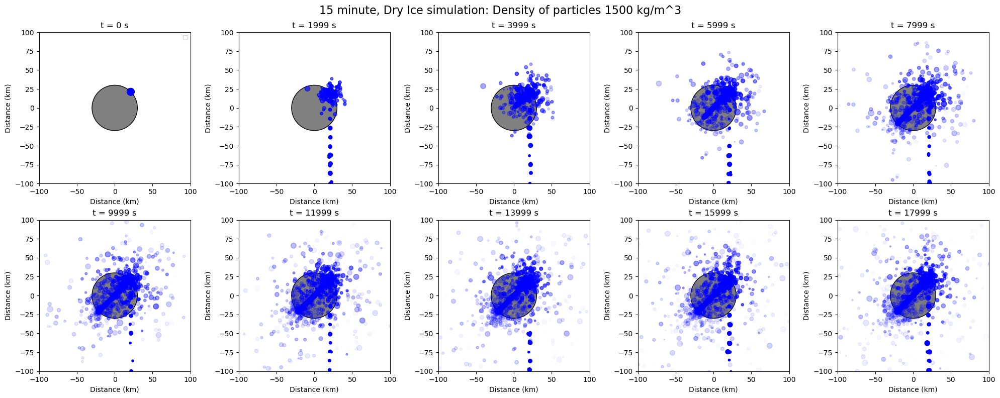

In [80]:
# Code for density 1500 kgm^-3/ Dry Ice
# Comet physical properties
G = 6.67e-11                                 # Grevitational constant 
nucleus_radius_km = 30                       # km 
nucleus_radius    = nucleus_radius_km * 1e3  # m
# The density of the simulation is based on the density of the comet 67P, which is precisely found 
# because of the Rossetta mission which landed on the comet. Density of 67P is 532 kg/m^3. 
nucleus_density   = 500                                # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3  # m^3
nucleus_mass      = nucleus_density * nucleus_volume   # kg 

# Calculating the surface escape velocity
# If this is exceeded, then the particles will escape the coma of the comet. 
v_escape = 25      # Escape velocity in m/s 

# Simulation parameters
n_particles         = 50000       # total number of particles
simulation_duration = 15 * 60     # total simulation duration in seconds
n_snapshots         = 10          # number of snapshots shown in the final figure
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)
dt                  = 1           # timestep
n_steps             = int(simulation_duration / dt)

# Rotation of nucleus (57 day period)
spin_period = 57 * 24 * 3600          # period of rotation in seconds
omega_spin  = 2 * np.pi / spin_period # the rotational velocity of the comet's nucleus

# Emission timing
# In this model it is assumed that the duration of the outburst is the same as the duration of the simulation.
emission_duration = simulation_duration  # duration of the continuous ejection of particles.
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.random.normal(mean_d, sigma_d, n_particles)
# A minimum size of the smallest particles is set so there are no negative values (sizes) included. 
d        = np.clip(d, 1e-7, None)
r        = d / 2
# The density of the ejected particles in the simulation is set to be 1500 (dry ice). 
# This value is adjustable for different elements. For dust, rho is approx. 1700.
rho_dust = 1500     # density of the particles.
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity: assign from single normal distribution
v_eject  = np.clip(np.random.normal(20, 40, n_particles), 0, None)

# Direction: isotropic for all particles (0 to 2π)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Classify particles based on velocity relative to escape speed
# If the ejection velocity is greater than the escape velocity, then the particle is considered fast. 
# Fast particles are escaping the comet and they form the tail due to the extremely high velocity of the comet (12km/s).
'''is_fast = v_eject >= v_escape

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Comet drift: only added to particles that escape.
# slow moving particles are not affected by this. 
v_comet = np.array([0.0, -12000])''' 

'''# Optional fading (linked to particle size)
# I wanted to simulate the fading of the particles mostly if they remain in the coma. 
# This also makes the effect more visible and the 'expired' particles also appear to move outwards slowly fading away. 
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0'''

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        is_fast_local = is_fast[idx]

        # launch + (comet drift only for fast particles)
        velocities[idx, 0] = np.cos(thetas) * v_vals + is_fast_local * v_comet[0]
        velocities[idx, 1] = np.sin(thetas) * v_vals + is_fast_local * v_comet[1]
        positions[idx]     = epic

    # Apply gravity only to slow / bound particles. 
    # This forms the coma around the nucleus of the comet. 
    if emitted.any():
        emi_idx = np.where(emitted)[0]       # indices of all emitted particles.
        vec  = positions[emi_idx]            # position vector.
        dist = np.linalg.norm(vec, axis=1, keepdims=True)  # distance from nucleus.
        dist = np.maximum(dist, nucleus_radius)            # maximum distance of the particle from the nucleus.

        # Compute gravitational acceleration. 
        acc  = -G * nucleus_mass / dist**3 * vec

        # compute kinetic vs potential energy.
        # particles that have extremely high kinetic energy (> than the potential) will also escape and fade away. 
        v_vec = velocities[emi_idx]    # velocity vector
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        # condition for bound: ½ v² < GM / r
        # If the grav. potential is greater than kinetic, particles will remain bound to the nucleus. 
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)   

        # zero‐out gravity for unbound
        # no gravity effect on the particles that hava very high kinetic energy. 
        # kinetic energy is also affected by the mass and the velocity of the particles. 
        acc[~bound_mask.flatten()] = 0

        # apply only to the emitted subset
        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    xf = pos[is_fast, 0] / 1e3
    yf = pos[is_fast, 1] / 1e3
    ax.scatter(xf, yf, s=marker_s[is_fast], c='blue',
               alpha=alpha[is_fast])

    xs = pos[~is_fast, 0] / 1e3
    ys = pos[~is_fast, 1] / 1e3
    ax.scatter(xs, ys, s=marker_s[~is_fast], c='blue',
               alpha=alpha[~is_fast])

    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
        
fig.suptitle("15 minute, Dry Ice simulation: Density of particles 1500 kg/m^3", fontsize=16)        
plt.tight_layout()
plt.show()

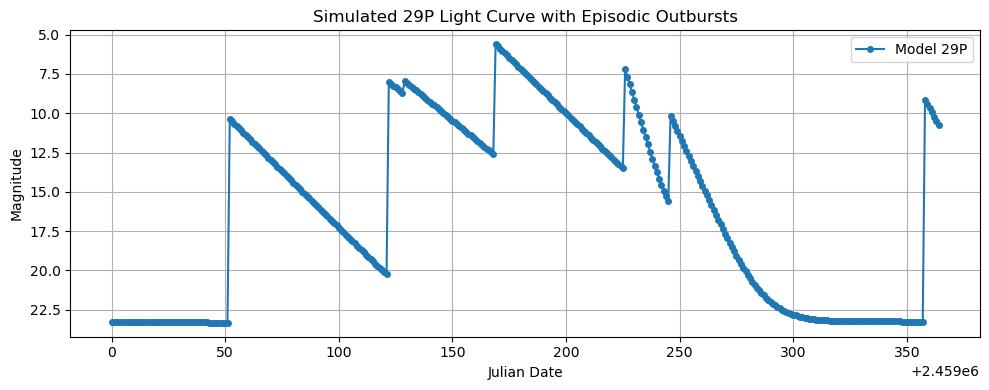

In [66]:
# Comet Geometry
albedo = 0.3                     # Typical value found in the bibliography and Google
R_nucleus = 30000                 # 30 km into m
A_nucleus = np.pi * R_nucleus**2  # m²

# Julian dates: one‐year span, daily steps
JD_start = 2459000
JD_end = JD_start + 365
dt_days = 1
JDs = np.arange(JD_start, JD_end, dt_days)
t_days = JDs - JD_start

# Approximate r_h and Δ variations (au)
r_h = 6.0 + 0.1*np.sin(2*np.pi*t_days/354)
delta = 6.0 + 0.2*np.cos(2*np.pi*t_days/354)

# Phase angle α (deg) & simple linear phase law
alpha = 10 + 5*np.cos(2*np.pi*t_days/354)
beta_phase = 0.04                      # mag per degree
phi = 10**(-beta_phase * alpha / 2.5)

# Apply Episodic outbursts in this case instead of continuous
avg_interval = 57                        # days between bursts
n_bursts = int((JD_end-JD_start)/avg_interval * 1.2)
burst_JDs = np.sort(np.random.uniform(JD_start, JD_end, n_bursts))
burst_days = burst_JDs - JD_start

# Each burst: decay timescale τᵢ (days) and dust cross-section Aᵢ (m²)
tau_days = np.random.uniform(2, 10, n_bursts)
# Calibrate Aᵢ so major bursts can yield Δm≈6 mag: ~10⁶× nucleus area
logA_mean = 6 + np.log10(A_nucleus)
logA_sigma = 0.5
A_bursts = 10**np.random.normal(logA_mean, logA_sigma, n_bursts)

# Build total dust cross‐section vs time
A_dust = np.zeros_like(t_days, float)
for t0, Ai, tau in zip(burst_days, A_bursts, tau_days):
    dt = t_days - t0
    mask = dt >= 0
    A_dust[mask] += Ai * np.exp(-dt[mask] / tau)

# Computing observed magnitude
A_total = A_nucleus + A_dust

# magnitude at ~6 au = 16 mag
m_6AU = 16.0

# Δm_intrinsic from dust + nucleus
delta_m_int = -2.5 * np.log10(A_total / A_nucleus)

# Distance modulus and phase‐angle correction
dist_mod = 5 * np.log10(r_h * delta)
phase_mod = 2.5 * np.log10(phi)

# Final model magnitude
m_model = m_6AU + delta_m_int + dist_mod + phase_mod

# Plotting the light curve
plt.figure(figsize=(10,4))
plt.plot(JDs, m_model, '-o', ms=4, label='Model 29P')
plt.gca().invert_yaxis()
plt.xlabel('Julian Date')
plt.ylabel('Magnitude')
plt.title('Simulated 29P Light Curve with Episodic Outbursts')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


##############################################################################################################################################################################

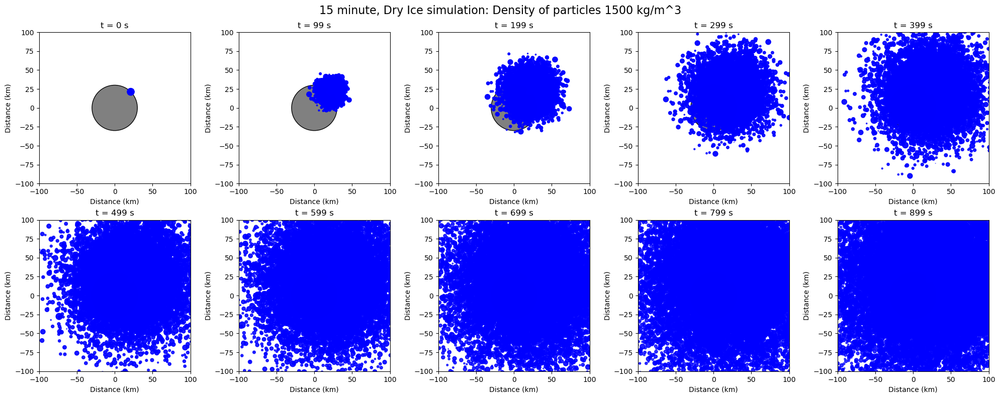

In [82]:
# Constants and comet properties
G = 6.67e-11                                 # Gravitational constant
nucleus_radius_km = 30                       # km
nucleus_radius    = nucleus_radius_km * 1e3  # m
nucleus_density   = 500                      # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3
nucleus_mass      = nucleus_density * nucleus_volume

# Escape velocity
# THe escape velocity can be calculated using the escape velocity equation. However, since we don't lnow the 
# exact value of the density for 29P, it is estimated that it is 25 m/s. This value was set after a meeting with 
# Dr Richard Miles, the most experienced person on comets and specifically 29P. 
v_escape = 25  # m/s

# Simulation parameters
n_particles         = 50000
simulation_duration = 15 * 60  # seconds
dt                  = 1
n_steps             = int(simulation_duration / dt)
n_snapshots         = 10
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)

# Rotation of nucleus
spin_period = 57 * 24 * 3600
omega_spin  = 2 * np.pi / spin_period

# Emission timing
emission_duration = simulation_duration
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.clip(np.random.normal(mean_d, sigma_d, n_particles), 1e-7, None)
r        = d / 2
rho_dust = 1500
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity and direction
# Ejected velocity is a Gaussian distribution with mean velocity of 100 m/s and maximum of 300m/s.
# After meeting with Dr Richard Miles, he explained why 300 m/s is the maximum velocity particles can have.   
v_eject   = np.clip(np.random.normal(100, 80, n_particles), 0, 300)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

# Optional fading
tau_base  = 3600
tau_eff   = tau_base * (d / mean_d)
snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        velocities[idx, 0] = np.cos(thetas) * v_vals
        velocities[idx, 1] = np.sin(thetas) * v_vals
        positions[idx]     = epic

    # Apply gravity to bound particles
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec     = positions[emi_idx]
        dist    = np.linalg.norm(vec, axis=1, keepdims=True)
        dist    = np.maximum(dist, nucleus_radius)

        acc     = -G * nucleus_mass / dist**3 * vec
        v_vec   = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound_mask.flatten()] = 0

        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # Record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    x_all = pos[:, 0] / 1e3
    y_all = pos[:, 1] / 1e3
    ax.scatter(x_all, y_all, s=marker_s, c='blue', alpha=alpha)

fig.suptitle("15 minute, Dry Ice simulation: Density of particles 1500 kg/m^3", fontsize=16)
plt.tight_layout()
plt.show()


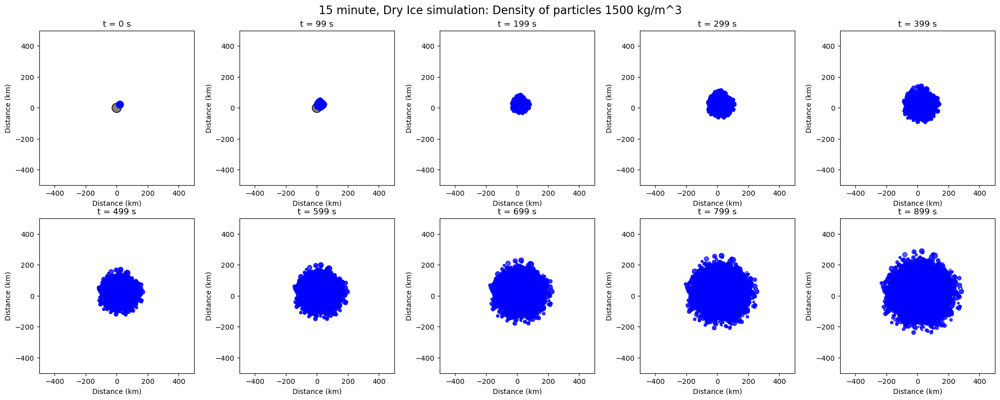

In [104]:
# Constants and comet properties
G = 6.67e-11                                 # Gravitational constant
nucleus_radius_km = 30                       # km
nucleus_radius    = nucleus_radius_km * 1e3  # m
nucleus_density   = 500                      # kg/m^3
nucleus_volume    = (4/3) * np.pi * nucleus_radius**3
nucleus_mass      = nucleus_density * nucleus_volume

# Escape velocity
# THe escape velocity can be calculated using the escape velocity equation. However, since we don't lnow the 
# exact value of the density for 29P, it is estimated that it is 25 m/s. This value was set after a meeting with 
# Dr Richard Miles, the most experienced person on comets and specifically 29P. 
v_escape = 25  # m/s

# Simulation parameters
n_particles         = 50000
simulation_duration = 15 * 60  # seconds
dt                  = 1
n_steps             = int(simulation_duration / dt)
n_snapshots         = 10
snapshot_times      = np.linspace(0, simulation_duration - dt, n_snapshots)

# Rotation of nucleus
spin_period = 57 * 24 * 3600
omega_spin  = 2 * np.pi / spin_period

# Emission timing
emission_duration = simulation_duration
emission_times    = np.random.uniform(0, emission_duration, n_particles)

# Particle size and mass
mean_d   = 1e-6
sigma_d  = 0.3e-6
d        = np.clip(np.random.normal(mean_d, sigma_d, n_particles), 1e-7, None)
r        = d / 2
rho_dust = 1500
m        = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity and direction
# Ejected velocity is a Gaussian distribution with mean velocity of 100 m/s and maximum of 300m/s.
# After meeting with Dr Richard Miles, he explained why 300 m/s is the maximum velocity particles can have.   
v_eject   = np.clip(np.random.normal(100, 80, n_particles), 0, 300)
theta_dev = np.random.uniform(0, 2*np.pi, n_particles)

# Initial arrays
base_angle = np.deg2rad(45)
positions  = np.tile([nucleus_radius * np.cos(base_angle),
                      nucleus_radius * np.sin(base_angle)],
                     (n_particles, 1))
velocities = np.zeros_like(positions)
emitted    = np.zeros(n_particles, bool)

snapshots        = []
snapshots_alpha  = []
times            = snapshot_times.copy()
snap_i           = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = base_angle + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        idx = np.where(new_emit)[0]

        thetas = theta_dev[idx]
        v_vals = v_eject[idx]
        velocities[idx, 0] = np.cos(thetas) * v_vals
        velocities[idx, 1] = np.sin(thetas) * v_vals
        positions[idx]     = epic

    # Apply gravity to bound particles
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec     = positions[emi_idx]
        dist    = np.linalg.norm(vec, axis=1, keepdims=True)
        dist    = np.maximum(dist, nucleus_radius)

        acc     = -G * nucleus_mass / dist**3 * vec
        v_vec   = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound_mask.flatten()] = 0

        velocities[emi_idx] += acc * dt
        positions[emi_idx]  += velocities[emi_idx] * dt

    # Record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, ax) in enumerate(zip(snapshots, snapshots_alpha, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    x_all = pos[:, 0] / 1e3
    y_all = pos[:, 1] / 1e3
    ax.scatter(x_all, y_all, s=marker_s, c='blue', alpha=alpha)

fig.suptitle("15 minute, Dry Ice simulation: Density of particles 1500 kg/m^3", fontsize=16)
plt.tight_layout()
plt.show()


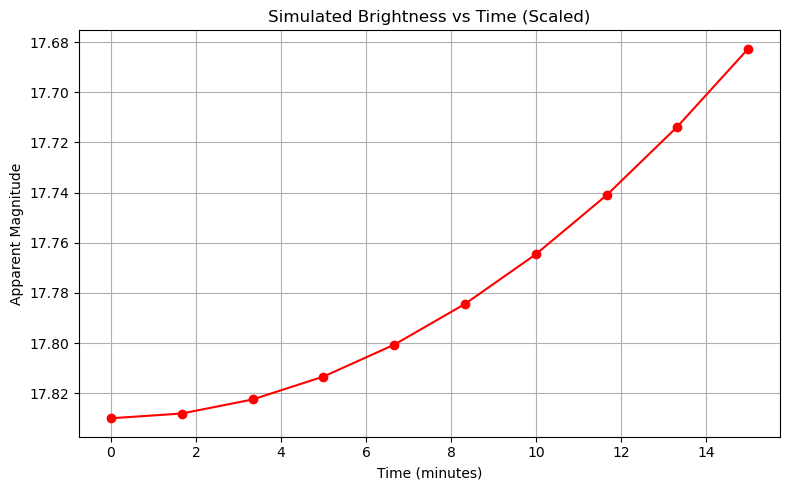

In [105]:
# Reflectivity
albedo = 0.3
areas  = np.pi * r**2
scale_factor = 1e9  # boost brightness to simulate larger particle population

# Brightness calculation
brightness = []
for alpha in snapshots_alpha:
    flux = np.sum(areas * alpha * albedo) * scale_factor
    brightness.append(flux)

brightness = np.array(brightness)

# Convert to magnitude scale
min_mag = 17.83  # baseline magnitude of comet without outburst
magnitude = 2.5 * np.log10(brightness / np.max(brightness)) + min_mag

# Plot magnitude vs time
plt.figure(figsize=(8, 5))
plt.plot(times / 60, magnitude, marker='o', color='red')
plt.gca().invert_yaxis()
plt.xlabel("Time (minutes)")
plt.ylabel("Apparent Magnitude")
plt.title("Simulated Brightness vs Time (Scaled)")
plt.grid(True)
plt.tight_layout()
plt.show()


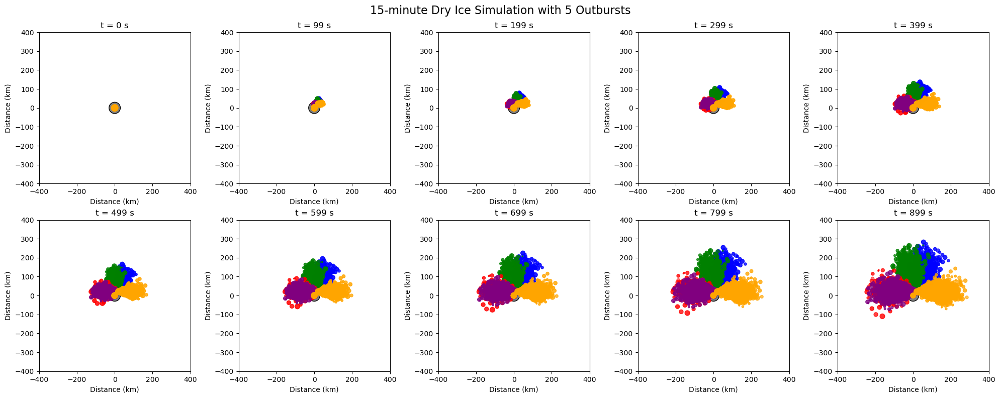

In [111]:
# Constants and comet properties
G = 6.67e-11
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3
nucleus_density = 500
nucleus_volume = (4/3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume
v_escape = 25  # m/s

# Simulation parameters
n_particles = 50000
n_outbursts = 5
particles_per_outburst = n_particles // n_outbursts
simulation_duration = 15 * 60
dt = 1
n_steps = int(simulation_duration / dt)
n_snapshots = 10
snapshot_times = np.linspace(0, simulation_duration - dt, n_snapshots)

# Rotation
spin_period = 57 * 24 * 3600
omega_spin = 2 * np.pi / spin_period

# Particle size and mass
mean_d = 1e-6
sigma_d = 0.3e-6
d = np.clip(np.random.normal(mean_d, sigma_d, n_particles), 1e-7, None)
r = d / 2
rho_dust = 1500
m = (4/3) * np.pi * r**3 * rho_dust
marker_s = 20 * (d / mean_d)**2

# Ejection velocity
v_eject = np.clip(np.random.normal(100, 80, n_particles), 0, 300)

# Emission timing
emission_duration = simulation_duration
emission_times = np.random.uniform(0, emission_duration, n_particles)

# Outburst directions (θ, φ)
outburst_angles = [
    (np.pi / 2 - 0.3, np.pi / 2 - 0.3),
    (np.pi / 2 - 0.3, np.pi / 2 + 0.3),
    (np.pi / 2, np.pi),
    (np.pi / 2 + 0.3, np.pi),
    (np.pi / 2, 0)
]
colors = ['blue', 'green', 'red', 'purple', 'orange']
particle_colors = np.empty(n_particles, dtype='U10')

# Initial arrays
positions = np.zeros((n_particles, 2))
velocities = np.zeros_like(positions)
emitted = np.zeros(n_particles, bool)

# Assign directional bias and color
theta_dev = np.zeros(n_particles)
for i in range(n_outbursts):
    idx_start = i * particles_per_outburst
    idx_end = (i + 1) * particles_per_outburst
    theta0, phi0 = outburst_angles[i]
    theta_dev[idx_start:idx_end] = np.random.normal(theta0, 0.2, particles_per_outburst)
    phi_dev = np.random.normal(phi0, 0.2, particles_per_outburst)
    vx = np.sin(theta_dev[idx_start:idx_end]) * np.cos(phi_dev)
    vy = np.sin(theta_dev[idx_start:idx_end]) * np.sin(phi_dev)
    velocities[idx_start:idx_end, 0] = vx * v_eject[idx_start:idx_end]
    velocities[idx_start:idx_end, 1] = vy * v_eject[idx_start:idx_end]
    particle_colors[idx_start:idx_end] = colors[i]

snapshots = []
snapshots_alpha = []
snapshots_color = []
times = snapshot_times.copy()
snap_i = 0

# Simulation loop
for step in range(n_steps):
    t = step * dt
    phi0 = np.deg2rad(45) + omega_spin * t
    epic = np.array([nucleus_radius * np.cos(phi0),
                     nucleus_radius * np.sin(phi0)])

    # Emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        positions[new_emit] = epic

    # Apply gravity to bound particles
    if emitted.any():
        emi_idx = np.where(emitted)[0]
        vec = positions[emi_idx]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc = -G * nucleus_mass / dist**3 * vec
        v_vec = velocities[emi_idx]
        speeds_sq = np.sum(v_vec**2, axis=1, keepdims=True)
        bound_mask = (0.5 * speeds_sq) < (G * nucleus_mass / dist)
        acc[~bound_mask.flatten()] = 0
        velocities[emi_idx] += acc * dt
        positions[emi_idx] += velocities[emi_idx] * dt

    # Record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        alpha_vals = np.exp(-age / tau_eff)
        snapshots_alpha.append(alpha_vals)
        snapshots_color.append(particle_colors.copy())
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plotting
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (pos, alpha, color, ax) in enumerate(zip(snapshots, snapshots_alpha, snapshots_color, axes)):
    ax.set_aspect('equal')
    ax.set_xlim(-400, 400)
    ax.set_ylim(-400, 400)
    ax.set_title(f"t = {int(times[i])} s")
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Distance (km)")
    circ = plt.Circle((0, 0), nucleus_radius_km, color='grey', ec='k', zorder=0)
    ax.add_patch(circ)

    x_all = pos[:, 0] / 1e3
    y_all = pos[:, 1] / 1e3
    for c in colors:
        mask = color == c
        ax.scatter(x_all[mask], y_all[mask], s=marker_s[mask], c=c, alpha=alpha[mask])

fig.suptitle("15-minute Dry Ice Simulation with 5 Outbursts", fontsize=16)
plt.tight_layout()
plt.show()


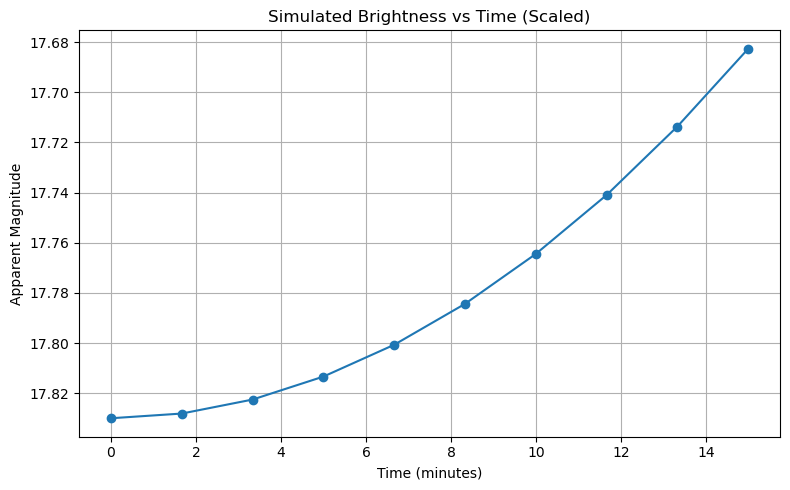

In [112]:
# Reflectivity
albedo = 0.3
areas  = np.pi * r**2
scale_factor = 1e9  # boost brightness to simulate larger particle population

# Brightness calculation
brightness = []
for alpha in snapshots_alpha:
    flux = np.sum(areas * alpha * albedo) * scale_factor
    brightness.append(flux)

brightness = np.array(brightness)

# Convert to magnitude scale
min_mag = 17.83  # baseline magnitude of comet without outburst
magnitude = 2.5 * np.log10(brightness / np.max(brightness)) + min_mag

# Plot magnitude vs time
plt.figure(figsize=(8, 5))
plt.plot(times / 60, magnitude, marker='o')
plt.gca().invert_yaxis()
plt.xlabel("Time (minutes)")
plt.ylabel("Apparent Magnitude")
plt.title("Simulated Brightness vs Time (Scaled)")
plt.grid(True)
plt.tight_layout()
plt.show()


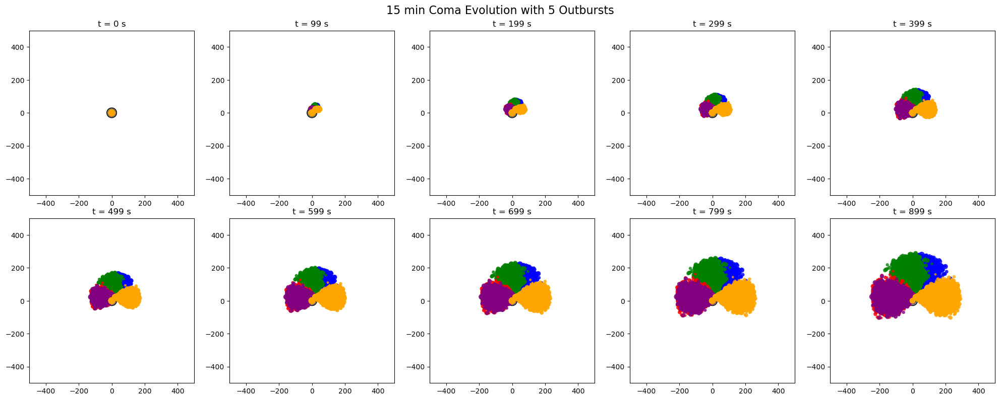

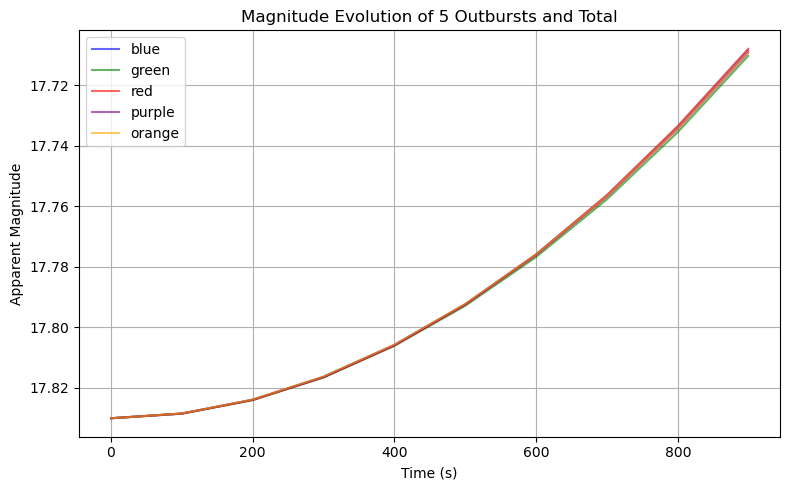

In [ ]:
# Comet & simulation setup
G = 6.67e-11
nucleus_radius_km = 30
nucleus_radius = nucleus_radius_km * 1e3
nucleus_density = 500
nucleus_volume = (4 / 3) * np.pi * nucleus_radius**3
nucleus_mass = nucleus_density * nucleus_volume

simulation_duration = 15 * 60   # 15 minutes in seconds
dt = 1
n_steps = int(simulation_duration / dt)
n_snapshots = 10
snapshot_times = np.linspace(0, simulation_duration - dt, n_snapshots)

spin_period = 57 * 24 * 3600
omega_spin = 2 * np.pi / spin_period

# Particles
n_particles = 1000000
n_outbursts = 5
ppob = n_particles // n_outbursts  # per‐outburst

# size distribution
mean_d = 1e-6
sigma_d = 0.3e-6
d = np.clip(np.random.normal(mean_d, sigma_d, n_particles), 1e-7, None)
r = d / 2
rho = 1500  # dry‐ice density (kg/m³)
marker_s = 20 * (d / mean_d)**2

# velocity distribution
v_eject = np.clip(np.random.normal(100, 80, n_particles), 0, 300)

# emission uniform over entire simulation
emission_times = np.random.uniform(0, simulation_duration, n_particles)

# fading timescale
tau_base = 3600
tau_eff = tau_base * (d / mean_d)

# Outburst geometry & colors
outburst_angles = [
    (np.pi/2 - 0.3, np.pi/2 - 0.3),
    (np.pi/2 - 0.3, np.pi/2 + 0.3),
    (np.pi/2      , np.pi     ),
    (np.pi/2 + 0.3, np.pi     ),
    (np.pi/2      , 0        )
]
colors = ['blue', 'green', 'red', 'purple', 'orange']
particle_colors = np.empty(n_particles, dtype='U10')

# initial arrays
positions = np.zeros((n_particles, 2))
velocities = np.zeros_like(positions)
emitted = np.zeros(n_particles, bool)

# assign direction & initial velocity per‐outburst
for i, (θ0, φ0) in enumerate(outburst_angles):
    i0, i1 = i * ppob, (i + 1) * ppob
    θ = np.random.normal(θ0, 0.2, ppob)
    φ = np.random.normal(φ0, 0.2, ppob)
    vx = np.sin(θ) * np.cos(φ)
    vy = np.sin(θ) * np.sin(φ)
    velocities[i0:i1, 0] = vx * v_eject[i0:i1]
    velocities[i0:i1, 1] = vy * v_eject[i0:i1]
    particle_colors[i0:i1] = colors[i]

# Run the simulation, record snapshots
snapshots = []
snapshots_alpha = []
snapshots_colors = []
snap_i = 0

for step in range(n_steps):
    t = step * dt

    # rotate emission epicenter
    φnuc = np.deg2rad(45) + omega_spin * t
    epic = np.array([
        nucleus_radius * np.cos(φnuc),
        nucleus_radius * np.sin(φnuc)
    ])

    # emit new particles
    new_emit = (~emitted) & (t >= emission_times)
    if new_emit.any():
        emitted[new_emit] = True
        positions[new_emit] = epic

    # gravity on bound particles
    if emitted.any():
        idx = np.where(emitted)[0]
        vec = positions[idx]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, nucleus_radius)
        acc = -G * nucleus_mass / dist**3 * vec

        vvec = velocities[idx]
        v2 = np.sum(vvec**2, axis=1, keepdims=True)
        bound = (0.5 * v2) < (G * nucleus_mass / dist)
        acc[~bound.flatten()] = 0

        velocities[idx] += acc * dt
        positions[idx] += velocities[idx] * dt

    # record snapshot
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(positions.copy())
        age = np.maximum(t - emission_times, 0)
        snapshots_alpha.append(np.exp(-age / tau_eff))
        snapshots_colors.append(particle_colors.copy())
        snap_i += 1
        if snap_i >= n_snapshots:
            break

# Plot particle snapshots (coma + nucleus)
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, pos, α, col_map, t in zip(
        axes, snapshots, snapshots_alpha, snapshots_colors, snapshot_times):
    ax.set_aspect('equal')
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_title(f"t = {int(t)} s")
    ax.add_patch(plt.Circle((0, 0), nucleus_radius_km,
                color='grey', ec='k', zorder=0))
    xkm = pos[:, 0] / 1e3
    ykm = pos[:, 1] / 1e3

    for c in colors:
        mask = (col_map == c)
        ax.scatter(
            xkm[mask], ykm[mask],
            s=marker_s[mask], c=c,
            alpha=α[mask], edgecolors='none'
        )

plt.suptitle("15 min Coma Evolution with 5 Outbursts", fontsize=16)
plt.tight_layout()
plt.show()

# Brightness & Magnitude curves
sun_flux = 1361    # W/m²
albedo = 0.3
area = np.pi * r**2
scale = 1e9        # boost factor for particle count

brightness = {c: [] for c in colors}

for α, col_map in zip(snapshots_alpha, snapshots_colors):
    for c in colors:
        mask = (col_map == c)
        F = sun_flux * albedo * area[mask] * α[mask]
        brightness[c].append(np.sum(F) * scale)

# build a total‐flux array (one value per snapshot)
total_B = np.zeros_like(snapshot_times)
for c in colors:
    total_B += np.array(brightness[c])

# convert summed flux → magnitude with the same zero‐point shift
min_mag = 17.83
total_mag = 2.5 * np.log10(total_B / total_B.max()) + min_mag

# tack it 
brightness['total'] = total_B
magnitude['total'] = total_mag

# plot total magnitude
plt.figure(figsize=(8,5))
# plot individual outbursts
for c in colors:
    plt.plot(snapshot_times, magnitude[c], label=c, color=c, alpha=0.6)

plt.gca().invert_yaxis()
plt.xlabel("Time (s)")
plt.ylabel("Apparent Magnitude")
plt.title("Magnitude Evolution of 5 Outbursts and Total")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



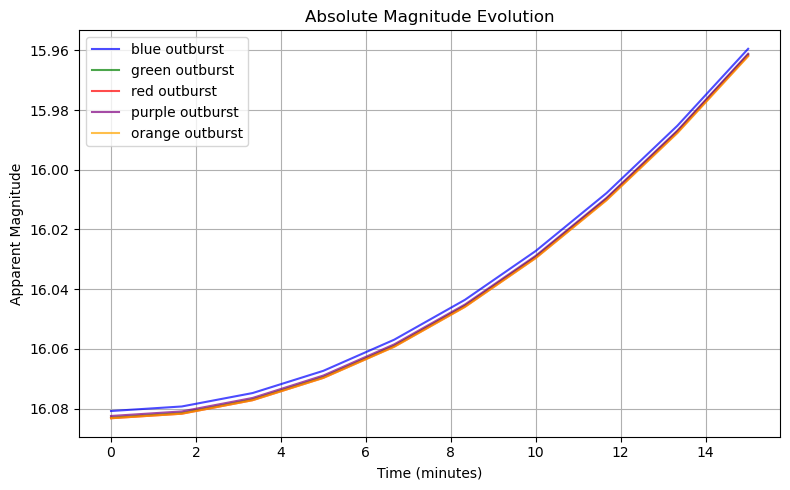

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. CONSTANTS & NUCLEUS
G      = 6.67430e-11       # m³·kg⁻¹·s⁻²
r_n_km = 30                # Km
r_n    = r_n_km * 1e3      # m
ρ_n    = 500               # kg/m³
vol_n  = (4/3) * np.pi * r_n**3
m_n    = ρ_n * vol_n

# 2. SIMULATION PARAMETERS
duration   = 15 * 60       # 15 min → s
dt         = 1             # s
n_steps    = int(duration/dt) + 1
n_snapshots = 10
snapshot_times = np.linspace(0, duration, n_snapshots)

# nucleus spin
spin_period = 57 * 24 * 3600   # s
ω_spin      = 2*np.pi/spin_period

# 3. PARTICLES & OUTBURSTS
N        = 1_000_000
M        = 5
ppob     = N // M

# size
d_mean   = 1e-6
d_sigma  = 0.3e-6
d        = np.clip(np.random.normal(d_mean, d_sigma, N), 1e-7, None)
r        = d/2
area_gr  = np.pi * r**2

# plotting marker size
marker_s = 20 * (d/d_mean)**2

# velocity
v_ej     = np.clip(np.random.normal(100, 80, N), 0, 300)

# emission times
emit_t   = np.random.uniform(0, duration, N)

# fading timescale
τ_base   = 3600
τ_eff    = τ_base * (d/d_mean)

# outburst geometry & colors
angles = [
    (np.pi/2 - 0.3, np.pi/2 - 0.3),
    (np.pi/2 - 0.3, np.pi/2 + 0.3),
    (np.pi/2      , np.pi     ),
    (np.pi/2 + 0.3, np.pi     ),
    (np.pi/2      , 0        )
]
colors = ['blue','green','red','purple','orange']
p_color = np.empty(N, dtype='U10')

# state arrays
pos     = np.zeros((N,2))
vel     = np.zeros_like(pos)
emitted = np.zeros(N, bool)

# assign velocities & colors per outburst
for i, (θ0, φ0) in enumerate(angles):
    i0, i1 = i*ppob, (i+1)*ppob
    θ = np.random.normal(θ0, 0.2, ppob)
    φ = np.random.normal(φ0, 0.2, ppob)
    vx = np.sin(θ)*np.cos(φ)
    vy = np.sin(θ)*np.sin(φ)
    vel[i0:i1,0] = vx * v_ej[i0:i1]
    vel[i0:i1,1] = vy * v_ej[i0:i1]
    p_color[i0:i1] = colors[i]

# 4. RUN SIMULATION & RECORD
snapshots       = []
snap_alphas     = []
snap_pcolors    = []
snap_i = 0

for step in range(n_steps):
    t = step * dt

    # rotating epicenter
    φn = np.deg2rad(45) + ω_spin*t
    epic = np.array([r_n*np.cos(φn), r_n*np.sin(φn)])

    # emit new grains
    new_emit = (~emitted) & (t >= emit_t)
    if new_emit.any():
        emitted[new_emit] = True
        pos[new_emit] = epic

    # gravity & free escape
    idx = np.where(emitted)[0]
    if idx.size:
        vec = pos[idx]
        dist = np.linalg.norm(vec, axis=1, keepdims=True)
        dist = np.maximum(dist, r_n)
        acc  = -G*m_n/dist**3 * vec

        v2 = np.sum(vel[idx]**2, axis=1, keepdims=True)
        bound = (0.5*v2) < (G*m_n/dist)
        acc[~bound.flatten()] = 0

        vel[idx] += acc*dt
        pos[idx] += vel[idx]*dt

    # snapshot?
    if snap_i < n_snapshots and t >= snapshot_times[snap_i]:
        snapshots.append(pos.copy())
        age = np.maximum(t - emit_t, 0)
        snap_alphas.append(np.exp(-age/τ_eff))
        snap_pcolors.append(p_color.copy())
        snap_i += 1

        if snap_i >= n_snapshots:
            break

# 5. MAGNITUDE CALCULATION
sun_flux = 1361       # W/m² @1 AU
albedo   = 0.3
scale    = 1e9

# pre-allocate
brightness = {c: np.zeros(n_snapshots) for c in colors}

for i, (α, cmap) in enumerate(zip(snap_alphas, snap_pcolors)):
    for c in colors:
        m = (cmap == c)
        F = (sun_flux * albedo * (area_gr[m]*α[m]).sum()) * scale
        brightness[c][i] = F

total_B = sum(brightness[c] for c in colors)

# zero-point so peak→17.83 mag
mag_ref = 17.83
ZP      = mag_ref - (2.5*np.log10(total_B.max()))

mag   = {c: 2.5*np.log10(brightness[c]) + ZP for c in colors}
mag['total'] = 2.5*np.log10(total_B) + ZP

# 6. PLOTTING MAGNITUDES
plt.figure(figsize=(8,5))
for c in colors:
    plt.plot(snapshot_times/60, mag[c],
             label=f"{c} outburst", color=c, alpha=0.7)

plt.gca().invert_yaxis()
plt.xlabel("Time (minutes)")
plt.ylabel("Apparent Magnitude")
plt.title("Absolute Magnitude Evolution")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
